# 如何排查 GRPO 训练问题
- https://zhuanlan.zhihu.com/c_1419455237367623680

本系列文章会分享 GRPO 排查的经验。以及我作为面试官，考查 post-training 方向候选人时，<font color='red'>是如何判断对方是否有对应的能力</font>。

我不喜欢问固定的八股文，或者为难候选人手撕代码。而是更倾向于从具体案例中提问题，比如<font color='red'>让候选人分享一个训练出问题的案例，然后逐渐 dive deep，判断他有多少经历是编造的</font>，例如：

  - <font color='red'>遇到的是策略坍塌，还是训练崩溃？当时看到的情况是什么，查到了什哪些东西？</font>

**这类问题有意思的地方是每个人切入的角度都不太一样。**
- 有人从曲线角度入手，先分析哪几条指标先动了；
- 有的人先看数据，提到其实是样本有问题；
- 还有的从算法机制本身着手，**直接讲 GRPO 的目标函数天生往哪个方向偏**。

不论是哪个角度，经历过的人，最后通常都会聊到类似的内容。
- <font color='red'>比如提到组内 reward 没有方差、两侧算出来的概率对不上、或者某个指标看着正常但其实没有意义。</font>
- <font color='blue'>审视的角度和方式不同，落点却都大差不差，可以说是殊途同归。</font>

反过来，纯背八股，抄别人项目经历的人也比较类似，都喜欢说自己用 DAPO 或者 XXPO 里某个优化解决了某个问题，<font color='red'>但是回答不了各种追问：</font>
- 这个具体问题是怎么发现的？
- 在哪条曲线上看到征兆的？
- 当时怎么决定改哪个？
- 改完之后又遇到了什么新问题？

这个差距是无法在知识量上弥补的，没有经验，遇到类似问题也很难解决。

所以，这个系列我会按照自己遇到问题的时候，排查的顺序逐步展开，从我自己的角度分享，训练出问题时怎么修，逐步深入。

<font color='red'>这一篇我先分享最开始的一层：问题分类</font>

这个系列**主要讨论模型本身的排查**，不会涉及到reward model 或者 LLM judge 的排查，如果大家感兴趣，我未来也可以出一个相关的系列。


## 排查问题的基础要求
不管是从哪个角度开始排查，我们真正要关心的有三件事。

1. 先分类再动手。

  - <font color='red'>**策略坍塌**和**训练崩溃**是两类完全不同的问题。</font>
     - 这两类问题的解决方式差异很大，不可以混为一谈。

2. 要有observability 的意识。

  - 你有没有监控，监控了什么？
      - 更关键的是：<font color='blue'>你改了某个配置让指标动了，但你怎么知道是这个配置起了作用，还是恰好这批数据不一样？</font>

3. 如何分析每个方案的代价。

  - 直接叠上各种 PO 试图解决问题，并不是专业的做法。<font color='red'>每个 trick 都有它自己的适用前提，叠在一起用，连是哪个在起作用都分不出来。</font>

## 问题分类
在训练出问题的时候，我会区分问题到底是下面的哪一类：



In [1]:
from IPython.display import Image

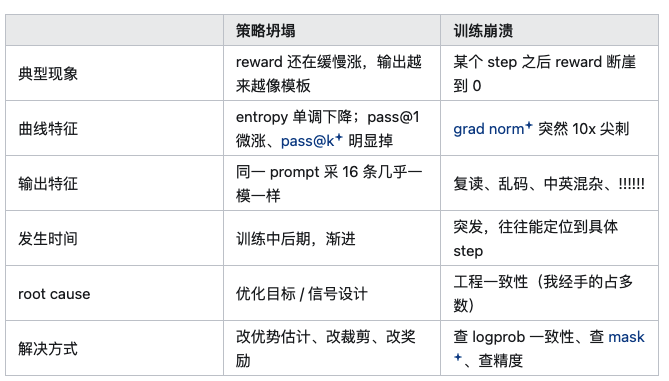

In [2]:
Image(filename='./Image/q_classification.png')

两者的解决方式差异很大。
- **策略坍塌**主要是算法层的问题，(算法决定了前进的方向)
  - 它是 GRPO 这个目标函数本身的内在倾向——**你什么都没做错，它也会往那个方向走**。

- **训练崩溃**<font color='red'>通常都是在工程层</font>：
  - 训练侧和采样侧算出来的概率不一致、
  - loss mask 的覆盖范围写错了、
  - bf16 精度不够导致数值失真。
  <font color='red'>这类问题调超参永远调不好，因为它压根不是超参问题，而是 bug</font>

## 进一步区分
现实世界是复杂的，这个二分法只是粗略的总结，不够严谨。所以不要只看这个表格来定位问题，下面我来解释原因。

### 问题的相互转化
<font color='red'>同一个现象，背后可能有多种原因在同时起作用</font>。一个比较常见的链路是这样的：

In [ ]:
熵先一路掉到底
   ↓
每个位置只剩一个答案
   ↓
输出开始退化成复读
   ↓
reward 断崖式暴跌

我们在最后一步看到的结果，很可能归因于训练崩溃，但病根其实在第一步策略坍塌。

反过来说，<font color='red'>**坍塌的成因里往往还混着 reward 设计、一批数据被反复用了多轮，这些也都不是纯算法的问题。**</font>

所以我们要做的不是确定这是策略坍塌还是训练崩溃。而是例如：
- <font color='green'>先按训练崩溃去查工程，因为工程层的问题要么有要么没有，等排除干净之后才轮到策略坍塌类。</font>(详细解释见：排查顺序)

<font color='red'>从这个角度，如果你能在面试中，主动指出这两类会互相转化，会是一个很大的加分项。</font>



### 时间尺度 vs root cause（根本原因）
有一个理解起来比较绕的事情：
- 从时间尺度上看，模型坍塌是**渐进式的**，而训练崩溃是**突发式的**。
- 而从 root cause 角度，模式坍塌的 优化目标 / 信号设计，和训练崩溃的工程一致性，跟渐进式还是突发式并不是一一对应。这个理解起来有点绕，我可以举个例子：

- **有效样本数退化是渐进的**（几十步的过程），但病根其实在工程和系统层（异步、数据陈旧）。所以，虽然符合策略坍塌的渐进 + 中后期特征，但并不是要去查优化目标，而是工程层。 
- 多轮工具调用崩溃，属于训练崩溃，但通常表现为突发的 grad norm 爆炸，但病根其实在信号设计（<font color='red'>工具返回的内容把分布带偏，逐轮复合</font>），而不是 mask 或者精度问题。

### 一个进阶的切法是用下面四问，<font color='green'>按照信号链来区分</font>：

1. 梯度是不是和我认为的 match？ 两侧 logprob 一致性、loss mask 覆盖范围、梯度累积等价性。
2. reward 是不是在测我认为它在测的东西？ 分项拆解、验证器的 false negative、和训练不同源的 held-out。
3. 这一步的更新是几条样本在决定？ 有效样本数、零方差组占比。
4. 策略还在看题吗？ 组内去重、跨输入的可区分度、pass@k。

<font color='red'>这个方式区分，可以确保每一层之间是前提关系</font>，而不是并列关系。 第 1 层不通过，后面三层的所有观测都没有意义；第 2 层不通过，第 3、4 层是在精确地优化一个错的东西。

这个切分方式，可以理解二分法给不出的依赖结构，因为渐进和突发之间没有前提关系。

#### 信号链 debug 法
核心思想是：
- 与其把一堆监控指标并列铺开、看哪里红了就修哪里，不如沿着"奖励信号如何变成权重更新"的物理路径，把它切成四层，每层是上层的前提条件（prerequisite），下层通过之前，上层的观测全是垃圾。

##### 为什么是"信号链"而不是"指标面板"
RL 训练的更新可以抽象成一条链：

reward 数值 → loss 怎么加权/遮蔽 → 梯度 → 参数更新 → 下一轮的 policy

传统的 debug 方式是把 pass@1、reward 曲线、loss 曲线、KL 等几十个指标画在一张 dashboard 上。问题在于这些指标隐含着不同的假设：
  - 看 reward 曲线，隐含假设"reward 真的在测你想测的东西"；
  - 看 loss，隐含假设"梯度没被算错"；
  - 看 pass@k，隐含假设"模型还在正常读题、不是背答案"。
如果第 1 层的假设破了，后面所有指标的数字看起来再正常也只是巧合——或者说，你在精确地优化一个错误的东西。所以正确的做法是像走流水线质检一样：第 1 层不过，后面的全部停线，修完再往下走。

##### 四层逐一解释
###### 第 1 层：梯度是不是我认为的 match？

- 问题：喂进 optimizer 的梯度，真的等于"用我认为的方式加权这批样本"得到的梯度吗？
三个检查点：
  - 两侧 logprob 一致性：在 on-policy 的 actor-learner 分离架构（如 GRPO 的 vLLM rollout + trainer 前向）里，rollout 端采样的 logprob 和训练端重算的 logprob 必须一致。不一致通常来自 KV cache 精度差异、bf16 舍入、EOS/特殊 token 处理不同、采样时的并行误差。PPO/GRPO 里 advantage 是用采样时的 logprob 算 importance ratio 的，这个比值一旦带噪，梯度整体偏移。
  - loss mask 覆盖范围：prompt token 应该被 mask 掉，completion token 应该全保留。一个差一行的 off-by-one（比如把第一个生成 token 也 mask 了，或者把特殊 token 漏掉）不会报错、loss 曲线甚至看起来还降，但梯度的语义完全变了。
  - 梯度累积等价性：多步 micro-batch 累积时，sum vs mean 的归一化、不同 batch 大小下的 loss scaling、GRPO 里按 group 归一化但被跨 micro-batch 切开，这些都会让"等效 batch size"和实际不一致。
  
过不了意味着什么：梯度数学上是错的。此时第 2 层"reward 对不对"根本无从谈起——你连自己在优化哪个数学对象都不确定。

###### 第 2 层：reward 是不是在测我认为它在测的东西？
- 问题：拿到的 reward 分数，真的对应"我想要的能力"吗？

三个检查点：
  - 分项拆解：大多数 reward 是多个子项加和（正确性、格式、长度、风格、重复惩罚等）。总分涨了，可能是格式项把所有噪声都吃掉了，而正确性项原地踏步。必须把曲线拆开看，并且拆开做消融。
  - 验证器 false negative：rule-based verifier / 判分模型会系统性冤枉正确答案（比如答案是 "0.5" 而标准答案是 "1/2"；或者代码题里等价但不同实现的输出）。reward 的方差里混着测量噪声，模型学到的是"迎合判分器的怪癖"，而不是提升能力。
  - 与训练不同源的 held-out：训练集上的 reward 涨不代表泛化。要用一个判分逻辑不同源的 held-out 集（不同验证器、人工标注、或换分布的题）交叉验证，否则就是在过拟合 verifier。
  
过不了意味着什么：你在精确地优化一个错的目标。此时第 3 层"有效样本数有多少"无意义——样本再多、方差再低，方向也是错的。


###### 第 3 层：这一步的更新是几条样本在决定？
- 问题：这个 batch 里，真正对梯度有贡献的有效样本有多少？
两个检查点：
  - 有效样本数：一批 rollout 里，如果大多数样本的 advantage ≈ 0（比如 GRPO 里整组全对或全错，组内 reward 零方差），它们对梯度贡献为零。标称 batch size 1024，实际有效样本可能只有 40。样本效率极差，且有效样本的分布和名义分布不同，引入 selection bias。
  - 零方差组占比：这是上一点的结构化统计。要单独监控"全对组 / 全错组"的比例，它同时反映两件事情：难度配比是否合适（太简单的题全对、太难的题全错，都不产生信号），以及 reward 是否饱和/失效。
  
过不了意味着什么：优化方向对了，但几乎是由噪声或小样本决定的，第 4 层看到的 pass@k 波动可能只是抽样抖动，无法归因。

###### 第 4 层：策略还在看题吗？
- 问题：模型是在"读懂题目再作答"，还是已经退化到"看到某些表面模式就套模板"？
三个检查点：
  - 组内去重：同一 prompt 采 k 条，如果输出高度重复（n-gram 重合率、logprob 坍缩），说明策略熵塌缩，模型早就停止探索，后面采再多样也只是同一个答案。这也是 GRPO 等算法后期训练发散/僵死的常见原因。
  - 跨输入的可区分度：对语义上等价但表面不同的题（改数字、改措辞），模型是否给出一致的行为？如果模型对"表面相似但题意不同"的题给出同样的答案，说明它在做 pattern matching 而非理解。这是一个粗粒度但便宜的忠实性（faithfulness）探针。
  - pass@k：随 k 增大，pass@k 是否显著高于 pass@1。如果 pass@1 ≈ pass@k，说明模型并非"会做但采不到"，策略已经把概率质量集中到少数路径上——结合组内去重，基本可以确认坍缩。

##### 为什么"层与层之间是前提关系"这句话最重要
原文的逻辑链条是这样的：
1. 第 1 层不通过 → 梯度算错了 → 第 2 层"reward 对不对"无从判断（你连梯度里装的是什么都不知道），第 3、4 层的所有统计更是建立在错误更新之上的二次噪声。
2. 第 2 层不通过 → 目标就是错的 → 第 3 层"用多少样本"是在为一个错误目标精确找最优解，第 4 层"策略有没有在读题"的观测也同样失真。
3. 第 3 层不通过 → 有效信号太少 → 第 4 层区分不了"模型真懂了"还是"几条幸运样本抖出来的"。

这对应一个排障顺序：自上而下。看到训练效果差，不要第一反应去调 reward、调数据配比，而是先写个单测验证梯度实现，再拆解 reward 分项，再看零方差组占比，最后才讨论策略行为。反过来，如果第 1、2、3 层都干净，第 4 层的异常（如 pass@1 ≈ pass@k、组内重复率飙升）才是有诊断价值的信号。
我的二分法在多数情况下适用，但一些复杂情况，可以按照我讲的这个方式来分类。

## 最常见的错误排查方式
### 1
缺少经验的候选人，回答问题时，比较常用一类的回答，例如：“训练崩溃之后，把 lr 从 xxx 降到 yyy 就好了。”

降 lr 肯定有效，因为它把所有事情都拖慢了，包括 bug 本身。原来几百个 step 就爆的，现在几千个 step 才爆。如果你的训练本来只跑几千个 step，那你可能会以为问题解决了。<font color='blue'>这不是修好了，而是把爆炸推迟到了你的视野之外</font>

这个方法不是没用，把降 lr 当成诊断手段是完全没问题的。可以用它去区分到底是信任域太大，还是代码里有 bug，这是个合理的二分实验，<font color='blue'>信任域问题会随 lr 线性缓解，bug 不会</font>。但是不能把它解决问题的最终解释。

### 2
类似的回答还有：加大 grad clip 的力度、把 warmup 拉长、把 batch size 翻倍。它们都能让曲线看起来变好，<font color='blue'>因为它们都在降低单步的实际更新量</font>。
- 判断标准很简单：<font color='blue'>如果你的修复手段是「让每一个 step 走得更小」，那你大概率没有定位到根因，只是把它稀释了。</font>

## 我怎么快速判断
前面讲了为什么要分类，快速分类的方法，其实很简单：<font color='blue'>抓崩溃前后各 10～20 条 rollout，人工一条条读一遍。</font>这一步第一步。

可以在 rollout 原文轻松发现是不是这三类问题：

- reward hacking：<font color='blue'>输出结构完整、格式漂亮，但内容在绕开真正的任务</font>。比如该解题的地方在复述题干、<font color='red'>该给答案的地方给了个模板化的推理过程</font>
- 大量截断：回答在句子中间断掉，JSON 没闭合，推理写到一半没了。
- 乱码 / 复读：!!!!!!、同一个短语重复几十遍、中英混杂到读不通。
<font color='blue'>而这三类在 reward 曲线上可能都只表现为掉到 0。从曲线上看，不如直接看原文。</font>

## 总结
- **先分类，再动手**。 坍塌和崩溃的排查路径完全不同，混着查等于两边都查不干净。
  - 顺序是固定的：<font color='blue'>先排工程层，因为它是 0/1 的；排干净了再动算法层。</font>

- **分类法本身也要能被质疑**。 我这个二分是按时间尺度切的，它有用但不严谨。
  - 按信号链切（font color='blue'>梯度对不对 → reward 在测什么 → 几条样本在决定 → 还看不看题</font>）更严格，因为这四层之间是前提关系。

- **降 lr 是诊断，不是解释**。 更一般地说：任何「让每一步走得更小」的手段，都只是在稀释根因。

- **读原文在读曲线之前**。 三分钟的人工阅读能完成的分类，曲线上要花半小时，而且还可能分错。

# GRPO如何监控模型的多样性？

本系列文章会分享 GRPO 排查的经验。以及我作为面试官，考查 post-training 方向候选人时，是如何判断对方是否有对应的能力。

上一篇文章中，我讲了策略坍塌和训练崩溃是两类不同的问题，为什么要先分类再动手，以及如何分类。这篇讲怎么发现问题，具体要监控什么。

网上的文章，在分享 GRPO 优化时，通常会分析上 clip-higher 的作用，或者加 dynamic sampling 的价值。但更值得问的是前一步：作者当时<font color='red'>看到了什么，才决定用这个的？</font>

GRPO 是没有 critic 的，唯一的学习信号来自同一个 prompt 采出来的一组回答间的相对优势。
- 也就是说，信号本身的健康度是可以直接观测的，所以也必须观测。 
- 如果一组里所有回答的 reward 都一样，那这一组压根没有信号，而这件事完全可以在曲线上看见，不需要猜。

## 监控指标我分两组讲。
- 这篇专注讲解**多样性**这一组，也就是模型还会几种解法、还在不在探索。
- 后面会讨论**另一组信号健康度与一致性**。

这一组有个共同的陷阱：它们看起来在测同一件事，其实漏掉了一整个维度。 这个我也会在后面的文章中详细展开。

## token entropy：模型还有多少不确定性
每生成一个 token 时，模型对整个词表输出一个概率分布，这个分布的熵就是该位置的 token entropy，可以对熵取平均。
  - **它的含义**：熵高说明模型在这个位置还在犹豫，好几个候选词概率都不低；熵低说明它已经很确定了。

  - **正常什么样**：<font color='red'>训练过程中它应该缓慢下降</font>。这是正常的，模型本来就是在变得更确定。

  - **危险信号**：下降速度很快，并且一路趋近 0。这时候模型对每个位置都只有一个答案，**采 16 条会得到 16 条一样的东西，探索彻底停止。**

### 但这个指标并没有大家理解的那么有价值。

  - 第一，<font color='red'>取过平均的 token entropy 稳住了其实什么都证明不了</font>。具体原因会在下面第四节展开来讲。

  - 第二，熵下降本身并不是问题。任何一次有效的 RL 都会让熵下降，这就是策略在锐化，是它该做的事。所以拿“熵在降”当坍塌的证据是不可证伪的，因为它同时也描述了健康的训练。我真正看的是下降的速率，以及同期 pass@k 有没有跟着掉。

  - 第三，更 tricky 的是，它掉到接近 0 也不能直接确诊坍塌。<font color='red'>熵低但模型对不同题还给不同的推理，是在压缩，不是坍塌，模型可能反而非常稳定</font>。而最坏的情况下，对所有题写类似的话术，熵反而是高的。具体的我会在第五节讲透。

所以我把 token entropy 放在第一个讲，只是因为它好观测、每个 step 都有。但是 token entropy 顶多算个粗糙的报警器，不是判据。

顺便回答一个常见问题：熵是不是越高越好？ 
- 不是。熵过高的时候模型答案不稳定、难收敛，甚至连正确的输出格式都保不住。要维持的是一个目标区间，而不是一个方向。

## 组内去重率：16 个答案里实际有几个不一样
GRPO 对每个 prompt 采一组回答，<font color='red'>把这一组做个去重，看还剩几条，就是组内去重率</font>。

  - **为什么要看它**：这是熵坍塌最直观的表现。平均熵是把成千上万个 token 位置糊在一起的数字，很不敏感；而 16 条采样去重后只剩 2 条，是一眼就能看懂的。

  - **危险信号**：<font color='red'>去重后的条数持续下降。降到 2 到 3 条基本就是坍塌了，因为 GRPO 的梯度来自组内比较，组内都一样了，就没有任何可比的东西。</font>

严格的去重可以换成编辑距离的分布。完全字符相同的情况其实不多，更常见的是「结构一模一样、只有几个数字不同」。看编辑距离的中位数比看去重条数更灵敏一点。


## pass@k：能力上限有没有变窄
对同一道题采 k 条回答，只要其中有任意一条做对就算通过。
- pass@1 是采一条就对的比例，
- pass@k 是采 k 条里至少一条对的比例。

  - <font color='red'>为什么这个指标最关键</font>：
    - pass@1 衡量的是模型最擅长的那条路走得多准，
    - 而 pass@k 衡量的是<font color='red'>模型总共还会几种解法</font>。
    - RL 很容易把前者提上去、同时把后者压下去，**因为它做的事情是把已有的某一条路径的概率推高，代价是别的路径被压没了**。

  - 危险信号：pass@1 在涨，但 pass@k 在跌，尤其是跌到低于 base model。<font color='red'>这说明这一轮 RL 没有教给模型新东西，只是把它变窄了。</font>

把 base model 和 RL 之后的模型放在同一张图上，**随着 k 变大，两条线会交叉**：

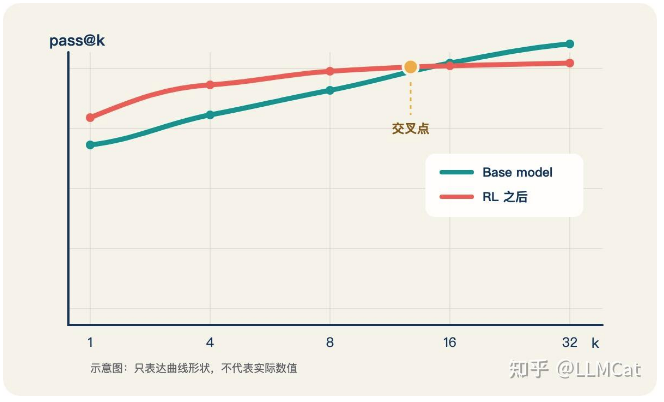

In [3]:
Image(filename='./Image/base_rl.png')

- 两条线都是往上走的，因为 k 越大、采样越多，命中的机会只会增加不会减少。
- 区别在形状：
  - RL 之后那条很快就见顶了，因为它只会一条路，采再多也是同一条；
  - base model 那条会一直往上爬，<font color='red'>因为它还留着好几种解法，多采就有机会撞到</font>
    - 所以左半边 RL 明显更好，这就是 pass@1 上看到的提升；
    - <font color='red'>但两条线会在某处交叉，k 再大一点 base model 反而更高</font>
    
交叉点具体在哪取决于任务和模型，上图只是示意形状，不是可以照抄的数值。


### 如何取 k 取多少
我的做法是 k 就取 group size，最简单。

- GRPO 训练时每个 prompt 本来就要采一组，我这边是 16 条，那 pass@16 直接从这批 rollout 里算出来就行，不额外花一分钱算力，每个 step 都有。这是我最常看的一条曲线。

- 评测集上我会另外跑一次，采到 32 条封顶。我没做过更多的，因为收益不明显，而成本是线性涨的。**很多论文里的 k 采到几百上千，是为了把曲线画完整，日常调模型没必要，也没那个预算**。当然，代价是只能看见比较严重的坍塌。

- 我最近见过一次反超在 pass@16 上。这一轮的坍塌比较严重，<font color='red'>组内 16 条去重只剩 2 条</font>，pass@1 涨了几个点，但 pass@16 比 base model 低，交叉点落在 8 到 16 之间。所以不用等到大 k，坍塌够狠的时候小 k 就能看出来。
  - 但反过来的推论不成立：在 pass@16 上看不出差别，不代表没问题，只代表没严重到这个预算能看见的程度。

### 曲线的 3 个 gap
在看曲线时，要注意下面3点： 
  - ・训练 prompt 不是评测集。 rollout 是在训练 prompt 上的，它们正在被训练，pass@16 天然被污染、通常会偏高。 
  - ・每个 step 的题不一样。 每个 step 的 batch 是不同的题，逐 step 之间的波动很大一部分是题目难度组成的抖动，不是策略变化。这条曲线跨 step 不可直接比，除非固定一个 probe 集。 
  - ・如果开了零方差组过滤，这个数被系统性压低了。 过滤会把全对的组剔掉，于是算 pass@16 的那个子集里正确率天然更低，而且随着训练推进（全对组占比上升）持续下漂。你会看到一条自己造出来的、像坍塌的下降曲线。要算就在过滤之前算。

#### 我的做法：
- rollout 上的曲线，只当同 batch 内的相对信号看趋势；
  - 如果真的要和 base 比，需要另外固定一个几十道题的 probe 集，每隔一段时间两个模型各按自己调好的 temperature 跑一次。

### temperature 也要考虑在内
base 和 rl 两个模型的最优 temperature 不一样，但哪一边更高没有普适规律。

- <font color='red'>有些测量显示 base 的表现在 temperature 超过 1.0 之后就开始掉</font>，
- <font color='blue'>而 RL 之后的模型对 temperature 反而不敏感</font>
- 机制上也支持这个方向，<font color='red'>RL 把分布锐化了、熵更低，要恢复同等有效熵得给 RL 那边加 temperature，而 base 本来就散。</font>

我还遇到过完全反过来的情况，我没法给出原因：
- 一开始拿训练时的 temperature （0.8）同时评两个模型，看着 RL 后完胜；
- 后来给 base 单独调到 1.0，差距立刻缩小了一截。

所以我没法把它总结成规律，只能总结成一条经验：

- 只对比 pass@k ，不扫 temperature等于没比；
- 而且两边必须各自扫一遍temperature、各取自己的最优点再比。
只要用训练时那个temperature同时评两个模型，这个比较就天然偏向 RL，因为那个temperature是 RL 训出来的工作点。

## 只在高不确定性位置统计的熵
第一节提到过，<font color='red'>平均熵很弱</font>，这一节展开讲讲为什么，以及一个部分的补救。

<font color='red'>平均 token entropy 是个被稀释得很厉害的指标</font>。
  - <font color='blue'>一条长回答里，绝大多数 token 是语法、连接词、格式符号，这些位置的熵天然就不低、而且基本不变。</font>

  - 真正决定解题路径的其实是<font color='red'>少数几个分叉 token</font>：
    - 选哪种方法、要不要回头验算、用哪个公式。这几个关键 token 完全确定化了，对平均熵的影响可能都不到 1%，但序列级的多样性已经死了。

所以一个直接的改法是：
  - 只统计那些 top-1 概率低于某个阈值的位置的熵，绕开被格式 token 稀释的问题。

这个指标也有个问题：
- 它的条件集会随着策略锐化而不断收缩。策略越确定，符合「高不确定性」条件的位置就越少，极端情况下集合变空、数值就没意义了。所以它跨 step 不能直接比较。

我的解决办法有三个：

1. 用一个固定的位置集，比如拿一个冻结的参考模型一次性选定，之后一直用这批位置。
2. 把集合大小和数值一起报，看到集合在缩就知道数值不可比了。
3. 用分位数而不是绝对阈值（比如每个 batch 取熵最高的 20% 位置），这样集合大小恒定。<font color='red'>这个第三种最简单，很多框架也内置了这个选项。</font>

## 五、跨输入的可区分度
这一节最重要，因为前面四个指标都只看了“同一道题”，没有看“换一道题”。“答案不重复”和“答案贴合题目”不是一回事。
题内多样性指的是:
- 同一道题采样N次，有多种解法。
- 而跨题可区分度:
  - 指的是换一道题，推理是否也跟着换。这一章节，会从这个角度展开。

先想两个模型：

- 模型 A：同一道题采 16 次，<font color='red'>答案几乎一样</font>；但题目一换，它会立刻换公式、换推理路径。这个模型可能只是变得更确定、更简洁，不一定坍塌。
- 模型 B：同一道题采 16 次，<font color='red'>每次措辞都不一样，看起来很有多样性</font>；
  - **但无论问数学、代码还是逻辑题**，<font color='blue'>它都用同一套开场、自我检查和收尾</font>。这个模型看似热闹，实际上已经模板化了。

前四节的平均熵、组内去重、pass@k 和条件熵，<font color='red'>主要能区分“同一道题多采几次，答案像不像”</font>。它们不擅长区分模型 A 和模型 B，因为缺了另一个问题：<font color='red'>换一道题，推理会不会跟着换？</font>

### 先把两个维度分开
可以把它们理解成两根互不替代的指标：

- **题内多样性**：
  - 固定一道题，重复采样时能得到多少种不同答案。
- **跨题可区分度**：
  - <font color='red'>换成不同题目后，模型的推理内容是否也明显不同</font>。

用信息论记号写:
- 题内多样性是 H(Z | X)；
- 跨题可区分度对应 I(X:Z)。

如果不熟悉这两个公式，可以先跳过。真正要记住的只有一句：
  - <font color='red'>“同一道题的答案不重复”，不等于“答案真的根据题目而变化”</font>
  
它们之间满足：
H(Z) = I(X ; Z) + H(Z | X)

这条公式想说的是：
- 我们看到的总体变化，既可能来自同一道题有多种解法，也可能来自<font color='red'>不同题目触发了不同推理</font>。只盯着前一部分，就会漏掉“所有题都套同一模板”的坍塌。

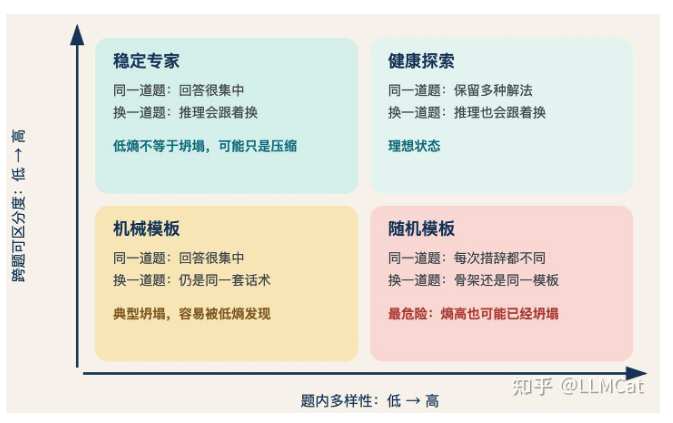

In [4]:
Image(filename='./Image/entropy_reason.png')

这里最反直觉的是右下角：
- 模型每次都换几个词，所以熵不低、去重率也正常；
- <font color='red'>但它对所有题都沿用同一个推理骨架。这是高熵也会坍塌的原因</font>。

反过来，左上角虽然熵低、同一道题的回答也很集中，<font color='blue'>但每道题仍然会触发对应的推理</font>。它更像是在压缩表达，而不是失去能力。

### 怎么测：让回答“找回自己的题目”
这个指标可以用一个很直观的小测试来算。

假设一个 batch 里有 P 道题，每道题都已经生成了回答。对其中一条回答，分别计算：

  - 它放回自己的题目后面时，模型给出的 logprob；
  - 它放到另外 P-1 道题后面时，模型给出的 logprob。
如果模型真的根据题目组织推理，那么“回答 A + 题目 A”的匹配分数应该最高。把每条回答都这样测一遍，统计它能否找回自己的题目，就是这里的检索准确率。

  - 准确率高：不同题目的推理确实有区别，输入依赖还在。
  - 准确率接近 1/P：和随机猜题差不多，说明回答已经很难看出是为哪道题写的，模板化很严重。
这项检查可以复用训练时已经生成的 rollout，不需要再采样；主要成本是补一次前向计算。

### 为什么零方差组会让模板化更严重
当一组回答的 reward 都一样时，任务本身几乎不给模型“这道题应该怎么改”的方向。可 KL、entropy bonus 等正则项仍然会产生更新，而且这些更新更像一种对所有输入都通用的推力。

于是这一 step 里，模型收到的主要不是“题目 A 应该这样答、题目 B 应该那样答”，而是“不管什么题，都统一往这个方向调一点”。如果零方差组很多，这种输入无关的更新会反复累积，不同题目之间原有的差异就会被慢慢抹平。

这也解释了第一节的反常现象：

- 熵低，但检索准确率高：<font color='blue'>模型更确定了，不过仍然会看题下菜，通常是健康压缩</font>
- 熵高，但检索准确率接近随机：<font color='red'>模型的用词很多变，**却对所有题套同一个骨架**，这是更隐蔽的模板坍塌。</font>

所以平均熵不只是“不能单独报平安”，它有时连报警方向都可能相反。<font color='blue'>必须把题内多样性和跨题可区分度放在一起看。</font>

顺便说一句，这一节的内容在面试里我很少直接问。但如果候选人讲完监控之后，自己提到“同一题内的多样性和跨题的可区分度不是一回事”，那基本可以确认他真的自己搭过看板。

## 总结
<font color='blue'>平均熵是成本最低也最弱的指标</font>。 它稳住了什么都证明不了，掉到 0 也不能直接确诊，熵下降本身还是健康训练的正常表现。它只值得作为一条随手看的报警线。

pass@k 的 k 取 group size，因为它免费。 <font color='blue'>但要清楚那条免费曲线的四处缺口</font>：base 侧要额外跑、训练 prompt 有污染、跨 step 不可比、开了零方差过滤会被系统性压低。

报 pass@k 必须报temperature，而且两边各自调优后再比。 用训练temperature同时评两个模型，这个比较是偏的。

「同一题内多样性」和「跨题可区分度」是两个能反向走的量。
- 只测前者的看板，测不到「输出像模板」这个最典型的坍塌现象。补它只需要一次前向。

下一篇讲另一组指标：零方差组占比、重要性比与 clip fraction、两侧引擎的 logprob 差、长度与 grad norm、以及有效样本数。

# GRPO问题排查：怎么监控训练信号的健康度

本文为系列文章的第三篇，这个系列会分享 GRPO 排查的经验。以及我作为面试官，考查 post-training 方向候选人时，是如何判断对方是否有对应的能力。

在 GRPO 出现问题的时候，可以查看两组指标:
- 上一篇讲了「多样性」那一组指标，熵、组内去重、pass@k、跨输入可区分度。
- 这篇讲另一组：<font color='blue'>信号本身健不健康、两侧算的东西一不一致</font>
  - <font color='red'>这一组的共同点是它们更工程、更容易被指标名字骗。</font>

先给一张阅读地图。这篇其实只回答五个问题：

- 这一批 rollout 里，有多少组根本没提供学习信号？
- 模型更新后，离生成这些数据时的旧策略有多远？
- 采样引擎和训练框架算出来的概率是不是同一回事？
- <font color='red'>长度、梯度和总 reward 的异常，分别该怎么拆？</font>
- 表面上有几百条样本时，真正决定梯度的到底有几条？

**前四个问题是在找故障，最后一个问题是在找故障出现前的预警。**

## 零方差 group 占比：这个 batch 里有多少组是白跑的
一个 group 就是同一个 prompt 采出来的那一组回答。如果这一组里所有回答拿到的 reward 完全一样（全对，或者全错），那这一组叫零方差 group。

### 错误观点：「超过 50% 的报警线」
这是网上流传很广的一个阈值，但它不靠谱，因为零方差组占比会随着 group size  G 自动变化。

给定题集的解题率分布，占比的期望是

$E_x[p^G + 「1 - p]^G$

假设某类题单条回答有 50% 的概率做对。
 - 只采 4 条时，四条刚好全对或全错并不稀奇；
 - <font color='red'>采到 32 条时，32 条恰好全对或全错就极难发生。</font>
题目没变，只是 G变了，零方差组的自然占比就会大幅变化。<font color='red'>所以 50% 这条线在小 group size 下容易一直报警，在大 group size 下又可能一直沉默。</font>

正确的判据是实测占比对比题集难度分布预测出来的基线：
- 把上面那个期望算出来当基准，实测显著超出才叫异常。



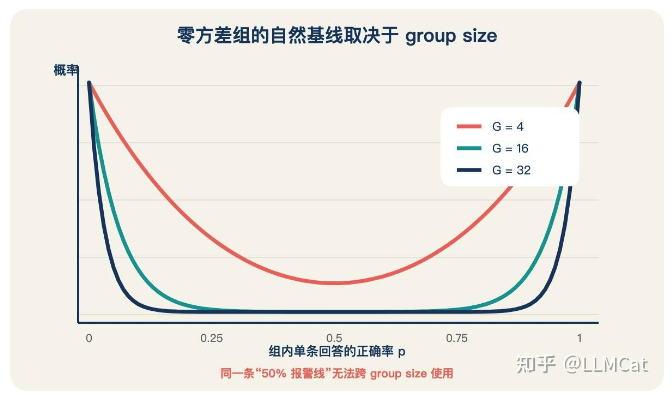

In [5]:
Image(filename='./Image/group_size.png')

<font color='red'>如果实测和预测吻合呢？那说明问题不在训练动力学上，而在题集难度分布上，该换数据，不是该开过滤。</font>

顺带：这个指标有的框架已经内置了，叫 **frac_reward_zero_std**，不用自己写。

### 危害深入分析
主流实现（例如DAPO 那种 token 级归一化）会把整个 batch 的 loss 加起来，再除以 batch 里的 token 总数。

可以把它想成“总贡献 ÷ 总人数”。
- 零 advantage token 对总贡献是 0，却仍然算在总人数里。
- 假设一个 batch 有 1000 个 token，其中 500 个来自零方差组：
  - <font color='red'>分子只收到另外 500 个 token 的贡献，分母却仍然除以 1000。</font>

所以损失的不只是半个 batch，有效梯度也被整体稀释了。效果上很像同时减小了 batch size 和学习率。

要注意，这个压低的系数是零 advantage token 的占比，不是 group 的占比。**而全对的组通常回答偏短、全错的组通常偏长（甚至撞截断）**，所以这两个数一般不相等。要估准就得量 token level 的比例。

还有一层：<font color='red'>如果开了 KL loss 或者 entropy bonus，这些组并不是完全没梯度，而是只剩下一个把模型往参考策略拉回去的正则项，一点 reward 信号都没有。这比单纯的无效更糟，它在用你的算力做纯粹的回退。而且那个方向是与输入无关的，会持续抹平不同题之间的差异。</font>

## 重要性比与 clip fraction
GRPO 会先采一批数据，再拿这批数据更新模型。问题是：做到第二个、第三个更新 step 时，模型已经变了，手里的回答却还是旧模型生成的。

<font color='red'>ratio 就是在量“现在的模型”和“生成这条数据时的模型”差了多少</font>。 对每个 token：
- $ratio = \frac{π_θ(token)}{π_{old}(token)}$

也就是更新后的模型给这个 token 的概率()$π_θ(token)$，除以采样时的模型给它的概率(π_{old}(token))。

ratio 可以直接当成概率的涨跌倍数：
- ratio = 1 表示没变，1.05 表示涨了 5%，0.8 表示降了 20%。
- <font color='red'>健康训练里，大多数 token 的 ratio 应该接近 1</font>。

clip 在做什么：PPO 和 GRPO 把 ratio 强行限制在 $[1 - \epsilon,1 + \epsilon]$ 里（典型 $\epsilon = 0.2$），超出的部分梯度不再生效，防止一个 step 走太远。clip fraction 就是有多少比例的 token 撞到了这个边界。

### 危险信号有两个。

  - 一是 clip fraction 突然涨到 20% 以上，说明更新步子普遍太大，或者数据已经太旧了。

  - 二是 ratio 出现极端离群值，比如某几个 token 的 ratio 是 $e^5$这种量级。均值会把这种情况完全藏住，所以要看分位数和最大值。

把上界和下界合成一个 clip fraction，就像只报“今天一共进出 100 万”，却不告诉你是流入还是流出。总量一样，方向可能完全相反。

一个典型的坍塌前兆是：
- 上界几乎不命中、下界大量命中。
  - <font color='red'>也就是许多 token 的概率在往下掉，很少有 token 能往上探索。</font>
  - 两个方向一合并，这个结构就消失了。

这个是我个人总结出来的，在多数框架上不是通用的，是要自己写代码。

这两个计数在所有框架的实现里都是按 advantage 符号门控的，而且结构上必然如此：PPO 的 min决定了上界只在 $\hat{A} > 0$时可能命中、下界只在 $\hat{A} < 0$ 时可能命中。

所以这两个计数不能脱离 advantage 来读。
- 上界计数只会看见正 advantage 的 token，
- 下界计数只会看见负 advantage 的 token。

“下界命中很多”可能是策略真的在大面积压概率，也可能只是这个 batch 里负 advantage 本来就更多。<font color='red'>看上下界时，必须把正负 advantage 的数量一起分析</font>

 <font color='red'>两侧引擎的 logprob 差：最容易被忽略，也最致命</font>

### 现在的 RL 训练基本都是两套东西配合：
- 用推理引擎（vLLM / SGLang）快速生成回答，
- 用训练框架（FSDP / Megatron）算梯度。

问题在于，同一条序列、同一份权重，这两套东西算出来的 token 概率并不完全一样。kernel、batch 组织和量化方式不同，都会带来差异。
  - 它很像两把刻度略有偏差的尺子：一把量“旧概率”，另一把量“新概率”。你把两个读数一除，以为看到的是模型变化，<font color='red'>其实里面还混着尺子本身的误差。</font>

#### 为什么这个非常严重：
- 如果直接拿推理引擎返回的 logprob 当上面说的 $π_{old}$，<font color='red'>那么 ratio 的分子分母来自两个不同的实现。</font>
  - 这时候即使模型参数一个字都没变，ratio 也不等于 1，而算法会把这个偏差误读成策略已经漂移了很远，然后据此调整梯度。

#### 具体怎么量：
- 把同一批 token 分别送进两套引擎，计算每个 token 的 $|\delta logp|$，然后至少看三个数：
- 均值、
- 高分位数
- 最大值。

为什么不能只看均值？假设一万个 token 里：
  - 9990 个 token 的差异都在 0.001 左右
  - 另外 10 个 token 的差异却非常大。
    - 最后算出来的均值仍然可能很小，看上去一切正常；
    - 但那 10 个异常 token 仍有可能撞到 clip 边界，甚至产生异常梯度。
    - <font color='red'>所以这里需要把“整体是否一致”和“有没有少数危险 token”分开检查。</font>

三个统计量可以这样分工：

  - mean：
    - 看整体误差是否普遍变大。我的经验是，
      - 均值低于 0.001 通常算健康；
      - 接近或超过 0.01 时应该停下来检查。
      - 最好先用一套确认正常的配置跑出自己的 baseline。
  - p99 / p99.9：
    - 看最异常的 1% 或 0.1% token 是否越来越多、越来越严重。它比单独看 max 稳定。
  - max：
    - 只回答“这一批里最极端的单个 token 差了多少”，适合定位具体异常样本。
  
要特别注意：上面的 0.01 是给 mean 用的，不是给 max 用的。即使训练健康，一大批 token 里也可能偶尔出现一个差异很大的极端值。如果要求 max < 0.01，几乎每个 batch 都可能报警，这条规则就失去意义了。

- 所以判断是否需要停训，主要看 mean；
- 判断少数异常 token 有没有变多，则看 p99、p99.9 和 max 的变化趋势。

## 长度、grad norm、reward 分项
### 长度爆涨别直接判 hack
- 看均值、p99，加上截断率。

#### 长度单调爆涨的时候，<font color='red'>先把长度按对错拆开</font>，分别画：

- E[|o| | 答对] 
- E[|o| | 答错]

  - **两条一起涨、而且答对那条涨得更快** → 这才是长度 hack，去查 reward 里哪个分项和篇幅正相关
  - **只有答错那条在涨** → <font color='red'>这不是 hack，这是 $1/|o_i|$那项长度归一化的机械后果：</font>
    - <font color='red'>错误样本的负 advantage 被长度摊薄了，于是写长一点能少罚一点</font>
  
- <font color='red'>这个区分非常要紧，因为两种情况的解决方式是**相反的**</font>。
  - 前者改 reward
  - 后者必须改 loss 聚合（token-level loss，或者干掉  $1/|o_i|$，<font color='red'>这种情况才会需要用到 DAPO 中的小trick</font>）

这时候去加长度惩罚是错的方向，而且不只是无效：
- 给错误答案加连续长度惩罚，在组归一化下容易产生发散的 advantage，结构上就容易把 reward 训崩。

「单调爆涨就是长度 hack」**这个说法把现象和机制搞混了**。
- 爆涨只说明长度这个维度上有压力失衡，压力从哪来得靠拆开才知道。

其余两条：
  - 塌缩到几十个 token 是反过来了，模型学到的教训是「**别说长话**」，通常是截断样本的处理方式出了问题。
  - 截断率飙升要警惕，**那意味着大量样本在撞 max_len，这些样本的 reward 通常是废的**。
  
#### “单调爆涨”只是表象，背后的原因（是奖励给多了，还是错误被稀释了）决定了你应该怎么修。

这段文字主要讨论的是在大模型强化学习（RLHF/RLAIF）训练过程中，<font color='red'>当出现“长度单调爆涨”（即模型生成的回复越来越长）这一现象时</font>，<font color='blue'>如何从机制上理解它，以及为什么简单的“长度惩罚”往往是错误的解决方案。</font>

这段话的核心观点是：
- “单调爆涨”只是表象，背后的原因（是奖励给多了，还是错误被稀释了）决定了你应该怎么修。

下面我为你详细拆解其中的逻辑和术语：
##### 核心概念：什么是“长度 Hack”？
在强化学习中，模型非常善于<font color='red'>寻找捷径来最大化奖励（Reward）</font>。
  - 现象：模型发现，只要写得越长，似乎得分越高。
  - Hack：<font color='red'>这里的 Hack 指的是模型利用了规则漏洞</font>。**它并不是真的变聪明了，而是学会了通过堆砌字数来“骗”取高分。**
  
##### 两种截然不同的“爆涨”原因
文中强调要把长度按“答对”和“答错”拆分开来看，这是诊断问题的关键。

###### 情况 A：<font color='red'>两条一起涨，且答对的那条涨得更快</font>
  - 诊断：这才是真正的 “长度 Hack”
  - 机制：模型发现“写得长”本身就能带来正向收益。<font color='red'>这通常是因为 Reward Model（奖励模型）的设计有问题</font>，比如它倾向于给长文打高分（因为长文往往包含更多信息，或者训练数据里长文就是好回答）
  - Reward 里的分项：<font color='red'>这意味着 Reward 函数里某个跟长度正相关的项（比如完整性、详细度）权重过大。</font>
  - 解决方法：改 Reward。你需要调整奖励函数的公式，<font color='red'>降低长度带来的直接收益，或者引入更严格的长度惩罚。</font>

###### 情况 B：只有答错的那条在涨
  - 诊断：这不是 Hack，这是 $1/∣o_i∣$ 归一化的机械后果。
  - 机制：在很多 RL 算法（如 PPO）中，为了让不同长度的样本公平比较，会将 Advantage（优势函数）或 Loss 除以长度 $∣o_i∣$ （即 token 数量）。
    - 公式逻辑：<font color='blue'>如果一个错误的回答很长，它的单 Token 损失（Loss）就会被除数（长度）摊薄。</font>
    - 结果：写长一点，虽然总体没错，但平均到每个字的惩罚就变少了（少罚一点）。模型为了“止损”，本能地选择把错误的废话写长。
  - 解决方法：<font color='red'>改 Loss 聚合方式</font>。这时候去加长度惩罚是没用的，甚至有害。你需要改变计算 Loss 的方式，比如不要用 token-level loss 平均，或者使用特定的 Trick（如文中提到的 DAPO 中的小 trick）来消除这种长度带来的数值偏差。
  
##### 为什么“加长度惩罚”可能是错的？
文中特别警告：这时候去加长度惩罚是错的方向。
  - 对情况 B 的危害：如果是因为“错误被摊薄”导致的变长，你再加长度惩罚，会导致 Advantage（优势值）在归一化下产生剧烈的波动（发散）。
  - 后果：<font color='red'>这种数值上的不稳定会直接导致 Reward Model 崩溃（训崩），模型彻底学坏。</font>
##### 总结与其余两条观察
作者最后总结道：“单调爆涨就是长度 hack”这句话把现象（爆涨）和机制（Hack vs 归一化副作用）搞混了。爆涨只说明压力失衡，必须拆开看才能找到压力的源头。
此外，文中还提到了两个相关的极端现象：
   1. 塌缩到几十个 Token：这是反过来的情况。模型学到了“别说长话”，<font color='red'>通常是因为截断样本（max_len）处理得不好，模型怕出错所以选择闭嘴或只说短句。</font>
   2. 截断率飙升：如果大量样本都撞到了最大长度限制（max_len），说明这些样本的 Reward 通常是废的（因为没说完就被掐断了，奖励信号不准确），需要警惕。
   
##### 一句话总结
当你看到模型输出越来越长时，不要急着加惩罚。先看看是“答对的变长了”（那是奖励模型偏心长文，要改 Reward），还是“答错的变长了”（那是算法归一化导致的避罚机制，要改 Loss 计算）。
  
### grad norm 要看裁剪前的
主流框架默认记的基本都是裁剪前的，裁剪函数的返回值本来就是缩放前那个 norm。
- 所以在 wandb 上看到 grad_norm: 8.3 而配置里 max_grad_norm=1.0，不是bug，而是说明这一步的梯度被整体缩小了 8.3 倍。

自己写的时候要注意，**先 log 再剪裁，否则从曲线上看不到尖刺到底有多大**。
- 危险信号是突然出现 10 倍以上的尖刺。

### reward 必须按分项拆开
<font color='red'>总 reward 是最容易骗人的指标</font>。格式分、长度分能单独把它顶上去，<font color='blue'>而你真正在意的正确性分项可能一动不动</font>

只看总分，会把「学会了排版」当成「学会了解题」。

不过要注意**别把训练早期误判成 hacking**：
- <font color='red'>刚开训的时候模型是先学格式、后学正确性的</font>，
  - 所以「格式分涨、正确性平」是一个正常形状。
  - <font color='red'>真正要看的是这个状态持续了多久，以及正确性分项有没有在到达 plateau(高峰) 之后开始下滑。</font>

## ESS(有效样本数)：batch 里<font color='red'>有多少样本真正起了作用</font>
batch size 只表示这一批放进了多少样本，<font color='blue'>并不保证每条样本对梯度的影响差不多。</font>

假设一个 batch 有 512 条回答。
- 如果它们的重要性权重比较接近，梯度确实综合了几百条样本的信息。
- <font color='red'>但如果少数几条的权重特别大</font>，其余样本几乎可以忽略，那么这个 step 名义上用了 512 条，实际却主要由那几条高权重样本决定。

ESS（Effective Sample Size，有效样本数）就是用来量这件事的：

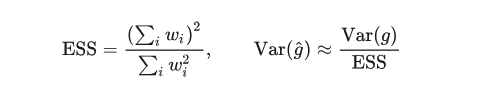

In [6]:
Image(filename='./Image/ess.png')

- 这里的 $w_i$是重要性权重。

这个公式不用死记，抓住两种情况就够了：

  - 权重分得比较均匀，<font color='red'>ESS 会接近真实的 batch size；</font>
  - 权重集中在少数样本上，<font color='blue'>ESS 会明显低于 batch size。</font>
  
例如，batch size 是 512，ESS 只有 8，不是说只剩 8 条样本有非零梯度，而是说：
- 从梯度估计的稳定性来看，<font color='blue'>这一步大致只相当于用了 8 条权重均匀的样本。</font>
- <font color='red'>其他样本并非完全没用，只是少数高权重样本占据了过大的影响</font>

实际监控时，我更常看 ESS / batch_size，也就是 ESS ratio。<font color='red'>这样换了 batch size，曲线仍然可以比较。</font>

### 为什么它比 grad norm 更早
训练失稳通常有一个积累过程：<font color='red'>先是重要性权重越来越集中，接着 KL 和 grad norm 开始异常，最后才反映到 reward 上。</font>



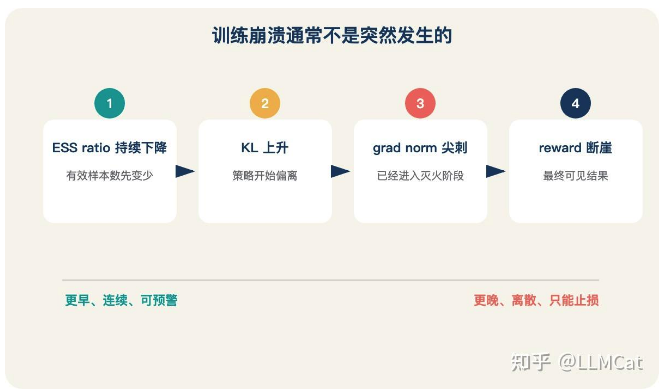

In [7]:
Image(filename='./Image/ess_step.png')

- **ESS ratio** 的优势在于:它会逐步下降，因此往往能在 grad norm 出现尖刺之前给出信号。
- **grad norm** 尖刺更像一次明确的异常事件；<font color='red'>看到它时，训练通常已经进入需要止损和定位问题的阶段</font>

这里不需要把图里的先后顺序理解成每次都严格成立。更准确的说法是：
- ESS 观察的是风险如何集中
- grad norm 观察的是<font color='red'>这种集中是否已经产生了剧烈更新</font>。 
- 前者更适合预警，后者更适合确认训练已经不稳。

### ESS 下降后，先判断是哪一种偏差
ratio 变得不均匀，不一定都是因为 rollout 太旧。至少要区分两种情况：

  - 策略陈旧：生成回答后，模型又更新了多次。当前策略和生成数据时的旧策略确实已经拉开距离。
  - <font color='red'>两侧引擎不一致</font>：模型权重没有变化，<font color='blue'>只是采样引擎和训练框架算出的 logprob 不同</font>
  
解决：
- 前者是真实的策略移动，可以从更新次数、异步延迟或 ppo_epochs 入手；
- 后者是工程和数值一致性问题，应该回到第三节检查两侧 logprob。

两种偏差最终都会进入 ratio，也都会拖低 ESS。
- 如果只看一条合并后的 ratio 或 ESS 曲线，很容易把引擎误差当成“数据太旧”，然后错误地去调 ppo_epochs。

面试时我偶尔会追问 ESS，不是想听公式，而是看候选人能不能说明两件事：
- 它为什么比 batch size 更接近“真正参与梯度的样本数”，
- 以及 ESS 下降后如何区分策略陈旧和引擎不一致。

## 总结
这篇不太适合背固定阈值，更实用的是按一条顺序去看训练信号。

1. 先看 group 里有没有可比较的 reward。零方差组没有任务梯度，**但它的正常占比取决于 group size 和题目难度，不能统一用 50% 判断。**

2. <font color='red'>再看 ratio 本身是否可信</font>。
  - <font color='blue'>采样引擎和训练框架可能给出不同的 logprob，因此同一份权重下 ratio 也可能偏离 1。</font>判断整体一致性看 mean；
  - 检查少数异常 token，则看 p99、p99.9 和 max。

3. 然后看 **梯度是否开始被少数样本控制**。
  - ESS 比 batch size 更能反映这一步用了多少有效信息。
  - ESS ratio 持续下降，通常比 grad norm 尖刺更早；
  - 但解释它之前，必须先排除两侧引擎不一致。

4. 最后再看 **长度、grad norm 和 reward 分项**。这些指标更接近已经表现出来的结果：
  - 长度要按对错拆，
  - grad norm 要看裁剪前，
  - 总 reward 要拆成正确性、格式、长度等奖励分项。

<font color='red'>整套监控想回答的其实是同一个问题：</font>
- 这一批数据提供了多少可信的比较信号，
- 这些信号有没有被少数样本或工程误差带偏，
- 最后又以什么形式反映到模型更新上。

# GRPO策略坍塌的根因与去掉 std 归一化的代价

本系列文章会分享 GRPO 排查的经验。以及我作为面试官，考查 post-training 方向候选人时，是如何判断对方是否有对应的能力。

本系列前面的文章已经讲过怎么区别策略坍塌和训练崩溃。

## 这篇从“为什么会塌”开始。

先回顾一个典型现象：
- 训练到中后期，同一道题采 16 条回答，<font color='red'>去重后只剩两三种</font>；
- 训练 reward 仍在上涨，pass@1 也可能变好，但测试集开始掉点，pass@16 甚至低于 base model。

这不是简单的“**模型什么都不会了**”。<font color='red'>它更像是模型把赌注全压在**少数**几条路径上</font>：
- <font color='blue'>最常出现的答案越来越稳定，其他原本也能解题的路径却逐渐采不到了。</font>

为什么 GRPO 会把模型推向这个状态？要先看清**一次训练更新是怎么产生的**：

1. 对同一个 prompt 采一组回答；
2. 给每条回答打 reward；
3. <font color='red'>在组内计算谁高于平均、谁低于平均，得到 advantage</font>
4. 用 advantage 调整这些回答中 token 的概率；
5. **更新后的模型再去生成下一批回答。**

- 如果组内比较可靠，这个循环会让好答案更常出现。
- 如果某条回答只是偶然胜出，却在第三步被赋予过大的 advantage，它下一轮就会更常出现；
- <font color='red'>出现得越多，又越容易继续被强化。策略坍塌就是这样逐轮积累出来的。</font>

##### 这篇只追其中一个问题：
<font color='red'>一组回答已经打完分以后，这些分数是怎么变成更新权重的？</font>

GRPO 通常会把每条回答的 reward 减去组内均值，再除以组内标准差 $\sigma$。
- 这个操作看起来只是把数字整理到相近的尺度，<font color='red'>却会改变“哪条回答对这一步更新最有影响”。</font>

下面先把它放回完整训练链路，再用一组具体分数把计算拆开。

## 先确定问题发生在哪一步
先把五类 root cause 放回刚才那条训练流程里。它们不是五个并列的技巧，而是在不同环节破坏了不同东西。



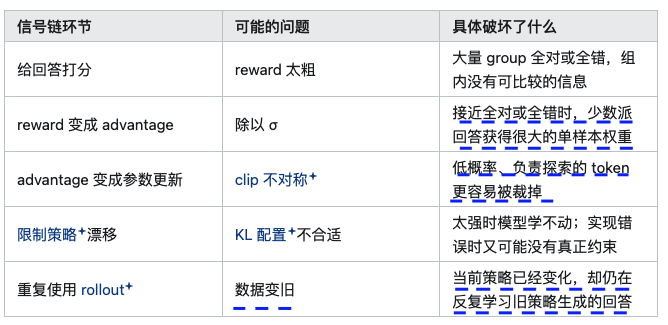

In [37]:
Image(filename='./Image/steps.png')

##### 这张表也说明了为什么不能看到坍塌就直接“上 clip-higher”。
- 如果 reward 本身让大多数 group 都没有方差，问题发生在 clip 之前；
- 如果 ratio 里混入了陈旧数据，单改 $\sigma$ 也解决不了。

##### 本文主要处理第二行：
- reward 已经有高低之分，<font color='red'>但这些分数经过组内标准化以后，更新权重是否还符合我们对信号可靠性的判断。</font> 
  - <font color='blue'>$\sigma$归一化不是策略坍塌的唯一原因，也不是看到坍塌就该关闭的开关</font>

##### 这里只分析它具体改变了什么。

标准 GRPO 的 advantage 是：

$\hat{A_i} = \frac{r_i - \mu}{\sigma}$

这里的 advantage 可以先理解成一条回答在这一步训练中的“**有符号权重**”：

  - 正数表示提高这条回答中 token 的概率，负数表示压低
  - <font color='red'>绝对值越大，这条回答对本次更新的影响通常越大</font>
  -  $r_i - \mu$ <font color='red'>决定方向和原始分差</font>，
  - 除以$\sigma$ 则把这组分差<font color='red'>重新换了一个尺度</font>
    - **分差**= "实际表现" 减去 "平均预期"

- 减均值负责回答“谁比同组平均更好”，
- 除以 $\sigma$负责回答“这组差异整体按多大音量进入训练”。
  - <font color='red'>问题在于， $\sigma$ 只知道分数有多分散，并不知道这些分差究竟代表可靠能力，还是偶然采样和 reward 噪声。</font>

## <font color='red'>从一组具体分数看 σ 到底改变了什么</font>

先从最简单的二值 reward 开始：
- 答对得 1 分，答错得 0 分。
- 假设一道题采 10 条回答，其中 9 条正确、1 条错误；
- 实际训练用 8、16 或其他 group size，关系是一样的。

### 第一步只减均值。组内平均分是 0.9，所以：

  - 每条正确回答的分差是 1 - 0.9 = +0.1
  - 唯一错误回答的分差是 0 - 0.9 = -0.9
  
这一步已经让少数派的单样本权重更大了。
  - <font color='blue'>因为 9 条正确回答各自只比平均值高一点，而唯一的错误回答离平均值很远。正负分差加起来仍然是 0。</font>


### 第二步才是除以 $\sigma$。这组 0 和 1 的标准差是 0.3，于是所有分差统一乘以 ：
  - 正确回答从 +0.1变成约 +0.33
  - 错误回答从 -0.9变成 -3

解释：
  - 因此，除以 $\sigma$不是只挑出**少数派**单独放大，<font color='blue'>而是把整组分差统一放大</font>；
  - 少数派原本离均值最远，所以最后拿到最大的绝对权重。

把中等题、简单题和难题放在一起看，结果如下：

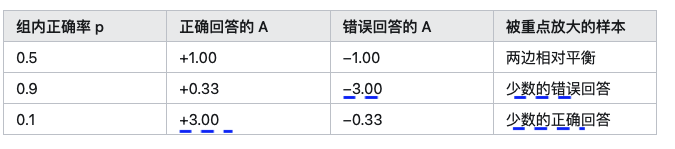

In [38]:
Image(filename='./Image/compare.png')

表里的数字按总体标准差计算，方便观察关系。
- 框架如果采用无偏标准差，数值会略小，但形状不变。

### 总体标准差和无偏标准差

- **总体标准差**用于描述**已知全体数据的真实离散程度**（<font color='red'>分母为N</font>）
- **无偏标准差**（样本标准差）用于<font color='blue'>**通过部分样本准确推断**</font>总体离散程度（<font color='red'>分母为n-1</font>，即贝塞尔校正）

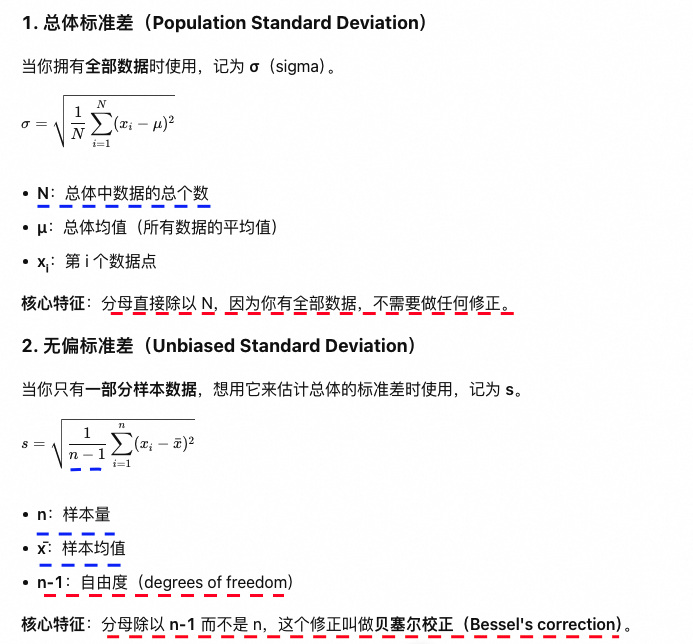

In [44]:
Image(filename='./Image/standard_deviation.png')

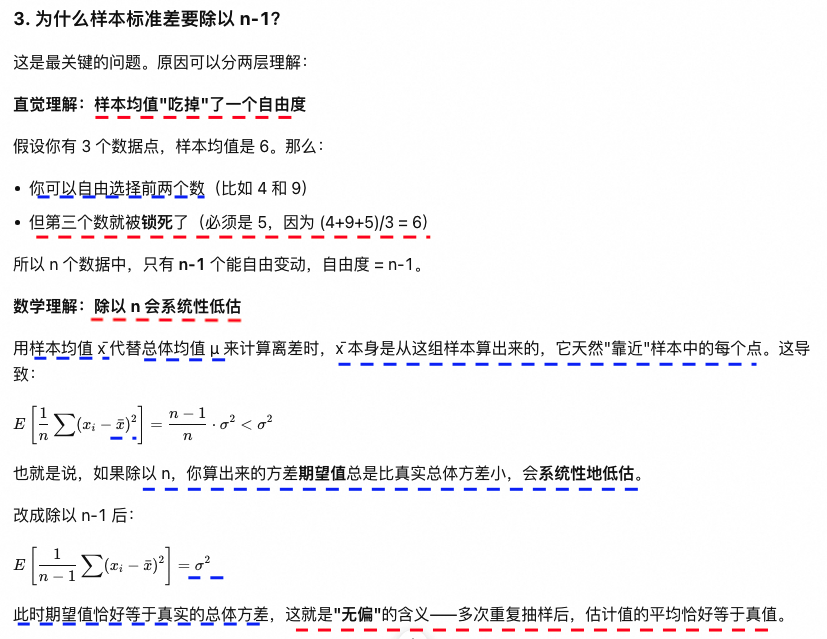

In [45]:
Image(filename='./Image/standard_deviation_1.png')

#### 一个重要的细微之处
严格来说，贝塞尔校正让样本方差 s² 成为总体方差的无偏估计，但样本标准差 s（方差的平方根）并不是总体标准差的严格无偏估计。因为平方根是非线性函数，根据詹森不等式（Jensen's inequality），开方后仍然会略微低估。
**不过在大多数实际应用中，这个偏差非常小，通常忽略不计**。

#### 对比总结

| 维度 | 总体标准差 σ | 无偏标准差 s |
|---|---|---|
| 适用场景 | 拥有全部数据 | 只有样本，需推断总体 |
| 分母 | N | n - 1 |
| 均值来源 | **总体均值 μ（已知）** | **样本均值 x̄**（从数据算出） |
| 是否修正 | 不需要 | 贝塞尔校正 |
| 无偏性 | 精确值 | 方差的无偏估计 |
| 符号 | σ | s |

#### 什么时候用哪个？
  - 用总体标准差：<font color='red'>你能拿到全部数据</font>（比如全班 50 人的成绩，你都拿到了）
  - 用无偏标准差：<font color='blue'>你只有部分数据，想推断整体</font>（比如从 10000 个用户中抽了 200 个，想估计全体用户的波动）
  
#### 💡 实用提示：
当样本量 n 很大时（比如 n > 30），<font color='red'>n 和 n-1 的差异微乎其微</font>，<font color='blue'>两种方法的结果几乎一样。 </font>
- <font color='red'>但在小样本或精确统计分析中，一定要用 n-1</font>。在 Excel 中，STDEV.P() 对应总体标准差，STDEV.S() 对应样本标准差。

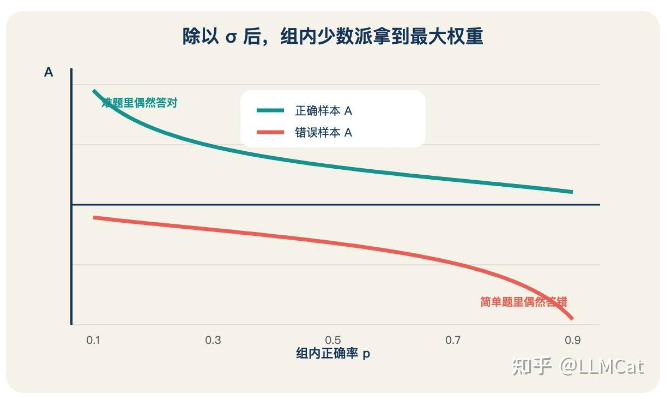

In [41]:
Image(filename='./Image/sigma.png')

这里最值得警惕的不是“少数派一定是错的”，而是：<font color='red'>单样本权重主要由它在组内有多稀少决定</font>，而不是由我们对它有多确信决定。

- 在难题里，唯一答对的回答可能是一次真正有价值的探索，也可能只是碰巧猜中；
- 在简单题里，唯一答错的回答可能暴露了稳定缺陷，也可能只是一次采样失误。 
- <font color='red'>$\sigma$ 归一化无法区分这些情况，它只会按组内分数的位置分配权重</font>

### 从刚才的例子怎么得到通用公式

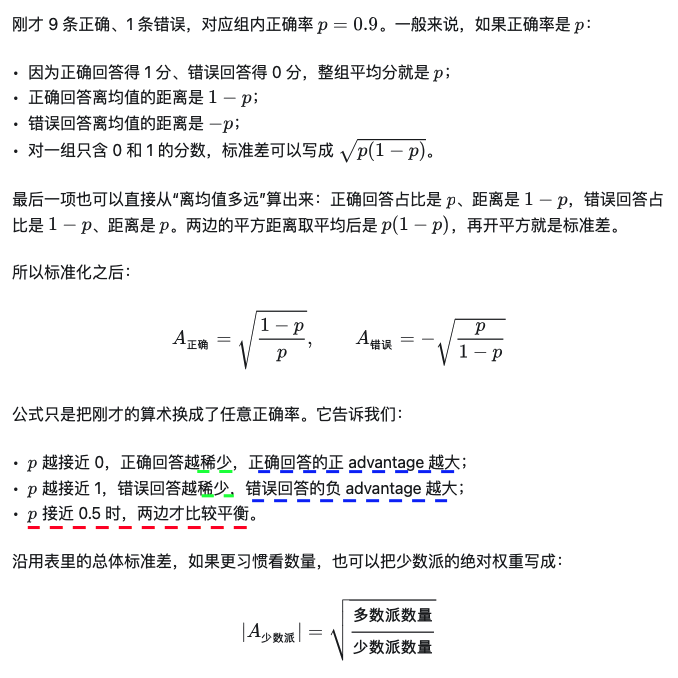

In [46]:
Image(filename='./Image/2.1.png')

这不是两次独立的放大，<font color='red'>而是同一次标准化的两个观察角度：</font>

  - 从题与题之间看，<font color='red'>接近全对或全错的 group， $\sigma$更小，原始分差会被换算到更大的尺度；</font>
  - 从一道题内部看，<font color='blue'>少数派离均值最远，因此它的单样本绝对权重最大</font>。
  
<font color='red'>最终风险取决于这些少数派样本是否可靠。</font>
- 如果 reward 准确、唯一正确答案确实展示了可复用的方法，大权重可能有帮助；
- 如果 reward 有噪声，它也会把偶然胜出的样本推得很重。

### 为什么曲线看似趋于无穷，实际却有上限


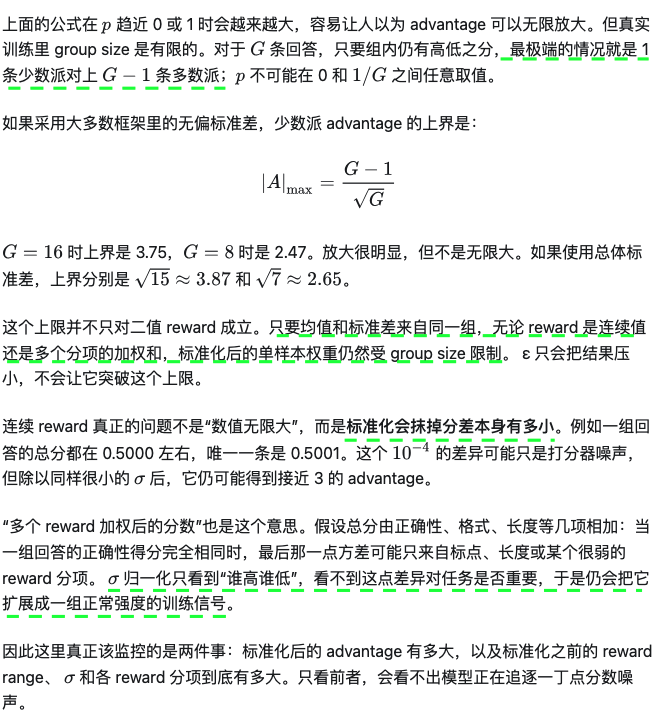

In [47]:
Image(filename='./Image/2.2.png')

## 去掉 σ的本质

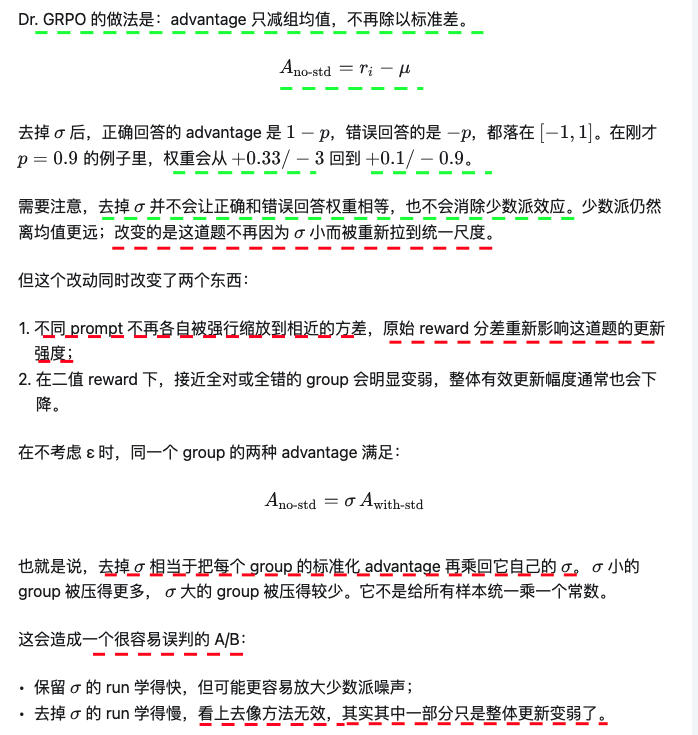

In [48]:
Image(filename='./Image/3.png')

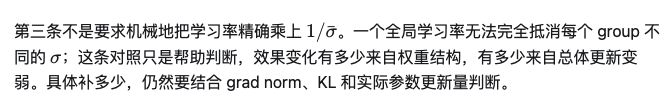

In [14]:
Image(filename='./Image/3.0.png')

### σ 归一化的价值
 $\sigma$归一化并非毫无价值。<font color='red'>它在做一种逐 prompt 的自适应缩放</font>：
 - 不管原始 reward 分差是 0.001 还是 1，<font color='blue'>都尽量把它们换算到相近的尺度</font>。这样不同 prompt 更容易提供接近强度的训练信号。

问题在于，**reward 方差小**可能有两种完全不同的含义：

  - 分差虽小，但排序可靠，确实值得学习；
  - 分差小是因为大家几乎一样，剩下的差别主要是 reward 噪声或次要分项。
  
$\sigma$归一化无法区分两者。
- 去掉它会降低第二类噪声的影响，
- 但也会让“差距小却可靠”的偏好信号变弱。
- <font color='red'>所以这是 trade-off，不是一次没有代价的 bug 修复</font>

###  σ 和长度归一化的区别
Dr. GRPO 中，还删除了回答长度归一化项 $1/|o_i|$。这两项对应的是不同偏置：

  - **除以$\sigma$ **：改变不同难度题目和组内少数派的权重，属于 difficulty bias。
  - **除以回答长度**：让长回答的单位 token 惩罚更轻，尤其会减弱长错误回答的负 advantage，属于 length bias。
  
论文把长度失控归因于 $1/|o_i|$，而不是$\sigma$ 。
- <font color='red'>由于两项是一起删除的，论文没有提供两者对长度影响的独立消融。</font>遇到错误回答越来越长时，应该先检查 loss 是否按回答长度做了归一化。

## 过滤<font color='red'>零方差组</font>的目的
当一组 16 条回答全对或全错时，$r_i - \mu$来就是 0。无论是否除以 $\sigma$，advantage 都是 0。

这意味着：
- 去掉 $\sigma$只能处理“仍有方差，但正确率很极端”的 group，<font color='red'>处理不了严格的全对或全错</font>

DAPO 的 dynamic sampling 走的是另一条路：
- 丢掉零方差 group，继续采样，直到凑够指定数量的有效 group。这样训练 batch 里每个 group 都至少包含两种 reward。

- 这个方法提高了训练数据的利用率，但不是没有成本的。

### 第一项代价：生成开销取决于数据难度
- 如果零方差组很少，重采样成本可以被生成—训练流水线隐藏；
- 如果六七成 group 都是全对或全错，为了凑满有效 batch 就要生成大量额外回答。

所以不要直接照搬论文里的时间开销结论。需要同时记录：
- 零方差组比例、**为了补齐 batch 实际生成了多少 group**，以及生成能否与训练并行。

### 第二项代价：训练目标的权重变了
零方差 group 本来就没有任务梯度，所以问题不在“删掉了什么信号”，而在“**删掉以后又用什么补进来**”。

例如，普通采样一次得到 10 个 group，其中可能只有 4 个有高低分；这一步真正提供任务梯度的就只有 4 个。动态采样会继续生成，直到凑满 10 个有高低分的 group。
- 于是每个 optimizer step 看到的有效比较更多，更新通常也更强。

同时，不同 prompt 被保留下来的概率并不相同。
- 中等难度的题更容易同时采到对和错，会更频繁地进入最终 batch；
- 几乎全对或全错的题需要反复重采样，甚至一直进不来。训练数据因此被重新加权了。

至于零梯度 token 是否仍占 loss 的归一化分母，要看具体框架的 reduce 方式。这个实现细节会影响动态采样把更新放大多少，但不改变上面的核心事实：最终参与每一步训练的 prompt 分布已经变了。

### 第三项代价：已经掌握的能力更容易被看不见
一个常见说法是：“全对的题被过滤，所以模型在这些题上没有梯度，最后遗忘了。”这条因果不准确，因为全对 group 在原始 GRPO 里 advantage 也是 0，本来就没有任务梯度。

真正变化的是：
- 补满有效 group 后，中等题和难题在每一步更新中的占比提高了。
- 至于单步梯度是否因此直接变大，取决于框架怎样归一化 loss；
- 但无论实现如何，模型都会更持续地沿着这些题的方向移动，也可能逐渐离开原来已经掌握的能力区域。

<font color='red'>更麻烦的是，动态采样会让 batch 表面上一直是满的，看不出底层有效 prompt 池正在缩小。</font>
- 因此需要单独保留一个“已掌握题目”的回归集，<font color='blue'>定期检查简单能力有没有退化。</font>

这个是我个人通过机制推断，我自己其实**没有复现出来过**“训练 reward 上涨、简单集准确率同步下降”的完整曲线。正是因为训练 batch 看不见被过滤的简单题，所以我们才需要额外回归集来验证，而不是直接把退化当成既定事实。

几十道题的小回归集只能做报警器，不能做精确量尺；样本太少时，几个点的上下波动未必有意义。

### 零方差很多时，先分清是全对还是全错
相同的零方差占比，处理方向可能完全相反：

- 全对为主：数据对当前模型太简单，应该增加更难或更有区分度的题。
- 全错为主：可能是题目超出模型能力，也可能是验证器过严或 false negative。应先检查判题，再考虑补 SFT、调整课程或增加可达的中间难度。
  - False Negative（假阴性）的核心含义是：实际情况为"是"，但检测结果错误地报告为"否"
    - 即本该被检出的东西被漏掉了。

<font color='blue'>只看到“零方差占 70%”还不能决定要不要换数据，关键是这 70% 由全对还是全错组成。</font>

- 给全错 group 注入一条可信的满分参考回答，可以人为制造组内比较
- <font color='blue'>但它改变了采样分布和训练目标，不能当作无偏修复。全对 group 则需要相反方向的对照样本，不能注入同样的满分回答。</font>

## 去掉 σ 和过滤零方差组怎么配合

这两个方法经常被说成同一个问题的两种解法，**其实它们处理的是不同区域**。

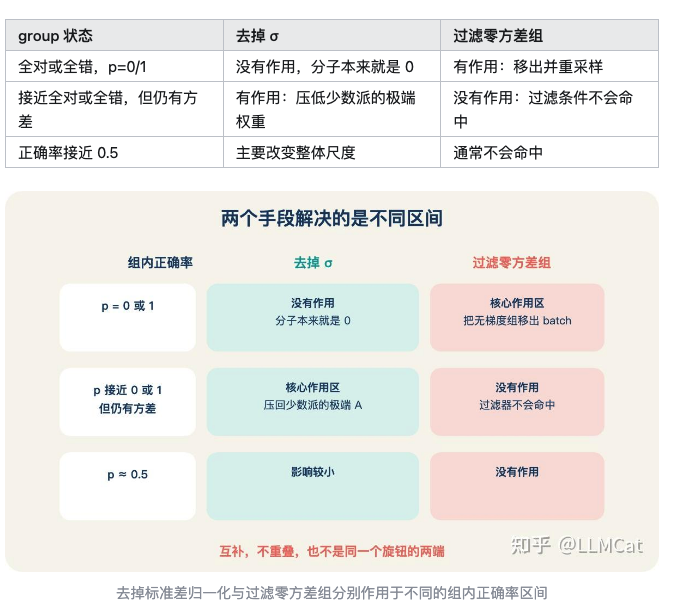

In [15]:
Image(filename='./Image/diff.png')

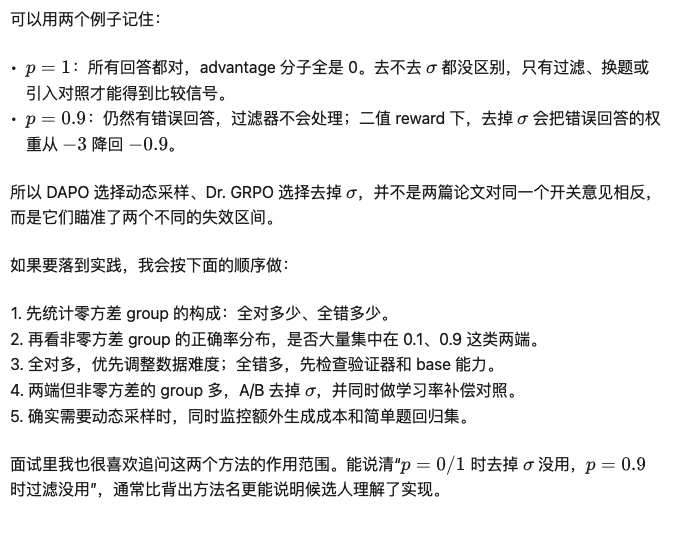

In [16]:
Image(filename='./Image/diff1.png')

## 脱敏实验记录
最后再放我自己的实验记录，因为它只能补充背景，不能用来证明前面的机制。

我有一次观察到明显的坍塌。下一轮同时做了三项修改：刷新参考策略、减小 KL 系数、把训练题型混得更杂。第二轮没有再次出现同样的坍塌。

### 这个结果只能说明：
- 换了一整套配方以后，现象消失了。 它不能说明三项里的哪一项有效，更不能证明三项都有效，因为我没有做单变量消融。

如果一定要提出假设，我更怀疑题型混合度起了主要作用：
- 题型更杂以后，<font color='red'>可能有更多 group 能产生 reward 方差</font>，有效信号不再只集中在少数题型上。但这仍然只是机制推测。

刷新参考策略和减小 KL 都会放松对策略漂移的限制，从直觉上甚至未必有利于保留多样性。因此不能因为第二轮没塌，就把这两项写成“抗坍塌配方”。如果要验证原因，仍然需要分别 A/B。

## 总结
策略坍塌不只是“熵变低”，<font color='red'>而是训练把概率越来越集中到少数路径，同时丢掉了原本存在的其他解法。</font>**要修它，先要判断是哪一环让比较信号失真**。

这篇重点讨论的 $\sigma$归一化，会把每个 prompt 的 reward 分差重新缩放。接近全对或全错时，少数派离均值最远，因此拿到最大的单样本权重。这个权重并不是无限的；使用无偏标准差、G = 16时，上界是 3.75，而且该上限同样适用于连续 reward。

连续 reward 的额外风险在于，标准化会抹掉原始分差的绝对大小。一点微弱的打分器噪声，或者多个 reward 分项中并不重要的细小差别，也可能被扩展成正常强度的 advantage。因此不能只监控标准化后的数值，还要同时看原始 reward range、 $\sigma$ 和各分项。

去掉 $\sigma$的本质是保留原始 reward 分差：
- 分差小的 group 就少更新，分差大的 group 就多更新。它能压低难度两端 group 的极端权重，但通常也会降低总体更新幅度。因此做 A/B 时，需要把“权重结构变了”和“整体步子变小了”尽量分开观察。

过滤零方差 group 解决的是另一件事：
- 全对或全错时根本没有比较信号。它能提高有效 batch 的比例，却会增加生成开销、重新加权 prompt 分布，并让有效题池的收缩更难被看见。

最终不是在“去掉 $\sigma$”和“动态采样”之间二选一，而是先看 group 落在哪个区间：
- 严格零方差、接近零方差但仍有少数派，还是正常的中间难度。不同区间对应不同修法，也对应不同代价。

下一篇深入讲解对称的 clip 区间，分析它为什么实际并不对称，以及为什么“熵在下降”本身不能作为调整 clip 的依据。

# GRPO CLIP边界如何调整？

- https://zhuanlan.zhihu.com/p/2079296721482412050

本系列文章会分享 GRPO 排查的经验。以及我作为面试官，考查 post-training 方向候选人时，是如何判断对方是否有对应的能力。

上一篇讲了策略坍塌的第一条 root cause（<font color='red'>优势归一化</font>）这一篇继续往后走一步：
- <font color='blue'>有了 advantage 以后，clip 到底限制了什么？</font>

很多文章会用一句话概括 DAPO 的 clip-higher：
- 低概率 token 更容易撞到上界，梯度被裁掉，所以应该放宽上界。

方向没有错，但这句话把几件不同的事情揉在了一起。但是深一层思考,你是否会想到下面的问题？

- ratio 明明对所有 token 都是同一个区间，<font color='blue'>为什么低概率 token 更容易撞到上界？</font>
- “撞到 clip”是不是一定没有梯度？
- 上下界都写成 20%，为什么只撞上界？它为什么不对称？
- 熵下降以后，是不是增大 clip-high 一定能解决？

要回答这些问题，得先把三个层次分开：

1. <font color='red'>ratio 和 log-ratio 的几何关系</font>：接下来会直接带大家算。
2. softmax 对 logit 更新的响应：<font color='blue'>这能解释为什么低概率 token 在一个受控情形下更容易走远而撞到上界。</font>
3. <font color='red'>clip 最终怎样影响熵</font>：这是整个 token 分布和正负 advantage 共同作用导致的结果，无法只靠前两条直接推出。

## clip 到底在裁什么

rollout 是旧策略生成的。训练时，<font color='red'>同一个 token 在当前策略下的概率已经可能发生变化</font>

### PPO/GRPO 用新旧概率之比衡量这个变化：
- $r_i = \frac{p_{new}(i)}{p_{old}(i)}$
  - 如果 $r_i = 1$，说明概率没变；
  - $r_i = 1.2$，说明变成了原来的 1.2 倍；
  - $r_i = 0.8$，说明变成了原来的 0.8 倍。

以默认的 $\epsilon = 0.2$为例，clip 区间就是：
- $r_i ∈[0.8,1.2]$

<font color='green'>但“超出区间”不等于“一律截断”</font>。clip 是否让梯度归零，<font color='red'>还要看 advantage 的符号</font>：

advantage |	ratio 走到哪一侧	     |    训练原本想做什么	      |    是否被截住
- A>0	r>1+$\varepsilon_{high}$	继续提高这个 token 的概率	 是，梯度为 0
- A>0	r<1-$\varepsilon_{low}$	    把已经下降的概率拉回来	        否

- A<0	r<1-$\varepsilon_{low}$	    继续降低这个 token 的概率	 是，梯度为 0
- A<0	r>1+$\varepsilon_{high}$	<font color='green'>把已经上涨的概率压回来</font>	        否

In [17]:
from IPython.display import Image

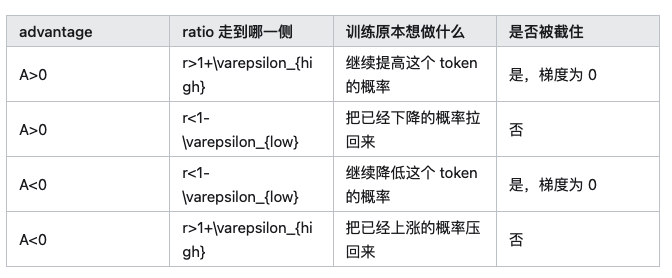

In [18]:
Image(filename='./Image/advantage.png')

所以 clip 的作用不是把 ratio 硬塞进一个区间，而是：
- <font color='green'>当概率已经沿着 advantage 希望的方向走得足够远时，不再奖励它继续走</font>

###  为什么还要换成 log-ratio
直接被裁的是 ratio，优化器真正更新的是模型参数。把这件事直接说成“<font color='green'>优化器工作在 logprob 空间</font>”可能并不准确。

<font color='blue'>但为了比较新旧策略究竟走了多远，log-ratio 更直观</font>。因为：

$logr_i = logp_{new}(i) - logp_{old}(i) = {logp_i}$

- ratio 表示“概率乘了多少倍”，
- log-ratio 则把这次乘法变化<font color='green'>写成一段可比较的加法距离</font>。

默认边界换算以后是：
  - log(1.2 )= +0.182
  - log(0.8 )= -0.223

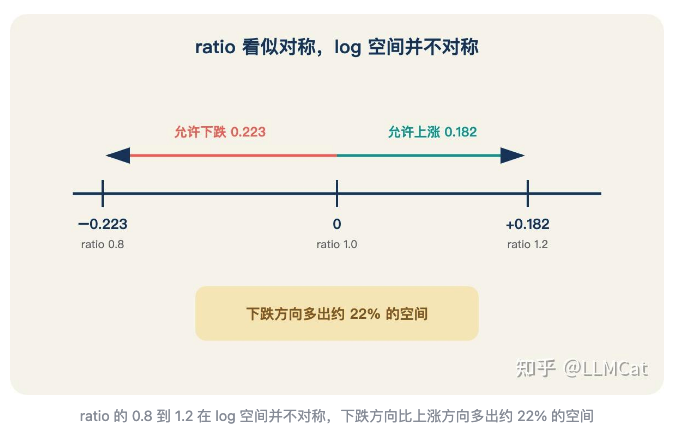

In [19]:
Image(filename='./Image/ratio.png')

这说明一个很具体的事实：
- 默认区间允许正 advantage token 的 logprob 最多向上走 0.182，<font color='red'>却允许负 advantage token 的 logprob 向下走 0.223</font>
  - <font color='red'>下跌方向的距离多约 22%</font>

这条结论与 token 原本的概率没关系。不过，它只能说明边界在 log 空间不对称，不能单独证明熵一定下降。
熵的净变化还取决于:
- 哪些 token 拿到正负 advantage、
- 哪一侧更常命中，
- 以及这些 token 原本的概率。

###  接近对称的 0.25
如果固定下界为 0.8，希望上下两侧在 log 空间距离相同，那么上界应该满足：

- $logr_{high} = -log0.8$
因此:
- $logr_{high} =\frac{1}{0.8} = 1.25$
  - 也就是 $\epsilon_{high} = 0.25$
  
  


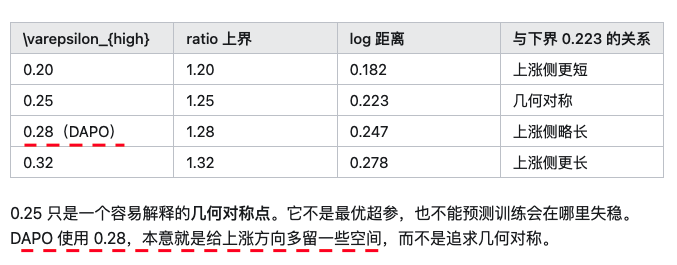

In [49]:
Image(filename='./Image/clip.png')

## <font color='red'>低概率 token 为什么更容易撞上界</font>
前面只说明了上下边界不对称，<font color='blue'>下面我们分析低概率 token</font>

要看概率高低带来的区别，可以做一个受控实验：
- 只把当前 token 的 logit 增加 $\delta$，其他 token 的 logit 暂时不动。

设这个 token 原来的概率是 $p_i$。经过 softmax 重新归一化以后：

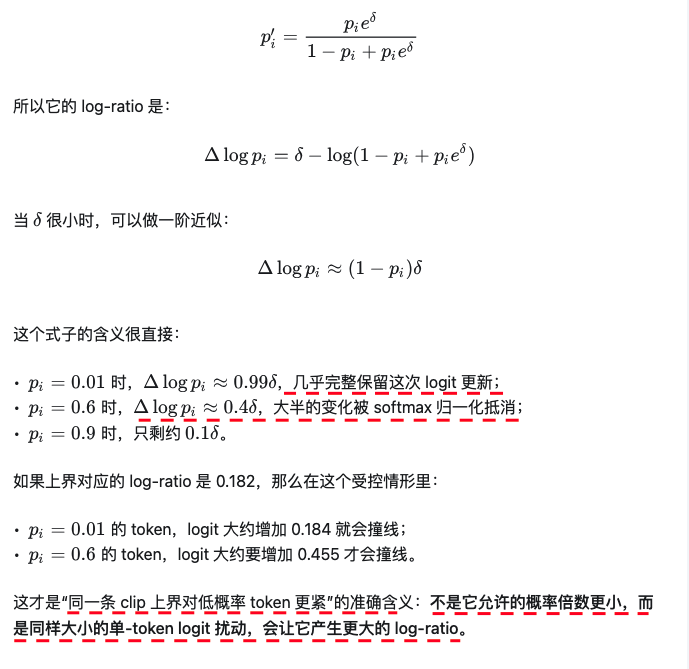

In [50]:
Image(filename='./Image/clip_high.png')

### 真实更新计算（公式略多，嫌麻烦可跳到最后的结论）
上一节为了看清概率高低的区别，故意只改了一个 token 的 logit。真实训练不会这么干：
- 优化器更新的是共享的模型参数，一步更新通常会让当前位置上整个词表的 logits 一起变化。

假设更新前，第 j个 token 的 logit 是 $z_j$。
- <font color='red'>softmax 会先对每个 logit 取指数，再除以整个词表的指数之和：</font>

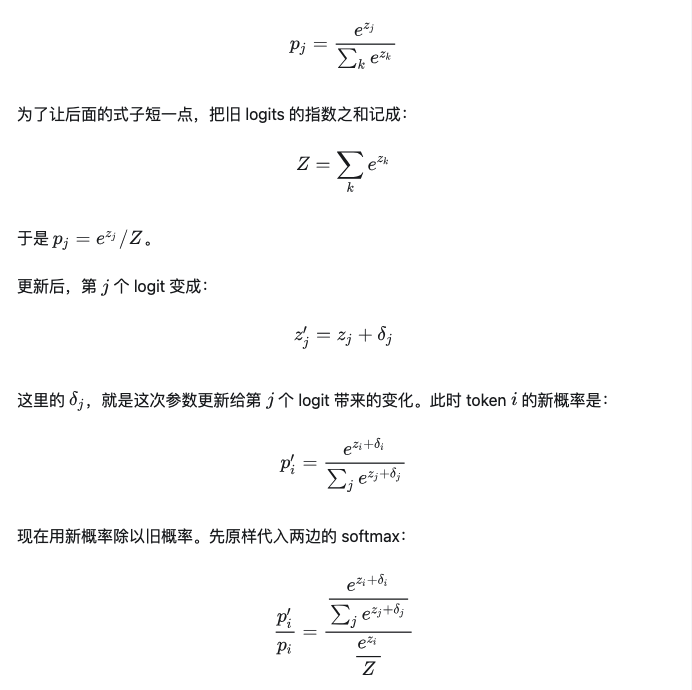

In [22]:
Image(filename='./Image/sum_0.png')

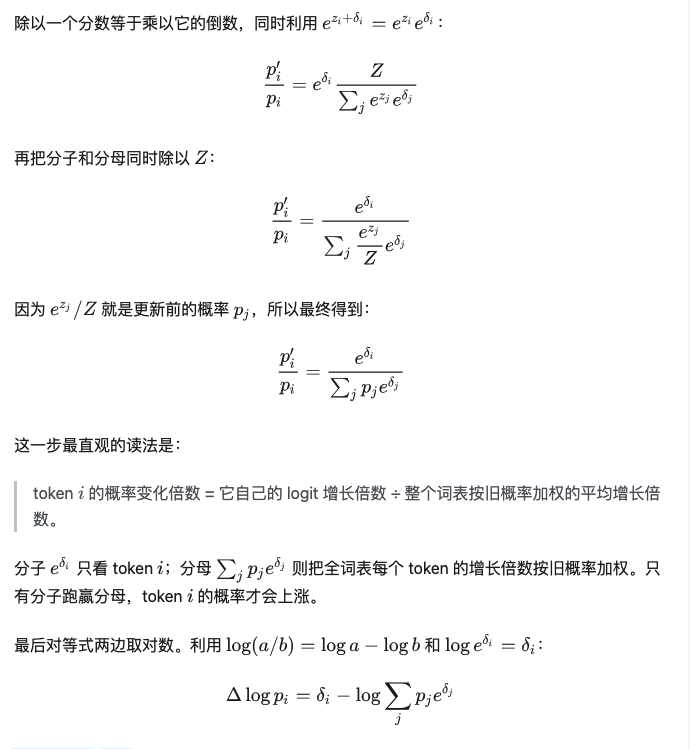

In [23]:
Image(filename='./Image/sum_1.png')

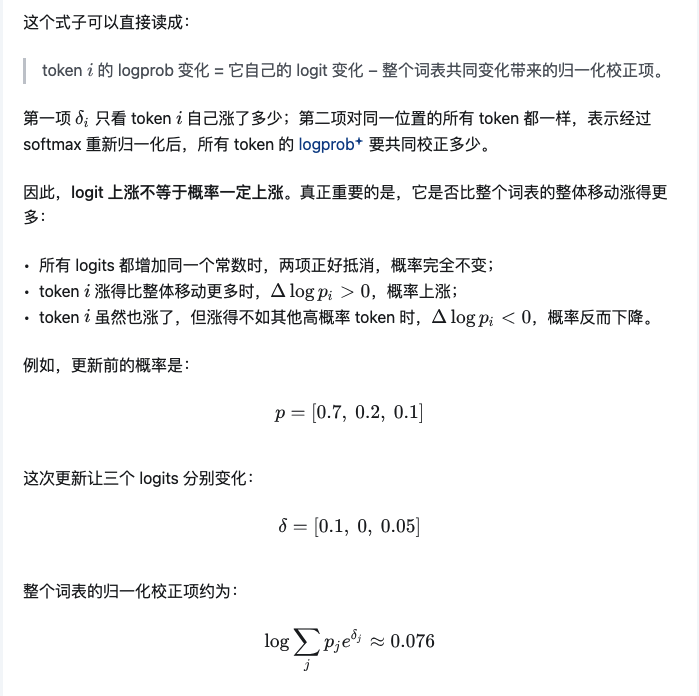

In [26]:
Image(filename='./Image/c2.1.png')

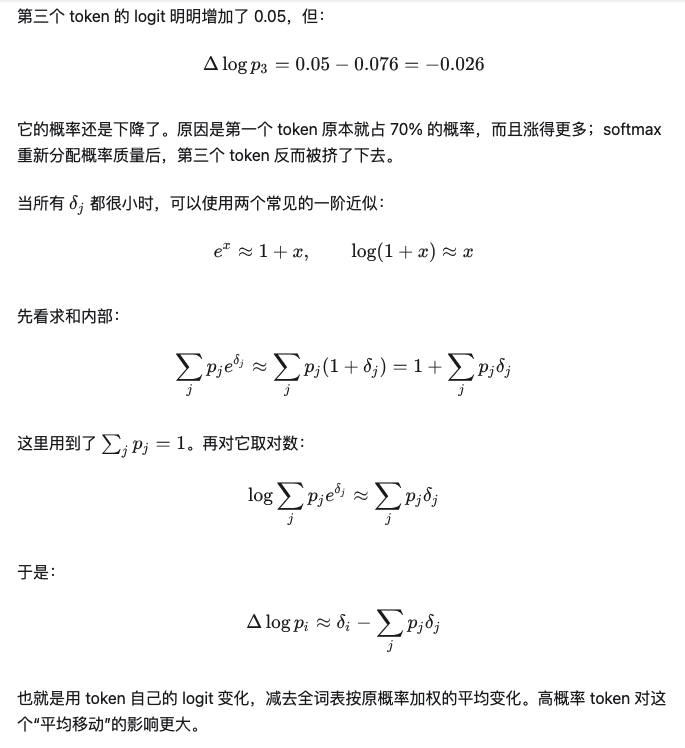

In [27]:
Image(filename='./Image/c2.2.png')

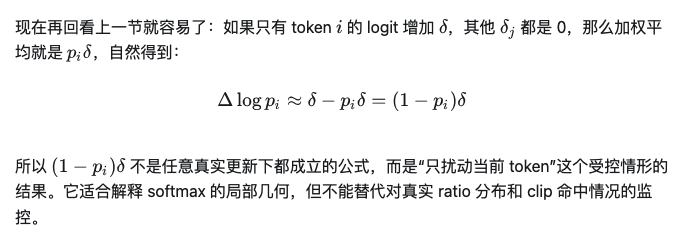

In [28]:
Image(filename='./Image/c2.3.png')

###  被上界裁掉的 token 概率低，能说明什么
DAPO 报告过一个现象：<font color='red'>命中上界的 token，其概率大多较低</font>。这与上面的局部几何是一致的。

**但这个统计不能单独证明“有价值的探索正在被压制”**。<font color='red'>被裁 token 的概率低，至少可能混着两种原因：</font>

1. <font color='red'>低概率 token</font> 在相同 logit 扰动下，本来就更容易产生较大的 log-ratio；
2. <font color='blue'>它们确实是带来新推理路径的探索 token</font>。

- 要区分两者，除了看 token 概率，还应检查它们的 advantage、所在回答的 reward、语义角色，以及解除 clip 后 pass@k 和回答多样性是否真的改善。

## 稀有 token 的问题

只说“稀有 token 出现次数少”，并不能说明 clip 对它不公平。不加 clip，它同样出现得少。

真正的问题是两个因素叠加：

- 它只有被采样出来、并拿到正 advantage 时，才有机会被往上推；
- <font color='red'>它从很低的概率成长为常见选择，需要经历很多次乘法更新</font>

### 做一个理想化计算。

假设每次有效更新都恰好允许概率乘到 1.28，并暂时忽略 softmax 中其他 token 的联动：
  - 0.001 -> 0.3
  
假设需要 n次，那么起点连续乘 n次 1.28 后，至少要达到 0.3：
  - $0.001 × 1.28^n ≥ 0.3$

移项后是 $1.28^n ≥ 300$。两边取对数：
  - $n ≥ \frac{log300}{log1.28}≈23$

而从 0.6 到 0.9，只需要跨过 1.5 倍：
  - 0.6 -> 0.9

因为 $1.28^1$ = 1.28 < 1.5，而 $1.28^2$  ≈ 1.64 > 1.5，理想情况下大约只需 2 次。

<font color='red'>这里的“23 次”不是 23 个普通 batch，而是 23 次该 token 恰好被采到、advantage 为正、并且更新方向持续一致的机会。</font>
- 真实训练还会受到其他 token、KL、学习率和数据陈旧程度影响，通常不会严格按这条路径走。

### 这个例子真正说明的是：
- 低概率路径既难被采到，又需要更多次有效推动。
- clip-high 如果过紧，会进一步减少每次机会能走的距离。
  - <font color='red'>DAPO 放宽上界，解决的是这两个因素相乘后的学习速度问题</font>

对于工具选择、意图分类等短序列、小动作空间任务，候选动作很容易被覆盖，长尾探索未必是瓶颈。此时直接照搬 clip-higher，收益通常没有长 CoT 任务那么明确。

## 命中 clip 后，什么梯度被丢掉了

现在可以回到第一节的table。PPO 对单个 token 使用的 clipped objective 是：

$L_i = min(r_iA_i,clip(r_i,1- \epsilon_{low} ,1+ \epsilon_{high}A_i$

训练要最大化这个目标。公式里有两条分支：

- $r_iA_i$：不做限制时，这个 token 能带来的收益；
- $clip(r_i,···)$：把 ratio 限在边界后，最多承认多少收益。
- min(): 取两者较小值的目的，是不让策略因为某个样本已经走得很远，仍继续获得额外收益。

### 对正 advantage token 来说，模型希望继续提高它的概率。
- 一旦 r > 1 + $\epsilon_{high}$，PPO 目标选择常数的 clipped 分支，这个样本继续向上的梯度变成 0。

#### 例如 A = 1、上界是 1.2、实际 ratio 已经到 1.3。

只要 ratio 继续保持在上界之外，右边就是常数 1.2，不再随当前策略变化，因此这条“继续上涨”的梯度为 0。

### 对负 advantage token 来说，真正会归零的是另一侧：
- 当 r < 1 - $\epsilon{_{low}}$时，继续向下压概率的梯度才会被截住。


#### 例如 A = -1、下界是 0.8、实际 ratio 已经降到 0.7。

这里 advantage 为负，乘法会把大小关系反过来，所以较小值是固定的 -0.8。ratio 再往下走，这条梯度同样保持为 0。

### 所以“clip 命中即梯度归零”少了两个条件：

<font color='red'>ratio 必须越过与 advantage 方向一致的那一侧边界，梯度才会归零</font>
这也解释了为什么只看一个总 clip fraction 不够。至少要拆成：

- 正 advantage 且命中上界的比例；
- 负 advantage 且命中下界的比例；
- 两类 token 各自的旧概率、reward 和序列位置。
否则相同的 20% clip fraction，可能对应完全不同的训练状态。

一些后续方法选择只限制 importance weight 的数值，同时保留边界外样本的梯度。
- 这样能减少“有用样本一越界就完全静音”的问题，<font color='red'>但也削弱了 PPO 原本依靠零梯度区域限制策略移动的机制</font>。它是另一种稳定性与学习效率的交换，修复并非没有成本。



## 如何调整上下界

上下界有两种常见调整方向，但它们回答的问题不同。

###  想让 log 距离几何对称
可以任选一侧作为基准：

- 固定下界 0.8，把上界放到 1/0.8 = 1.25，即 $\epsilon_{high}$ = 0.25
- 固定上界 1.2，把下界收到 1/1.2 = 0.833，即  $\epsilon_{high}$ = 0.167


解释：
#### 普通空间的不对称性：
  - 如果基准是 1。
  - 增加 20% 变成 1.2。
  - 减少 20% 变成 0.8。
  - 但在对数空间里， log(1.2)≈0.18 ，而 og(0.8)≈−0.22 。你会发现 0.18≠∣−0.22∣。也就是说，普通的“加减百分比”在对数尺度下是不对称的。
  
#### 对数空间的对称性要求：
为了让它们在 log 空间里距离相等（即几何对称），我们需要满足：
- log(r_{high})=−log(r_{low})

根据对数性质 log(a)+log(b)=log(ab) ，上述公式等价于：
- $log(r_{high})+log(r_{low})=0⟹log(r_{high} ⋅r_{low})=0$

最终推导出图片底部的结论：
- $r_{high}⋅r_{low}=1$
  - 即：上限和下限必须互为倒数。


这里用倒数，是因为 log 空间里的等距要求是：

- $logr_{high} = -logr_{low}$

移回普通 ratio 空间，就是：

- $r_{high}r_{low}$ = 1 

<font color='red'>所以一侧确定以后，另一侧必须取它的倒数</font>。第二种方案中下界是 0.833，而 1 - $\epsilon_{low}$ = 0.833，因此 $\epsilon_{low}$ = 0.167。

<font color='red'>前者扩大允许区域，后者缩小允许区域。</font>两者虽然都能得到 reciprocal bounds，但训练风险不同：

- 放宽上界，让正 advantage token 一次走得更远，也提高 overshoot 和训练不稳的风险；
- 收紧下界，更早停止负 advantage token 的下降，整体更保守。

###  想保护探索或控制熵
这时不能只看几何对称点。clip-high 和 clip-low 会截掉不同符号、不同概率区域里的梯度，对熵的作用并不由 log0.8 和 log1.2 两个数字单独决定。

参考一些已有随机 reward 的理论与实验分析结果：

- upper clip 会带来**降低熵**的作用；
- lower clip 会带来**提高熵**的作用；
- 默认配置下前者占主导，因此即使 reward 与答案无关，熵也可能下降。

<font color='red'>为什么两侧会朝相反方向影响熵？</font>可以先看它们各自阻止了什么：
  - upper clip 主要截住“正 advantage、概率已经上涨”的样本。如果这些样本中包含较多低概率 token，<font color='blue'>截住它们会阻止概率从头部流向长尾，因而更容易降低熵</font>
  - lower clip 主要截住“负 advantage、概率已经下降”的样本。它阻止一部分 token 被继续压低，相当于保留更多尾部概率，因此更容易提高熵。

这只是理解方向的直觉。真实净效应仍取决于被两侧裁掉的 token 概率分布以及命中次数，不能只看某一次更新。

这也解释了两个看起来相反、其实可以同时成立的操作：

- 增大 $\epsilon{high}$：**更晚触发 upper clip**，<font color='blue'>让正 advantage 的低概率 token 有更多上涨空间</font>
- 减小 $\epsilon{low}$： 把 lower bound 提高到更接近 1，<font color='red'>更早截住负 advantage token 的下降</font>

两者都可能提高熵，但机制不同。0.25 只能回答“log 区间是否对称”，不能回答“熵是否平衡”，更不能替代任务上的实验。

### 实际扫描时看什么
我个人会先保留默认配置，再小范围单独扫一侧，避免同时改两个参数后无法归因。每条 run 至少同时看：

1. upper/lower clip fraction，并按 advantage 正负拆开；
2. 被裁 token 的旧概率分布；
3. KL、grad norm 和实际参数更新量；
4. 训练 reward 与独立 held-out；
5. pass@1、pass@k、回答去重数和长度分布。

如果放宽上界后 pass@k 和多样性恢复，但 KL、grad norm 或 held-out 明显恶化，<font color='blue'>说明买到的探索空间已经开始以稳定性或泛化为代价。</font>



## 为什么“熵在下降”不能单独作为调参依据

<font color='blue'>熵下降可能来自至少三件不同的事：</font>

- reward 确实在把概率集中到更好的解法；
- 模型过早丢掉仍然有价值的替代路径；
- clip 机制本身带来了与 reward 语义无关的熵偏置。

只看 entropy 曲线无法区分它们。因此，“熵下降”是一个需要继续调查的现象，不是“立刻上 clip-higher”的结论。

随机 reward 对照就是用来拆开“有效 reward 信号”和“训练机制自身影响”的。最容易理解的做法，是用同一套训练配置跑两条实验：

- 真实 reward run：正确或更好的回答拿高分，差的回答拿低分；
- <font color='red'>随机 reward run</font>：保留这些分数，但随机打乱分数与回答的对应关系。



### 为什么要使用随机reward
在大语言模型（LLM）的强化学习训练中，使用随机奖励并非为了“教模型做对事”，而是作为一种诊断工具或基线对照，<font color='red'>用于判断模型性能提升是否真正源于奖励信号的指导，还是仅仅由训练机制本身（如策略梯度更新、Clip机制等）驱动的“伪学习”</font>。

#### 随机奖励的核心作用：建立“无信息基线”
随机奖励意味着模型收到的反馈与输出质量完全无关，理论上不应带来任何有意义的学习。<font color='red'>然而，实验发现，即使使用随机奖励，模型在某些任务（如数学推理）上仍可能表现出性能提升。</font>这说明：
  - 模型的性能提升可能部分来自训练过程本身的“结构化效应”，而非奖励信号的内容。
  - <font color='red'>如果真实奖励训练的熵下降速度与随机奖励基线相近，则无法证明模型发生了真正的“知识坍缩”或“过拟合”，因为这种下降可能是训练机制的自然结果。</font>
  
#### 为什么需要这个基线？
在强化学习中，我们常通过观察“熵”（Entropy）的变化来判断模型是否在“收敛”或“坍缩”。但如你提供的图片所示：
  - 真实训练的熵曲线必须与随机奖励基线比较。
  - 如果真实训练的熵下降速度显著快于随机基线，才值得警惕——这可能意味着模型正在“过度自信”地拟合错误信号，或陷入局部最优。
  - <font color='red'>如果两者接近，则说明熵的下降是训练机制的“副作用”，而非奖励信号导致的“真学习”。</font>
  
#### 随机奖励揭示的深层问题
1. 奖励信号的“信息量”可能被高估
  - 一些研究发现，<font color='red'>即使奖励是随机的、错误的，甚至与答案负相关，模型仍能在数学基准上提升20%以上</font>。
    - <font color='blue'>这挑战了传统认知：我们以为模型是在“学习正确答案”，实际上它可能只是在“学习如何响应奖励信号的结构”。</font>
2. Clip机制对熵的非对称影响
  - 如你之前提到的，Upper Clip 会降低熵，Lower Clip 会提高熵。在默认配置下，前者往往占主导。这意味着即使奖励是随机的，模型也可能因为 Clip 机制而自然趋向低熵（即更“自信”），这与奖励内容无关。
3. 模型可能在学习“奖励分布”而非“任务逻辑”
  - 随机奖励虽然无意义，但其统计特性（如均值、方差）仍可能被模型捕捉。模型可能学会“预测奖励的分布”，而不是“解决任务”。这在多轮交互或稀疏奖励场景中尤为危险。
  
#### 实践建议
- 始终运行随机奖励基线实验：在评估任何RLVR（Reinforcement Learning with Verifiable Rewards）效果时，必须包含一个随机奖励组作为对照。
- 关注熵下降的“相对速度”：<font color='red'>不要只看熵是否下降，要看它是否比随机基线下降得更快。</font>
- 警惕“伪学习”陷阱：如果模型在随机奖励下也能提升性能，说明当前评估指标可能不够敏感，或训练机制本身存在偏差。


举个例子。同一个 prompt 采了四条回答，正常评分后是：

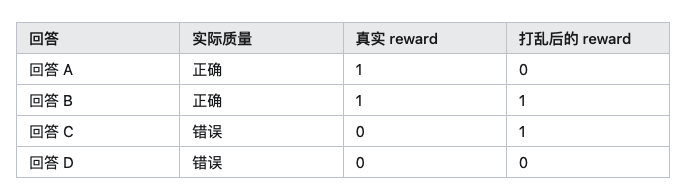

In [24]:
Image(filename='./Image/prompt.png')

- 打乱后仍然有两个 1 和两个 0，所以这组 reward 的均值、标准差以及正负 advantage 的数量都没有变化；
- <font color='red'>变化的只有一件事：高分不再稳定地属于好回答</font>

这就是“保留 reward 分布、破坏 reward 与答案的对应关系”。
- 实际实现时，<font color='red'>可以在每个 prompt 的 group 内随机排列 reward，再用打乱后的 reward 计算 advantage。</font>
   - <font color='blue'>不要跨 group 随便交换</font>，否则不同题目的均值、方差和零方差比例也会跟着变化，对照就不再只差“reward 是否有意义”这一项。

两条 run 的区别可以概括成：
- clip、学习率等训练机制还有reward 数值分布相同，<font color='red'>但是随机 reward 的 reward 不再提供正确方向。</font>

随机 reward 并不意味着模型完全没有梯度。只要一组打乱后的分数仍有高低，GRPO 就会照常算出正负 advantage，模型也会继续更新。
- 只是这些更新今天可能奖励正确答案，下一批又可能奖励错误答案，<font color='blue'>长期来看不再包含稳定的任务方向。</font>

如果这种对照下熵仍然下降，就说明：
- <font color='blue'>即使拿掉了“好答案应该得高分”这条有效信号，当前优化和 clip 机制本身仍能让分布变尖。</font>
- 因此，**真实 run 里的熵下降不能全部解释成“模型越来越确定哪个答案是正确的”**。



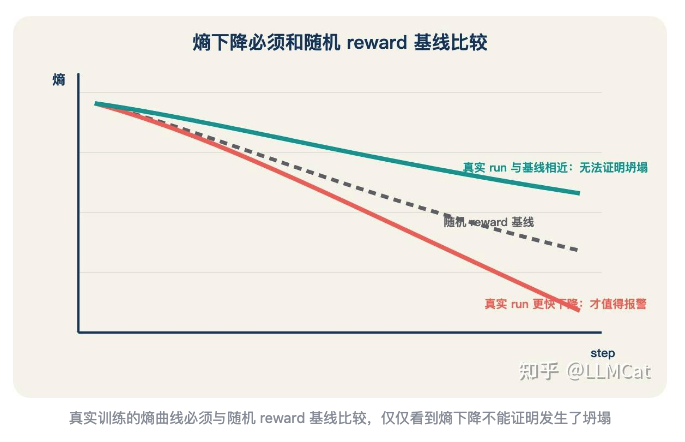

In [25]:
Image(filename='./Image/reward.png')

对比两条曲线时，重点也不是机械地判断谁下降得更快，而是问：

- 随机 reward 下是否已经存在明显的熵下降；
- <font color='red'>真实 reward 相比随机对照，多出了多少变化</font>
- 两条 run 的 upper/lower clip fraction <font color='red'>是否也出现相同趋势</font>

不过，这仍然不能单独诊断策略坍塌。两条 run 训练几步后就会生成不同的回答，数据分布会逐渐分叉，因此它不是一个永久保持其他变量完全一致的完美实验。
- 它的价值是证明“<font color='red'>训练机制自身能不能制造熵变化</font>”，而不是给熵坍塌画一条绝对判定线。

真正判断模型是否丢掉探索能力，还要回到任务表现：

- pass@1 上升时，pass@k 是否下降；
- 同一 prompt 的有效解法数量是否减少；
- held-out 和简单能力回归集是否退化；
  - 在机器学习或统计学中，'held-out' 通常指从数据集中分离出来用于测试模型性能的数据，这部分数据未被用于训练过程。
- entropy 下降主要发生在
  - **哪些 token**、
  - **哪些题型**
  - **哪些序列位置**

如果任务只是几十类的短序列分类，动作空间本来就小，低熵可能是正常收敛。此时应先看准确率、校准和类别覆盖，而不是照搬长 CoT 任务的熵阈值。

## 截断样本 vs clip
超长回答到达 max length 后会被截断。**它可能真的答错，也可能推理方向正确、只是还没写完。**
- <font color='red'>此时直接给 0 分，会把“输出不完整”和“推理错误”混成同一种负信号</font>

常见处理有两部分：
- overlong filtering(过度过滤)：<font color='red'>把真正被截断的回答从 policy loss 中排除，避免用残缺答案训练；</font>
- soft overlong punishment(温和过长的惩罚)：<font color='red'>在接近 max length、但尚未截断的缓冲区间逐渐增加长度惩罚，给模型连续的提前刹车信号</font>

### DAPO 同时使用了这两项。它并不是用 soft punishment 替代 filtering。

两者的作用位置不同。
- filtering 处理的是已经撞到 max length、答案被截断以后怎么办；
- soft punishment 处理的是回答还没被截断、但长度已经接近上限时，怎样提前给出逐渐增强的提醒。
- <font color='red'>前者避免错误监督，后者补回连续的长度方向</font>

### mask 不会自动鼓励长回答
<font color='red'>被 mask 的回答既不受奖励，也不受惩罚。因此，“mask 会直接鼓励模型越写越长”这种说法并不准确。</font>
- 更准确的说法是：
  - <font color='red'>mask 移除了截断样本上的直接负反馈</font>。
    - 如果系统中还存在其他把长度往上推的因素，例如 response-level loss 让长回答中的每个 token 权重更小，那么缺少截断反馈会让这种趋势更难被拉回来

DAPO 的 token-level policy gradient loss、overlong filtering 和 soft punishment 分别处理三个问题：

  - token-level loss : <font color='red'>避免长回答中的单个 token 被过度稀释</font>
  - filtering : <font color='red'>避免残缺输出污染 reward</font>
  - soft punishment: <font color='blue'> 在真正截断前提供连续长度信号</font>
<font color='blue'>三者可以配合，但不能把其中任何一项单独写成长度问题的唯一根因</font>

### 被 mask 的样本是否参与 advantage 统计
必须要检查的：假设被截断回答的 reward 记为 0：

- 如果它不进 loss、但仍参与组内均值和标准差，它会把统计量往 0 拉，进而改变其他回答的 advantage；
- <font color='red'>如果它在计算均值和标准差之前就被排除，有效 group size 会变小，方差估计和零方差比例也会变化。</font>

例如一组 reward 是 [1,1,0,**0**]，最后一个 0 来自截断：

  - 若截断样本仍参与统计，组均值是 0.5；
  - 若先排除它再统计，剩下 [1,1,0]，组均值变成 2/3

同样三条未截断回答，仅仅因为统计口径不同，就会拿到不同的 advantage。
- 这就是为什么“从 loss 中 mask”与“从 advantage 统计中排除”<font color='red'>必须分别说明</font>

两种做法优化的目标不同，没有一个能在所有任务上无代价胜出。真正危险的是：
- 代码一处按第一种口径、一处按第二种口径，而日志又没有把有效样本数打出来。

至少应该记录：

- 每个 group 被截断和被 mask 的数量；
- advantage 统计前后的有效 group size；
- 截断样本是否参与 reward mean/std；
- mask 前后的 token denominator(分母)。

## 总结
clip 这件事可以按四步理解：

- ratio 是新旧概率之比；<font color='red'>log-ratio 是新旧 logprob 的差，用它可以比较策略走了多远。</font>
- 默认 [0.8,1.2]在 log 空间并不对称，**但这种几何不对称本身不足以证明熵必然下降。**
- 在“只改变当前 token logit”的局部分析里，低概率 token 的 log-ratio 更接近完整的 logit 扰动，因此同一条上界对它更紧；真实参数更新同时改变整个词表，不能把这个近似当成无条件定理。
- 是否应该调 clip，要看上下界分别裁掉了哪些梯度，以及 pass@k、held-out、KL 和多样性怎样变化。entropy 只能报警，不能独立给出调参方向。

0.25 是默认下界对应的 log 几何对称点，不是通用最优值。
- clip-higher 适合解决“正 advantage 的低概率 token 太早被静音”，
- 收紧 clip-low 则是另一种控制熵的手段。两者改变的梯度区域和稳定性代价不同。

截断样本属于 reward 与 loss mask 的问题线。filtering、soft overlong punishment 和 token-level loss 各自处理不同环节，不应该都归因于 clip。

下一篇换到另一类问题：训练崩溃的分层排查顺序，以及两侧引擎概率不一致这条最致命的线索怎么查。

# GRPO<font color='red'>训练崩溃</font>的分层排查顺序

本系列文章会分享 GRPO 排查的经验。以及我作为面试官，考查 post-training 方向候选人时，是如何判断对方是否有对应的能力。
前面几篇讨论的是策略坍塌：<font color='red'>reward 可能还在上涨，但模型的回答逐渐变得单一</font>。

这一篇讲另一种更突然的问题——<font color='red'>训练崩溃</font>。


常见表现包括：

- reward 在某个 step 后断崖式跌到 0；
- KL、grad norm 或 ratio 突然跳高；
- 输出从正常推理变成复读、乱码或大量截断；
- loss、logprob 或梯度里出现 NaN/Inf；
- 从某个 checkpoint 继续训练，很快又在相似位置崩掉。

遇到这种问题，最浪费时间的做法是立刻扫学习率。
 - 训练崩溃经常来自概率、mask 或数值路径上的**工程错误**；
 - <font color='red'>这些错误没有“更合适的学习率”，只有写对和写错</font>。

我通常按下面的顺序排查：

展示了一套针对强化学习（特别是 GRPO 算法）训练崩溃问题的分层排查指南。

它的核心思想是：
- 当模型训练效果不佳或崩溃时，不要一上来就怀疑复杂的奖励函数，<font color='red'>而应该按照从底层数据到上层逻辑的顺序，由简入繁地进行“0/1 检查”</font>

## 以下是对图片中各个排查步骤的详:

“前一层不通过，后一层的曲线就没有解释意义”。
- 这意味着这是一个严格的依赖链条。如果最基础的数据读取或概率计算都是错的，那么后续调整学习率或奖励函数不仅无效，甚至会产生误导。

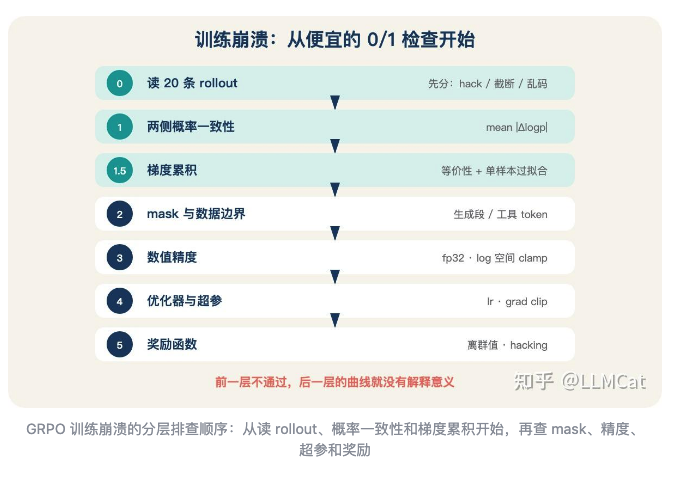

In [29]:
Image(filename='./Image/train_step.png')

详细排查步骤:

### 0.读 20 条 rollout
这是最基础的数据完整性检查。
  - 操作：随机抽取 20 条模型生成的轨迹数据进行人工或脚本审查。
  - 检查点：
    - Hack：模型是否找到了刷分的捷径？（<font color='red'>例如重复输出特定字符来骗取奖励</font>）。
    - 截断：生成内容是否被异常截断，导致无法完成逻辑闭环？
    - 乱码：输出是否包含大量无意义的 Token？
  - 目的：确保输入给训练流程的数据是干净、完整且符合预期的。
  
### 1.两侧概率一致性(此处解释有误)
这是代码逻辑正确性检查，通常用于验证 PPO/GRPO 中的重要性采样比率计算。
  - 指标：mean |Δlogp|（对数概率变化的绝对值均值）。
  - 含义：在强化学习中，我们需要计算新策略和旧策略的概率比值。如果代码实现有误（例如旧模型的参数没有冻结好，或者计算图构建错误），会导致这个比率计算错误。
  - 目的：确保“新旧策略”的对比是在同一个基准上进行的，防止因代码 Bug 导致梯度方向完全错误。
  
#### 1.5. 梯度累积
这是针对小 Batch Size 训练的稳定性检查。
  - 概念：当显存不足以支持大 Batch Size 时，**通常使用梯度累积来模拟大 Batch**。
  - 检查点：
    - 等价性：<font color='red'>累积梯度的效果是否真的等同于大 Batch 训练？（需检查归一化系数是否正确）。</font>
    - 单样本过拟合：如果在累积过程中，模型过度拟合了某一个特定的样本，会导致梯度方差极大。
  - 目的：保证在资源受限情况下的数学等价性。
  
### 2.Mask 与数据边界
这是注意力机制与损失计算范围的检查。
  - 检查点：
    - 生成段：Loss 是否只计算了模型生成的部分，而忽略了 Prompt 部分？
    - 工具 Token：如果涉及函数调用，特殊的工具 Token 是否被正确地 Mask 掉或包含在内？
  - 目的：防止模型去“背诵”题目（Prompt），或者因为计算了不该计算的 Token 导致梯度噪声。
  
### 3.数值精度
这是计算机浮点数运算的稳定性检查。
  - 检查点：
    - fp32：关键计算（如 Loss 计算、Log_prob）是否在 fp32（单精度浮点数）下进行？混合精度训练（fp16/bf16）容易导致极小概率值下溢为 0，导致 Log 计算出现 -inf。
    - log 空间 clamp：是否对 Log 值进行了截断保护，防止数值爆炸？
  - 目的：<font color='red'>消除因计算机精度限制导致的非预期 NaN 或 Inf 错误</font>
  
### 4.优化器与超参
这是训练动力学的检查。
  - 检查点：
    - lr (Learning Rate)：学习率是否过大导致震荡，或过小导致不收敛？
    - grad clip (梯度裁剪)：是否设置了合理的梯度裁剪阈值，防止梯度爆炸摧毁模型权重？
  - 目的：确保优化过程是平滑且可控的。
  
### 5.奖励函数
这是最高层级的语义检查，也是最后才需要怀疑的地方。
  - 检查点：
    - 离群值：Reward 分布是否有极端异常值？（例如某个样本给了 100 分，其他都是 0 分，这会主导梯度）。
    - Hacking：奖励函数的设计是否有漏洞，导致模型可以通过非预期行为获得高分？
  - 目的：确保模型真正在学习你想要的目标，而不是在钻规则的空子。
  
### 总结
这张图提供了一套非常务实的工程化思维：
- <font color='red'>先排除低级错误（数据、代码、精度），再调整高级策略（超参、奖励）</font>
- 在复杂的 GRPO 训练中，绝大多数“训练崩溃”往往不是因为奖励函数写得不好，<font color='blue'>而是因为前几层的基础设施（如 Mask 写错、精度溢出）出了问题</font>

##### 这个顺序的判断标准很简单：

<font color='red'>前一层如果没有通过，后一层的曲线就很难解释。</font>
  - 例如，ratio 的分子和分母不是同一套概率口径时，clip fraction、KL 和学习率扫描都会失去原来的含义。 
     - 因此先做便宜、结论接近“通过/不通过”的检查，最后才讨论需要权衡的超参和 reward。

## 零、<font color='red'>先锁定“第一个出问题的 step”</font>

不要只保存崩溃后的曲线截图。真正有价值的是三份状态：

1. 最后一个正常 step；
2. 第一个出现异常的 step；
3. 异常之后的一个 step。

### 把这三个 step 的以下信息保存下来：

- prompt、完整 rollout 和截断标记；
- reward 总分及每个分项；
- old/current logprob、log-ratio 和 ratio 分位数；
- attention mask、loss mask 和有效 token 数；
- clip fraction、KL、裁剪前后的 grad norm；
- batch ID、随机种子、checkpoint 和 optimizer state。

### 然后先读二十条左右的原始输出，<font color='red'>不要急着看均值</font>

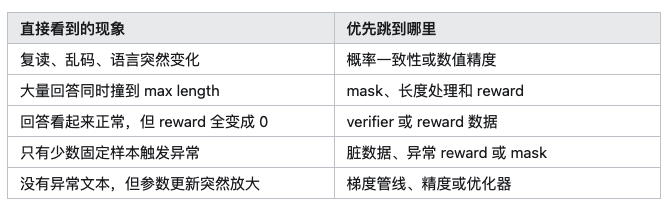

In [30]:
Image(filename='./Image/state.png')

### RL 训练崩溃调试器 (RL Crash Debugger)

在实际的大模型强化学习（RLHF/GRPO/PPO）训练流程中，<font color='red'>实现“锁定崩溃节点并保存上下文”通常依赖于对训练循环（Training Loop）的定制化改造</font>

以下是使用 Python 和 PyTorch 风格伪代码给出的完整排查与调试代码示例，它模拟了如何捕获状态、保存快照以及进行单样本调试。

In [ ]:
import torch
import json
import copy

class RLTrainingDebugger:
    def __init__(self, save_dir="./debug_snapshots"):
        self.save_dir = save_dir
        # 初始化状态缓存
        self.last_normal_step = None
        self.first_abnormal_step = None
        self.post_abnormal_step = None

    def check_and_save_snapshot(self, step, batch_data, model_output, optimizer, is_abnormal):
        """
        核心逻辑：在训练循环中调用，判断当前 step 是否异常，并按规则保存状态。
        """
        # 1. 提取关键信息 (对应图片中要求的各项指标)
        snapshot = {
            "step": step,
            "prompts": batch_data["prompts"],           # prompt
            "rollouts": batch_data["rollouts"],         # 完整 rollout
            "truncation_masks": batch_data["trunc_mask"], # 截断标记
            
            "reward_scores": model_output["reward_dict"], # reward 总分及每个分项
            "total_rewards": model_output["total_rewards"],
            
            "old_logprobs": model_output["old_logp"],   # old logprob
            "current_logprobs": model_output["curr_logp"], # current logprob
            "log_ratio": model_output["log_ratio"],     # log-ratio
            "log_ratio_quantiles": torch.quantile(model_output["log_ratio"], q=torch.tensor([0.1, 0.5, 0.9])).tolist(), # ratio分位数
            
            "attention_mask": batch_data["attn_mask"],
            "loss_mask": batch_data["loss_mask"],
            "effective_tokens": batch_data["eff_tokens"], # 有效 token 数
            
            "clip_fraction": model_output["clip_frac"], # clip fraction
            "kl_divergence": model_output["kl"],        # KL
            "grad_norm_before_clip": model_output["grad_norm_before"], # 裁剪前的 grad norm
            "grad_norm_after_clip": model_output["grad_norm_after"],   # 裁剪后的 grad norm
            
            "batch_id": batch_data["batch_id"],
            "random_seed": torch.initial_seed(),        # 随机种子
            
            # 保存完整的模型和优化器状态
            "model_state_dict": copy.deepcopy(model_output["model"].state_dict()), 
            "optimizer_state_dict": copy.deepcopy(optimizer.state_dict())
        }

        # 2. 锁定“第一个出问题的 step” (实现图片中的三份状态逻辑)
        if is_abnormal:
            if self.first_abnormal_step is None:
                # 记录第一个出现异常的 step
                self.first_abnormal_step = snapshot
                
                # 保存快照文件 (异常前、异常中、异常后)
                if self.last_normal_step is not None:
                    self._save_file(f"step_{self.last_normal_step['step']}_last_normal.pt", self.last_normal_step)
                
                self._save_file(f"step_{step}_first_abnormal.pt", self.first_abnormal_step)
        else:
            # 记录最后一个正常 step
            self.last_normal_step = snapshot
            
            # 如果在异常后又恢复正常（极少情况，或者用于对比），记录异常后的 step
            if self.first_abnormal_step is not None and self.post_abnormal_step is None:
                 self.post_abnormal_step = snapshot
                 self._save_file(f"step_{step}_post_abnormal.pt", self.post_abnormal_step)

        # 3. 调试阶段：读取原始输出 (不要着急看均值)
        if step == self.first_abnormal_step['step'] or (self.last_normal_step and step == self.last_normal_step['step'] + 1):
            self._inspect_raw_rollouts(snapshot, step)

    def _save_file(self, filename, data):
        """保存调试快照"""
        path = f"{self.save_dir}/{filename}"
        torch.save(data, path)
        print(f"✅ Debug snapshot saved to {path}")

    def _inspect_raw_rollouts(self, snapshot, step):
        """
        对应图片提示："然后先读二十条左右的原始输出，不要着急看均值"
        这里可以根据现象直接跳转到特定排查模块
        """
        print(f"\n🔍 Inspecting raw rollouts at step {step}...")
        rollouts = snapshot["rollouts"]
        rewards = snapshot["reward_scores"]
        
        for i in range(min(20, len(rollouts))):
            text = rollouts[i]
            reward = rewards[i]
            
            # 现象排查映射 (对应图片底部的表格)
            if "�" in text or len(text.split()) < 2:
                print(f"  [WARNING] Rollout {i} contains garbage/repetition. -> Check: 概率一致性或数值精度")
            elif text.endswith("...") and reward.get("length_penalty", 0) < -1.0:
                print(f"  [WARNING] Rollout {i} hit max length. -> Check: mask, 长度处理和 reward")
            
            # 打印原始数据供人工检查
            print(f"  Rollout {i}: {text[:100]}... | Reward: {reward}")


# ================= 模拟训练循环 =================
def simulate_training_loop():
    debugger = RLTrainingDebugger()
    
    # 模拟数据
    batch_data = {"prompts": ["Q: 1+1="], "rollouts": ["A: 2"], "attn_mask": [[1,1,1]], "loss_mask": [[0,1,1]], "eff_tokens": 1, "batch_id": 0, "trunc_mask": [False]}
    optimizer = torch.optim.Adam([torch.tensor([1.0])])
    
    for step in range(100):
        # 模拟正常训练
        is_abnormal = False
        
        # 模拟在第 42 步发生崩溃 (例如 reward 突然变成 0)
        if step == 42:
            is_abnormal = True
            batch_data["rollouts"] = ["A: 222222222222222222222222222222"] # 触发复读
            
        # 模拟正常的前向/后向传播并产出 output
        dummy_output = {
            "reward_dict": {"accuracy": 1.0}, "total_rewards": 1.0,
            "old_logp": torch.randn(1, 10), "curr_logp": torch.randn(1, 10),
            "log_ratio": torch.randn(1, 10),
            "clip_frac": 0.0, "kl": 0.01, "grad_norm_before": 0.5, "grad_norm_after": 0.4,
            "model": torch.nn.Linear(10, 10) # 仅作占位
        }

        # 调用调试器进行检查
        debugger.check_and_save_snapshot(step, batch_data, dummy_output, optimizer, is_abnormal)
        
        # 正常训练逻辑...
        # optimizer.step()

if __name__ == "__main__":
    simulate_training_loop()

#### 代码逻辑与图片要求对照说明：
1. 三份状态的锁定 (check_and_save_snapshot)：
  - 代码通过 is_abnormal 标志位来拦截崩溃瞬间。
  - self.last_normal_step 缓存了最后一个正常步。
  - <font color='red'>一旦检测到 is_abnormal == True 且 self.first_abnormal_step 为空，立刻将其定格并触发文件保存。</font>
2. 详尽的信息保存 (snapshot 字典)：
  - <font color='red'>代码中将 log-ratio、clip fraction、grad norm、optimizer state 等指标全部封装进了 snapshot，并调用 torch.save 落盘。这保证了后续可以使用 torch.load 完全复原崩溃现场。</font>
3. 拒绝均值，直面原始数据 (_inspect_raw_rollouts)：
  - 图片明确指出“不要着急看均值”。代码中的 _inspect_raw_rollouts 方法会在保存快照时，自动打印前 20 条 rollouts 的文本和具体得分。
  - 同时，代码内置了简单的启发式规则（如检查乱码 �、检查长度惩罚），直接对应了图片底部表格中的“直接看到的现象 -> 优先跳到哪里”。

### 如果可以复现，再做一次最重要的区分：

- <font color='red'>同一个 batch 每次都在同一位置失败</font>：优先查数据、mask、reward 和确定性的数值错误
- <font color='red'>换 batch 也总在相近 global step 失败</font>：优先查学习率调度、optimizer state、数据陈旧和累计漂移；
- <font color='red'>失败位置完全随机</font>：再考虑异步权重同步、未初始化值、非确定 kernel 或硬件问题
这一步的目标不是马上找到根因，而是把“整个训练坏了”缩小成一个可以反复重放的最小故障窗口。

## 第 1 步：先证明新旧概率可以比较
GRPO/PPO 使用 importance ratio：

$r_t(\theta) = \frac{\pi_\theta(a_t | s_t)}{\pi_{\theta_{old}}(a_t | s_t)}$

- 分子是当前训练策略的概率，
- 分母是生成 rollout 时旧策略的概率。
<font color='red'>这个比值有一个基本前提：两边除了参数版本，其他计算口径必须一致</font>

### 为什么需要“对齐”？——口径不一致的后果
如果新旧概率的计算口径不同（比如旧策略用的是采样后的概率，新策略用的是原始 logprob），那么 
$r_t(θ)$ 就不是纯粹的“策略更新比率”，而是包含了两套实现差异的混合信号。例如：
- 旧策略用 temperature=1.0 采样，新策略用原始 logprob（无温度）计算：此时 ratio 会包含温度带来的概率缩放，而非策略本身的更新；
- 旧策略的 tokenizer 用了特殊 token（如 \<pad>），新策略没对齐：此时 token ID 的映射不一致，概率计算的基础都错了。
    
对训练者来说，这种“额外差异”看起来像测量误差（比如 loss 波动、reward 不稳定）；但从算法本质看，真正生成 token 的行为分布已经和训练侧假定的 $π_{old}$不同——也就是说，我们以为在更新“旧策略”，但实际上旧策略的分布已经变了，导致更新方向偏离预期。

### 需要对齐或明确记录的东西包括：

- token IDs、chat template 和特殊 token；
- prompt 与 completion 的边界；
- position IDs 和 attention mask；
- 推理引擎返回的是原始模型 logprob，<font color='red'>还是经过 temperature、top-p、重复惩罚等采样处理后的 logprob</font>
  - 原始 logprob：模型输出的未经过任何处理的 token 概率（如 model.logits.softmax(-1).log()）。
  - 采样后的 logprob：经过 temperature、top-p、重复惩罚等采样处理后的概率（如 logits / temperature 后的 softmax 概率）。
- 权重版本、LoRA 合并方式和 tied embeddings；
- **量化、MoE router 以及推理/训练 kernel 带来的实现差异**。
  - 量化：如果旧策略是 FP16 模型，新策略是 INT8 量化模型，量化带来的权重误差会导致概率计算差异（比如 INT8 的量化误差会让概率更粗糙）。
  - MoE Router：混合专家模型（MoE）的 router 机制（如 top-k 选择专家）必须一致。例如，旧策略用 top-2 专家，新策略用 top-1 专家，会导致每个 token 的计算路径不同，概率分布不同。
  - Kernel 实现：推理和训练的 kernel（如 attention 的 flash attention、softmax 的 kernel）必须一致。例如，旧策略用 flash attention v1，新策略用 v2，v2 的数值稳定性更好，会导致概率计算的精度差异（比如 v1 的 softmax 有溢出风险，v2 没有），进而影响 ratio。

<font color='red'>如果两边口径不同，ratio 中混入的就**不只是**“策略更新”</font>，还包含两套实现造成的额外 policy mismatch。
- 对训练者来说，它看起来像测量误差；
- <font color='red'>但从算法上说，真正生成 token 的行为分布已经和训练侧假定的 ($\pi_{\text{old}}$) 不同</font>。无论怎么命名，都不能把它静默当成一次正常的参数更新。

### 最小一致性测试
- 先冻结权重，不做 optimizer step，并关闭 dropout、固定 batch 组织；
- 如果仍有随机算子，要在每次前向前恢复到同一个 RNG state。然后对同一批完整 token 序列做三次计算：
  - RNG state:在最小一致性测试中，RNG state 指的是随机数生成器的状态，确保每次计算时随机性的一致性。

1. 在训练框架中前向一次，得到 logprob A；
2. 不改权重，再在训练框架中前向一次，得到 logprob B；
3. 用生成 rollout 的推理引擎计算同一批 token，得到 logprob C。这里应尽量读取采样处理之前的原始模型 logprob；如果接口只能返回处理后的值，就必须把这些处理单独记下来，不能直接和训练侧混比。

#### 三次计算分别测什么？
代码中对同一批数据做了三次 logprob（对数概率）计算，**它们承担着不同的排查任务**：
- 计算 A（训练框架内前向传播）：作为训练侧的基准。
- 计算 B（不改变权重，在训练框架内再次前向传播）：
  - 对比 A 与 B：检查训练框架自身的可重复性。
  - 目的：如果你不做 optimizer step 且关闭了所有随机性，A 和 B 的结果理论上应该完全一模一样。如果 A 不等于 B，说明你的训练代码内部有隐藏的 bug（例如某些层的内部状态没被正确重置，或者数据读取时发生了隐式的重排），导致每次跑的结果都不一样。
- 计算 C（使用生成 rollout 的推理引擎计算）：
  - 对比 A 与 C：检查推理侧和训练侧是否一致。
  - 目的：这是 RL 训练中最容易出大问题的地方。PPO/GRPO 训练时，我们通常用“推理引擎（如 vLLM）”来生成 rollout（采样），然后用这个 rollout 的 logprob 作为分母（旧策略）；而分子是用“训练框架（如 PyTorch）”算的（新策略）。如果这两个引擎算同一个 token 的 logprob 竟然不一样，那你的 Ratio 从一开始就是错的。

#### 分别比较：
  - A 与 B：检查训练框架自身是否可重复；
  - A 与 C：检查推理侧和训练侧是否一致。
  
至少记录 mean、P99 和 max 的 ($|\Delta\log p|$)，并按 token 位置、序列长度以及常见/低频 token 拆分。
- 不要只看平均值；少数异常 token 才可能是 ratio 和梯度爆炸的起点。如果还想判断误差从哪一层开始出现，需要额外比较中间层输出，不能只靠最终 logprob 反推。

这里不建议照抄一个全行业阈值。先在确认干净的配置上量出 baseline，再看故障 run 是否明显偏离。

这个测试其实包含两个不同的判据：

  - 对 A 与 B，参数和实现都没有变化，因此 ($\exp(A-B)$) 应该非常接近 1；否则先查随机性、输入或训练框架自身的可重复性。
  - 对 A 与 C，两套实现可以有小的数值差，但差异应接近干净 baseline，且不应让大量 token 的 ratio 在尚未更新时就撞到 PPO clip。
  
因此真正的硬判据不是要求所有后端逐 bit 相同，而是：
- 权重完全没变时，实现差异不能被训练目标误认为一次明显的策略更新；如果尚未训练，ratio 就已经大面积撞 clip，应先停止调参并修正概率口径。

推理引擎与训练框架之间允许存在小的数值差，但这部分差异需要被单独量出来，不能静默混进策略更新。如何选择 old logprob、怎样做 off-policy 修正，以及 MoE 为什么更敏感，下一篇会展开。

#### 权重同步不能只看“调用成功”
很多同步问题不会报错。建议至少增加三类检查：

- 同步完成后随机抽几层参数，比较训练侧源权重和推理侧目标权重的 checksum 或数值摘要；
- 固定一个 prompt，先保存训练侧当前权重的首 token logits，再检查同步后的推理侧是否与它接近；
- 把生成时的 policy version 写进 rollout 元数据，训练时确认 old logprob 确实来自该版本，并限制数据陈旧程度。

这里不能简单地“只要版本不同就拒绝”。PPO/GRPO 本来就允许当前策略和生成数据的旧策略不同，否则也不需要 importance ratio。<font color='red'>真正要拒绝的是版本来源不明、old logprob 与生成权重对不上，或者超过系统允许陈旧范围的数据。</font>

LoRA merge、共享输入输出 embedding、分片参数和量化副本尤其容易出现“流程执行了，但某部分权重没有更新”的情况。


## 第 1.5 步：验证梯度加工流水线
logprob 算对了，并不代表参数最终收到了正确梯度。逐 token loss 还要经过：

 1. token/sequence 聚合；
 2. micro-batch 缩放；
 3. gradient accumulation；
 4. data-parallel rank 间归约；
 5. grad clip 和 optimizer step。
 
任意一层多除或少除一次 batch size、漏掉一个 micro-batch，都会改变实际更新幅度。曲线可能看起来“只是学习率不合适”，但怎么扫都不稳定。

### 梯度累积等价性测试
固定同一批 (N) 条样本和相同参数，关闭 dropout 或固定每次前向使用的随机数，并保持样本顺序、mask 和有效 token 完全一致。然后比较两种执行方式：

  - 一次把 (N) 条样本作为一个 batch 反向；
  - 每次放 1 条，累积 (N) 次后再更新。
  
比较时不要只盯某个参数的绝对误差。更有用的是：

  - 两次 loss 是否采用同一种 denominator(分母)，例如都除以有效 token 总数，而不是一边先按样本求均值、另一边直接按全部 token 求均值
  - 梯度总 norm 的相对差
  - 梯度向量 cosine similarity
  - 一次 optimizer step 后参数 delta 的相对差。
  
fp32 单卡下应该非常接近；bf16、分布式归约和不同 kernel 会带来更大的舍入误差，因此不适合机械规定“必须小于 ($10^{-6}$)”。如果方向明显不同，或 norm 恰好差 accumulation steps、world size、有效 token 数这类整数倍，通常就是缩放或归约写错了。

### 用简单目标测试“梯度能否到达参数”
“拿几条 RL 样本，要求 PPO loss 降到 0”不是一个稳妥的通用测试，因为 clip 本来就会让一部分样本提前进入零梯度区。

更干净的办法是暂时绕开 reward、ratio 和 clip，使用一个很小的确定性监督目标：

固定 4～8 条 prompt-completion；
只对 completion token 计算普通 NLL；
使用 fp32、小模型或少量可训练参数；
重复训练，确认 loss 能稳定下降并接近过拟合。
如果这个测试都失败，应优先检查参数冻结、loss mask、梯度累积、分布式归约、学习率和 optimizer step；此时没有必要继续检查 GRPO 特有的超参。

但这个测试只证明“普通监督 loss 的梯度能够到达参数”，不能证明 GRPO 特有的 advantage、ratio、clip 和 policy loss 都写对了。基础链路通过以后，还要分别为这些模块做小规模的数值对照。

## 第 2 步：逐 token 检查 mask 和数据边界
这里至少有两种 mask：

attention mask：模型在前向时能不能看见这个位置；
loss mask：这个位置是否作为训练目标产生梯度。
模型可以“看见但不学习”某些 token。例如在本文讨论的纯 policy loss 中，工具返回、环境 observation 和用户输入都需要作为上下文被看见，但不应该作为模型生成的目标。如果额外混入了 SFT 等辅助目标，则要为不同目标分别定义 mask，不能共用一张表含糊带过。

### 不要只看 mask 的 shape
最有效的检查方式，是把一条真实样本逐 token 打印成表：

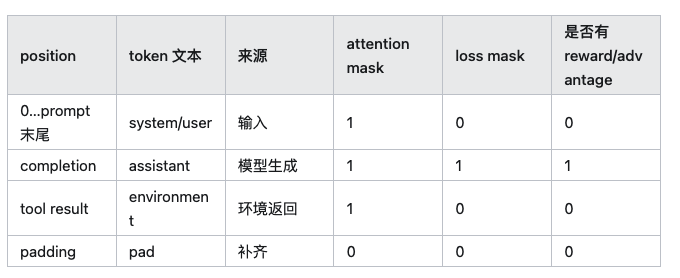

In [31]:
Image(filename='./Image/token.png')

再加几条运行时断言：

- loss mask 的和等于真正参与训练的 completion token 数；
- 在纯 policy loss 中，padding、prompt 和 environment token 的 loss mask 必须为 0；
- EOS 是否训练，要和生成停止规则保持一致；
- 每个被 mask 的样本都要有明确原因和计数。

### 多轮和工具调用最容易静默出错
在最常见的 agent 训练设置中，工具返回的 token 通常应满足：


模型需要读取工具结果继续决策，但不应该学习“假装自己是工具”。自定义 rollout 时，不能假设通用 attention mask 会自动推导出正确的 loss mask；必须沿着 loss 构造代码确认最终使用的布尔 mask。

### 截断样本要同时检查三处
回答撞到 max length 后，至少要明确：

它的 reward 如何定义；
它是否参与组内 reward mean/std；
它的 token 是否进入 policy loss。
这三个开关不是一回事。只在 loss 中 mask 掉样本，却仍让它的 0 reward 参与 advantage 统计，会继续改变同组其他回答的权重。反过来，如果在统计前排除，有效 group size 和零方差比例也会变化。

## 、第 3 步：沿着数值路径找第一个 NaN/Inf
不要只在 optimizer step 后检查参数。应该沿计算顺序逐层加 finite assertion：


哪个张量最先出现非有限值，根因通常就在它之前一两步。

### 关键差值和指数运算使用 fp32
bf16 很适合大矩阵乘法，但有效位数有限。GRPO 中最敏感的往往不是单个大数，而是两个接近的 logprob 相减：


如果两边先以低精度存储，小差异可能被量化成 0，或出现明显相对误差。实践中至少应确保：

- log-softmax 的归约使用 fp32；
- gather 出来的 selected-token logprob 在做差前转成 fp32；
- log-ratio、KL 估计和 exp 前的保护逻辑在 fp32 中执行。
这不等于要求整个模型的 logits 永久以 fp32 保存。重点是把精度放在归约、相减和指数这些敏感环节。

### 先限制 log-ratio，再取指数
ratio 的计算是：


如果 (\Delta\log p) 已经大到让 exp 溢出，ratio 会先变成 Inf。之后再 clamp ratio，前向结果看似回到有限值，反向仍可能遇到：


原因是 ratio 超出上限时，clamp 的局部梯度是 0；而 exp 的反向需要乘上它的输出 Inf。

正确顺序是：

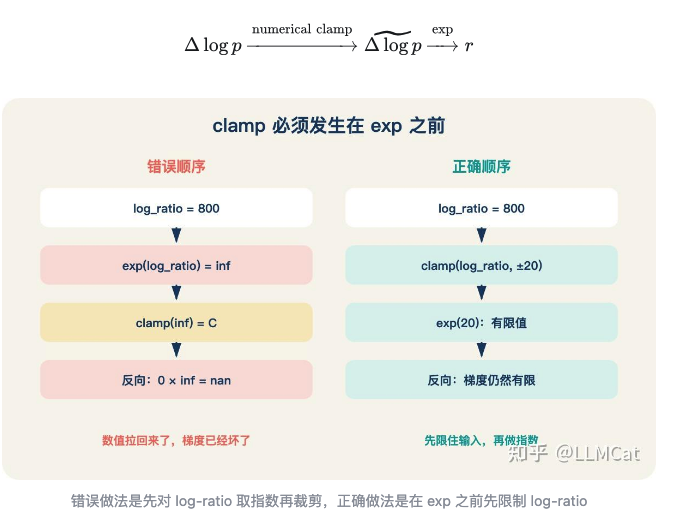

In [32]:
Image(filename='./Image/clamp.png')

这个 clamp 是防止异常值把计算图炸掉的保险丝，不是 PPO clip 的替代品。还要记录它的命中率；正常训练如果频繁撞到保险丝，应该回头查概率一致性和数据陈旧，而不是继续收紧它。

### 几种“限制”不要混在一起
不同代码库里可能出现下面几类限制：

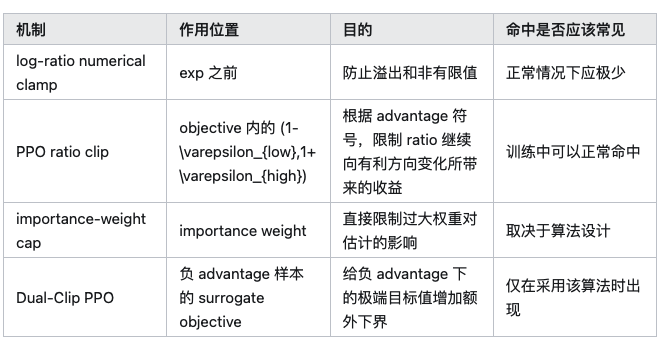

In [33]:
Image(filename='./Image/limit.png')

标准 PPO/GRPO 不一定包含后两项；看到配置名时，应先确认公式和作用位置，不能只根据名字猜实现。

不能通过“参数值看起来像 0.2、2 或 20”来判断它属于哪一种，必须看它作用在计算图的哪个位置。

举例来说，把 numerical clamp 误设成 (\Delta\log p\in[-0.2,0.2])，等价于提前把 ratio 压进：

$[e^{-0.2},e^{}0.2]$ ≈ [0.82,1.22]
它几乎贴着默认 PPO clip 区间，而且不看 advantage 符号。这样会在 PPO objective 之前先切一遍梯度，改变算法本身。

相比之下，([-20,20]) 这类较宽范围更像异常兜底。这里的 20 也不是 fp32 的指数溢出边界，更不是需要全行业统一遵守的常数。选择多宽要结合 dtype、实现、正常 log-ratio 的分布和监控；关键是它不应成为日常限制策略更新的主要机制。

### 不要用 log(softmax(x) + eps) 掩盖问题
在正常数值范围内，数值稳定的 log-softmax 会直接计算 logprob，不需要先把极小概率显式算出来。相反，如果先做 softmax，极小概率可能在有限精度下变成 0，再取 log 就会得到 ($\log0=-\mathrm{Inf}$)。极端 logits、输入中原本存在的 ($\pm\mathrm{Inf}$)，以及用于 padding 的哨兵值仍需单独检查，不能因为使用了 log-softmax 就默认一定安全。

因此正确顺序是直接使用数值稳定的 log-softmax，而不是给概率统一加 eps。后者会：

- 人为抬高极小概率对应的 logprob；
- 让新旧策略的 ratio 产生系统偏差；
- 把本来可以定位的概率不一致隐藏成错误梯度。

padding 和无效位置如果使用 ($-\mathrm{Inf}$) 作为哨兵值，必须在做 logprob 差、KL 和 reduce 之前用布尔 mask 排除。不要让无效位置先参与算术，再指望最后乘 0 消掉；($\mathrm{Inf}\times0$) 仍可能得到 NaN。

## 前四层通过后，才进入优化器和 reward
走到这里，至少已经确认：概率口径可比较、梯度能正确累积、mask 对齐、数值路径有限。现在才适合讨论“更新是否太激进”和“reward 是否把模型带错了”。

### 第 4 步：判断是不是更新步子太大
不要先背一个学习率数量级。相同 learning rate 在不同模型规模、有效 token batch、gradient accumulation、优化器和 advantage 尺度下，实际参数更新可以差很多。

每个 step 建议同时记录：

 - 裁剪前 grad norm；
 - 裁剪后 grad norm，以及 grad clip 命中比例；
 - 参数相对更新量 (|\Delta\theta|/|\theta|)；
 - KL、ratio 的 P50/P95/P99/max；
 - upper/lower clip fraction；
 - rollout 被重复训练了多少个 epoch。
 
几种常见形状：

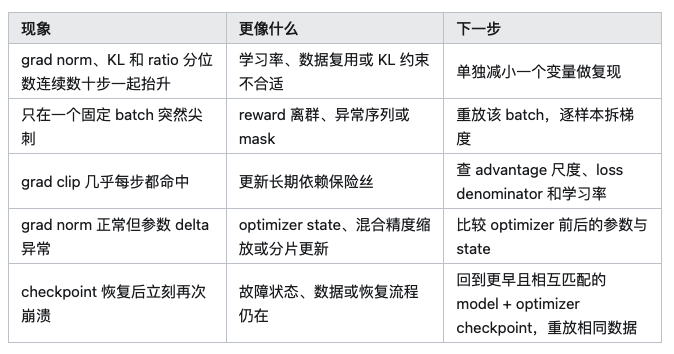

In [34]:
Image(filename='./Image/shape.png')

通常可以把 grad clip 作为最后一道保护，但它不是算法成立的必要条件，也不能保证更新方向正确。如果每一步都靠 grad clip 才不爆，说明根因还没有解决。

### 回滚时把故障证据一起留下
更稳妥的回滚流程是：

1. 保存触发故障的 batch IDs、rollout、reward 和随机种子；
2. 保存崩溃前 checkpoint 与 optimizer state；
3. 从更早 checkpoint 重放同一 batch；
4. 修改一个变量，再次重放比较。

临时 skip 一个 batch 可以让训练继续，但不能作为长期修复。若总是跳过梯度最大的 batch，训练数据会被系统性地重新加权；分布式训练中，各 rank 还必须对 skip 决策保持一致。

### 第 5 步：沿 reward 到 advantage 的路径检查
不要只看 reward 总分曲线。对第一个异常 batch，按样本打印：

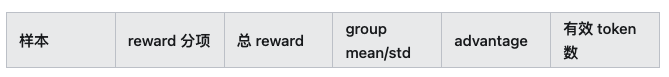

In [35]:
Image(filename='./Image/list.png')

重点检查：

- NaN、Inf、解析失败和 verifier timeout 如何记分；
- 各 reward 分项的量纲是否一致；
- 是否有单个分项突然改变范围；
- group 内 reward range/std 是否突然异常；
- 截断、格式失败和真正答错是否被混成同一个分数；
- 极高或极低 reward 对应的原始回答是否合理。

如果 advantage 使用组内标准差归一化，那么在缩放系数为正、整组统一缩放且归一化中的 eps 可以忽略时，把整个 group 的 reward 乘一个常数会在标准化中抵消。实际实现通常带有 eps，因此标准差很小时不一定完全抵消；如果乘的是负数，advantage 的方向还会反转。

单个异常 reward 则不会被这种机制自动消掉。它会改变组内 mean，通常也会改变 std，因此整组 advantage 都需要重新计算；如果分数跨过了其他样本，还会改变排序。如果没有除以标准差，reward 量纲变化会更直接地改变梯度尺度。排查时必须先确认代码实际使用的是哪种 advantage，而不能只凭“做了 GRPO”来猜。

### reward hacking 不能只靠一条曲线确诊
总 reward 上涨、正确性不动，值得怀疑，但还不是确诊。训练早期模型可能先学会格式，正确性暂时没有变化。

更可靠的检查组合是：

- 人工阅读 reward 最高和增长最快的样本；
- 分开画 correctness、format、length 等分项；
- 使用独立 verifier 或 held-out 规则复判；
- 看某个分项上涨时，任务准确率是否同步变化；
- 将可疑分项关闭或打乱，做单变量对照。
如果模型只学会触发某个打分规则，而独立正确率和人工判断没有改善，才能更有把握地叫 reward hacking。

## 、把整套排查压缩成一张决策表
拿到一个崩溃 run 时，可以按下面的结果直接分流：

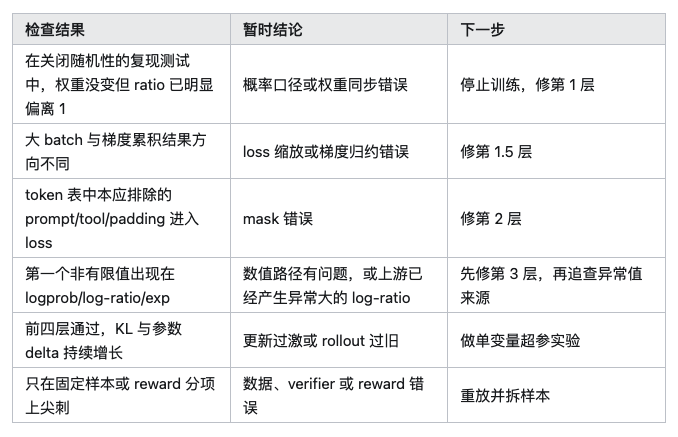

In [36]:
Image(filename='./Image/check_step.png')

这张表不是为了让 debug 看起来整齐，而是为了避免跨层解释。概率计算没通过时，不解释 entropy；mask 没通过时，不解释 reward hacking；数值已经出现 Inf 时，也不靠降低学习率把它暂时压住。

面试里，我会让候选人面对一个“reward 突然归零”的案例，只说最先要看的几项原始数据。如果回答从学习率和 KL 开始，通常说明他习惯读看板；如果先要最后正常 step、第一异常 batch、原始 rollout、ratio 和 mask，才更像真正做过训练排查。

## 总结
训练崩溃的排查可以归结为一句话：
- <font color='red'>先找到第一个错误的张量，再讨论最后一条异常的曲线。</font>

实践顺序是：
- 锁定首个异常 step，验证新旧概率，验证梯度累积，逐 token 检查 mask，沿数值路径寻找第一个 NaN/Inf；
- 这些都通过以后，才调整 optimizer、clip、KL 和 reward。

这样做的价值不是“顺序更优雅”，而是每一层都有明确的通过条件。只有前一层成立，后一层指标才保留原来的解释意义。

### 下一篇单独讲第 1 步：
- 两侧引擎概率不一致的量级到底有多大、怎么诊断，以及 MoE 上为什么这个问题天然更严重。

# 采样引擎和训练框架的概率为什么对不上

本文为系列文章第 7 篇。本系列会分享 GRPO 训练中的排查经验，以及我在面试 post-training 候选人时，会怎样判断对方是否真正理解这些问题。

做 RL 训练时，一个很容易让人困惑的现象是：
- <font color='red'>明明加载的是同一份模型权重，为什么生成答案的推理引擎，和负责训练的框架，算出来的 token 概率却不一样？</font>

GRPO 会比较“**生成这段回答时的概率**”和“**当前模型的概率**”，<font color='red'>两者的比值会参与决定模型怎样更新</font>。
- <font color='red'>如果这两个概率只是因为计算系统不同而对不上，训练算法可能会把系统误差当成模型真的发生了变化。</font>

下面先把整个过程讲清楚，再讨论怎样判断这种差异是否危险。

## 一、先理解：为什么一次训练里会出现两份概率
现在的 RL 训练通常由两套系统配合完成。

- 第一套是 **推理引擎**，例如 vLLM 或 SGLang。它的任务是**尽快生成回答**，这一步也叫 rollout。<font color='red'>它采用了许多专门为生成提速的计算方式</font>。

- 第二套是 **训练框架**，例如 FSDP 或 Megatron。<font color='red'>它拿到生成好的回答后，重新计算每个 token 的概率和梯度，再更新模型参数</font>。这里可以先把梯度理解为一组信号：它告诉模型参数应该往哪个方向调、调多少。

所以，同一条回答至少会经过两次计算：
1. 推理引擎生成 token 时，算过一次它的概率；
2. 训练框架学习这条回答时，<font color='red'>又算一次同一个 token 的概率</font>。

这里说的 token，可以暂时理解为模型处理文字时切出的一个小片段。
- token 概率就是：<font color='red'>在已经看到前文的情况下，模型认为“下一个片段恰好是它”的可能性</font>

例如，模型已经看到“法国的首都是”，接下来生成了“巴黎”。
- 推理引擎可能认为“巴黎”的概率是 10%，
- 训练框架重算后却得到 11%。
- 两边只差 1 个百分点，看起来不大，**但训练真正使用的是两者的概率比值**，也常简称为 ratio：

$\frac{11%}{10%} = 1.1$
- 这个 1.1 的含义本来应该是：当前模型比生成回答时的旧模型，更愿意输出“巴黎”了。

<font color='red'>但如果模型权重根本没有更新，10% 和 11% 只是两套系统算得不一样，那么这个 1.1 就是假的变化。</font>算法却不知道这一点，仍可能据此改变梯度。

### logprob 是什么
<font color='red'>工程里一般不直接保存概率，而是保存 logprob</font>，也就是概率取对数后的结果。

这样做主要是为了计算稳定，也方便把概率的乘法变成加法。理解本文时，只需要记住两点：
- 两个 logprob 相减，<font color='red'>表示两边对同一个 token 的判断相差多少</font>
- 再对这个差取指数，就能还原成训练中使用的概率比值

把训练框架和推理引擎的 logprob 之差记作：

$d_t = logπ_{train}(y_t|x,y_{<t}) - logπ_{rollout(y_t |x,y_{<t})}$
- 公式里的 x是问题，
- $y_{<t}$是第 t个 token 之前已经出现的回答，
- $y_t$ 是现在正在比较的 token。
- $π_{train}$ 和 $π_{rollout}$分别表示训练框架与推理引擎给它的概率。

所以，这个公式只是把一句话写短了：
- 对回答里的第t 个 token，<font color='red'>用训练框架算一次 logprob，再减去推理引擎当时记录的 logprob</font>

如果两边完全一致，$d_t = 0$。训练使用的概率比值就是：
$r_t = e^{d_t} = e^0 = 1$

这里的 $e^{d_t}$不需要手算，<font color='red'>它做的事就是把“logprob 的差”转换回“概率的倍数”</font>
- 如果 $d_t$ = 0.1，那么 。$r_t = e^{0.1} ≈ 1.105$
- 训练算法会把它理解为：当前模型输出这个 token 的概率，大约提高了 10.5%。

后面的排查，本质上都在回答一件事：<font color='red'>这个变化到底来自模型更新，还是来自两套系统本身的差异？</font>

## 同一份权重，为什么还会算出不同结果
“权重相同”只代表模型参数相同，<font color='red'>不代表两边收到的输入、采用的采样规则和具体计算过程都相同。</font>常见原因可以分成四类。

### <font color='blue'>两边看到的内容其实不同</font>
这是最先应该排查的，因为它不是正常误差，而是在比较两个不同的问题。

例如一边的输入是：

- <user>法国的首都是哪里？</user>\<assistant>
- 另一边可能多了一个换行、少了一个特殊 token，或者把 prompt 和回答的分界位置错开了一位。
  - <font color='red'>人眼看起来差不多，但模型看到的 token 序列已经不同，后面的概率自然没有可比性。</font>

需要逐项核对。下面这些名字看起来很多，实际都在确认一件事：两边送进模型的数字是否逐项相同。

- chat template 和特殊 token 是否相同，也就是<font color='red'>包在用户问题前后的对话格式是否相同</font>
- token IDs 是否逐个一致；
- prompt 与 completion 从哪里切开，也就是<font color='red'>问题在哪结束、回答从哪开始</font>
- position IDs、attention mask 和 padding 是否一致，也就是模型看到的文字位置、有效区域和补齐区域是否相同；
- EOS 是否保留，也就是表示“回答到此结束”的 token 是否还在；
- 多轮对话或工具调用时，两边拿到的完整上下文是否相同。

这一类问题没有“误差小就可以接受”的说法。输入不同，就应先修正输入，再谈数值误差。

### <font color='blue'>两边说的可能不是同一种“概率”</font>
模型先输出一组原始分数，随后采样程序还可能对这些分数做处理。例如：

- temperature 会把概率分布调得更平或更尖
- <font color='blue'>top-k</font> 只保留得分最高的若干候选
- <font color='blue'>top-p</font> 只保留累计概率达到某个阈值的候选
- 重复惩罚会降低已经出现过的 token 的得分

因此，至少有两种概率：
1. 模型原始输出的概率；
2. <font color='blue'>经过 temperature、top-p 等规则处理后，采样程序真正使用的概率</font>。

第二种也常被称为 <font color='red'>行为分布</font>。这个名字听起来抽象，实际含义很简单：<font color='blue'>当时究竟按照哪套概率抽出了这个 token</font>

**有的推理接口返回原始概率，有的返回处理后的概率，还有的会随配置变化**。如果推理侧保存的是处理后概率，训练侧重算的却是原始概率，两边即使使用同一份权重，也不应该相等。

<font color='blue'>所以看到差异时，不要先问“浮点误差有多大”，而要先确认两侧比较的是不是同一种概率</font>

### 公式相同，计算顺序也可能不同
神经网络里有大量浮点数加法和乘法。**浮点数精度有限，先加哪一部分、后加哪一部分，最后几位可能略有不同。**

一个简单的类比是：<font color='red'>如果每一步都只保留两位小数，那么“先把小数分别相加再四舍五入”和“先分组四舍五入再相加”，结果可能差一点。</font>

推理引擎和训练框架为了各自的速度，会采用不同的底层计算程序，这些程序通常叫 kernel（算子）。同一条样本和多少条其他样本一起计算，也会改变分组与求和顺序，这就是 batch 组织带来的影响。

<font color='red'>这类差异通常很小，而且连续变化。换一个 batch 大小后，数值可能稍有改变，但不应该突然差很多。</font>

### 两边实际上没有使用同一个版本的权重
RL 训练一边更新模型，一边不断生成新回答。<font color='red'>如果权重同步慢了一步，推理引擎可能还在使用旧版本，训练框架已经更新到了新版本。</font>

下面这些环节都可能造成版本错位：

- 异步 rollout 的队列里**仍有旧任务**；
- LoRA 等增量权重没有正确合并或加载；
- 模型参数分散在多张卡上，但**只同步了一部分**；
- 本应由输入和输出共同使用的共享参数，**只更新了一处**；
- 推理侧为了加速保存了一份低精度模型，但这份副本没有及时刷新。
因此，每批 rollout 最好记录生成时使用的 policy version。日志里只写“同步成功”还不够，还要确认真正参与生成的每个 worker 都已经切换到了那个版本。

到这里可以把原因分成两类：
- 必须修的对齐错误：输入不同、概率口径不同、权重版本不同；
- 可能无法完全消除的数值差异：<font color='red'>两套系统的算子、精度和计算顺序不同</font>。

排查的目标不是强求所有结果逐 bit 相等，而是先排除第一类错误，再判断第二类差异是否已经大到会影响训练。



## <font color='red'>这些差异会怎样影响 GRPO</font>
理解影响之前，要<font color='red'>先看代码究竟怎样使用概率比值</font>。
- GRPO 通常还会给 ratio 加一道 clip：如果概率变化太大，就把它限制在一个范围内，避免单次更新走得太远。下面最容易出现一个错误推导。

### <font color='blue'>不能把“每个 token 的平均误差”直接乘以回答长度</font>
一种常见说法是：

每个 token 的 logprob 平均差 0.001，回答有 2000 个 token，所以总差异是 2，概率比值就会变成 $e^2 ≈7.4$。

<font color='red'>这对标准 GRPO 并不成立</font>

标准 GRPO 是逐 token 计算概率比值的。第 t 个 token 的比值是：
$r_t = e^{d_t}$

如果这个 token 的 $d_t$ = 0.001，那么它自己的比值是：
- $e^{0.001} ≈ 1.001$
无论回答有 20 个 token 还是 2000 个 token，**这一个 token 的比值仍然是 1.001，不会自动变成 7.4**。
- <font color='red'>回答变长，只是训练目标（loss）里需要处理的 token 变多了</font>

长回答仍然可能更容易遇到异常 token，但原因是“检查的位置更多”，不是“单个 token 的 ratio 被长度乘大了”

### <font color='red'>如果代码使用序列级 ratio，要看它是否除以长度</font>
有些算法不是逐 token 做 clipping，而是先把整条回答合成一个 ratio。**此时必须看具体公式，不能只听到“序列级”三个字就认为误差会直接累加。**

例如 GSPO 是一种改为<font color='red'>从整条回答衡量变化的方法</font>。它使用长度归一化后的序列 ratio：


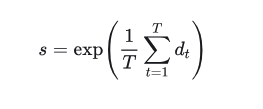

In [51]:
Image(filename='./Image/gspo_01.png')

可以分两步理解：

1. <font color='red'>先把整条回答中每个 token 的 logprob 差加起来</font>
2. 再除以 token 数量 T，<font color='blue'>得到每个 token 的平均差</font>，最后取指数。
如果所有 token 的 $d_t$都是 0.001，那么不管回答多长，括号里的平均值仍是 0.001，所以 s ≈ 1.001。

只有代码真的使用下面这种没有除以长度的完整序列 ratio：<font color='red'>误差才会直接随着 token 数量累加</font>

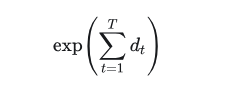

In [52]:
Image(filename='./Image/gspo_02.png')


所以讨论长度影响之前，先确认实现属于哪一种：
- 逐 token ratio
- 除以长度的序列 ratio
- 还是没有除以长度的完整序列 ratio

### 真正值得警惕的是三种情况

#### 第一种是少数 token 差得特别大。

假设 999 个 token 的差异都只有 0.001，但有 1 个 token 的差异是 0.5。全局平均值看起来可能仍不显眼，可那个异常 token 的 ratio 已经是 $e^{0.5} ≈ 1.65$，很可能撞到 clip 边界，并明显改变这一项的梯度。

#### 第二种是差异长期朝同一个方向偏。

<font color='red'>如果训练框架算出的 logprob 总是比推理引擎高一点，ratio 就会整体偏大</font>。算法会把这种固定偏差当成模型持续提高了这些 token 的概率。即使每个位置的偏差都不大，训练样本的权重也会被系统性改变。

#### 第三种是差异恰好<font color='red'>和某类样本相关</font>。

例如:
- 长回答的偏差更大，
- EOS 附近的偏差更大，
- 高 advantage 的样本偏差更大。
  - 这里的 advantage 表示一条回答相对同组其他回答“好出多少”或“差出多少”。一旦误差和它有关，就不会像普通噪声那样互相抵消，而会有选择地放大某些样本。

### <font color='red'>几个统计量分别在回答什么</font>
不要只看一个平均数。下面几个指标用途不同：

- mean Δlogp：
  - 带正负号的平均值，**用来看两边是否长期朝一个方向偏**；
- mean |Δlogp|：
  - 先取绝对值再平均，用来看一个普通 token 平均差多远；
- P99 |Δlogp|：
  - 把误差从小到大排列后，第 99% 位置的值，<font color='red'>用来看最差的那一小部分 token</font>
- max |Δlogp|：
  - **最大的单点误差，适合找到具体坏样本**，但不适合单独决定整次训练是否健康
  
例如，
- 一百万个 token 中只有一个位置异常，max 会非常大，但训练未必已经整体失控；
- 反过来，如果 mean Δlogp 长期偏离 0，即使 max 不夸张，也可能存在稳定的系统偏差。

还有一个常见错误：不能把 mean |Δlogp| 当成标准差，再直接代入“随机误差随长度按 $\sqrt{T}$
 增长”的公式。
 - 平均绝对值、标准差和带符号均值是三种不同的量，而且相邻 token 的误差通常也不是完全独立的。



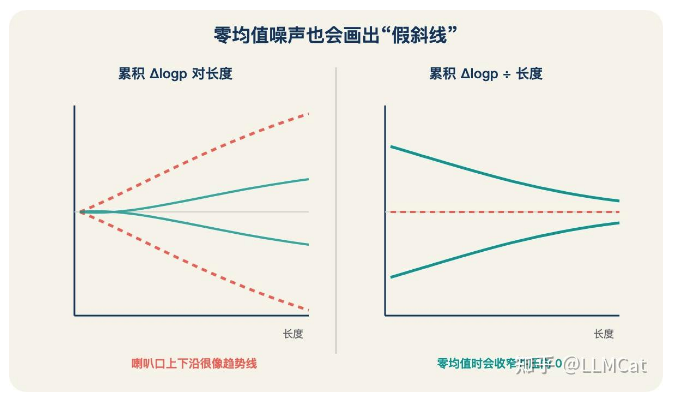

In [54]:
Image(filename='./Image/zero.png')

## <font color='red'>怎样一步步查清楚差异来自哪里</font>
不要一上来同时改 temperature、batch size、推理精度和权重同步。**那样即使差异消失了，也不知道是哪一项起了作用。** <font color='blue'>更有效的做法是先固定条件，再做三路对照</font>。

### 先把测试条件固定住
<font color='red'>选择一批已经生成好的完整 token 序列</font>，不再重新采样。然后：

- 冻结模型权重；
- 关闭 dropout，也就是训练时随机丢弃部分中间结果的机制；
- <font color='red'>保证输入 token、mask 和 position IDs 完全相同</font>
- 固定那些会影响随机计算的状态；
- **记录模型版本**、精度、batch 形状和采样配置。
这样做的目的，是先把“模型真的变了”和“输入换了”排除掉，只测计算本身。

### 对同一批 token 算三遍
把三次结果分别记为 A、B、C：

- A：**训练框架**第一次计算的 logprob
- B：**训练框架**在相同条件下再算一次
- C：**推理引擎**对同一批 token 计算的 logprob

然后分开比较：

#### 先看 A 和 B。

它们都来自**训练框架**。
- <font color='red'>如果 A、B 已经明显不同，说明训练侧自己都无法稳定复现</font>。
- 此时还不能把问题归因于“两套引擎不一致”，应先检查随机性、batch 组织，以及“**同样输入重复运行也可能略有不同”的底层计算**。
 

#### 再看 A 和 C。

如果 A、B 很接近，A、C 却明显更远，问题才真正指向跨引擎差异：<font color='red'>推理精度、量化、采样后的概率口径，或者权重版本没有对齐</font>

最后改变 batch 组织，再重复 A、B。

如果只改 batch 大小就会让训练框架自己的结果轻微变化，这一部分可以视为当前硬件和配置下的计算底噪。
- <font color='red'>以后判断 A、C 是否异常，就应该和这条底噪基线比较，而不是要求绝对为 0</font>。

### old logprob 到底从哪里来
GRPO 中的 old logprob，指的是生成这批回答时，旧策略给每个 token 的 logprob。

<font color='red'>工程上通常有三种取法，它们看起来相似，实际回答的是不同问题。</font>

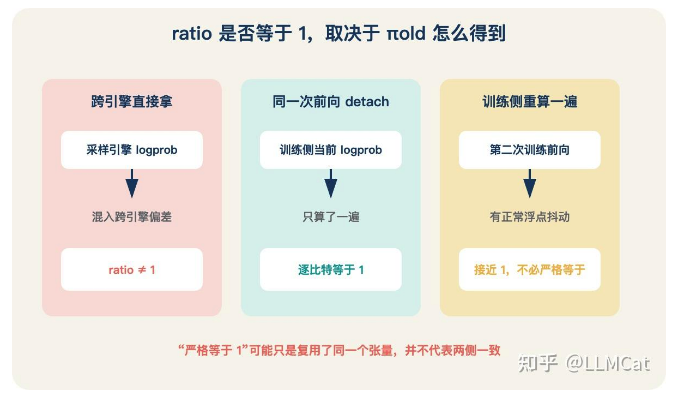

In [55]:
Image(filename='./Image/ratio=1.png')

#### 方法一：直接保存推理引擎生成时返回的 logprob
它最接近“这批 token 当时是按照什么概率生成的”。缺点是:<font color='red'>训练时分子来自训练框架、分母来自推理引擎</font>，跨引擎差异会直接进入 ratio

#### 方法二：在训练框架中算一次，然后把同一个结果当作 old logprob
这种写法常见于把当前 logprob detach 后复用；detach 可以理解为保留这个数值，但不再沿着它计算梯度。因为分子和分母本来就是同一个数，模型未更新时 ratio 一定等于 1。

但这不能证明推理引擎和训练框架一致。它只是绕开了两套系统的比较，所以也测不出跨引擎误差。

#### 方法三：在训练框架里加载旧权重，<font color='red'>重新计算 old logprob</font>
这样分子和分母都由训练框架计算，数值口径更容易一致。但如果推理引擎当时使用了不同的 temperature、top-p 或量化方式，重算结果仍不一定等于真正生成 token 时使用的概率。

因此，看到“模型没更新时 ratio 等不等于 1”这类问题，不能直接回答。<font color='red'>必须先问：old logprob 是推理侧保存的、同一个张量复用的，还是训练侧用旧权重重算的？</font>

### 为什么 clip fraction 为 0 也不能证明没问题
clip fraction 表示有多少 ratio 超出了 PPO/GRPO 允许的范围。

假设上界是 1.2，那么单个 token 需要满足：

$d_t > log1.2 ≈ 0.182$

ratio 才会超过上界。

如果跨引擎误差普遍是 0.01，它还没有大到触发 clip，所以 clip fraction 可能仍是 0。但这只能说明“尚未越线”，不能证明两边完全对齐，也不能排除长期方向性偏差。

另外，有些实现只统计真正改变 loss 的 clipping；
- 当 advantage 为 0 时，即使 ratio 越界，日志也可能不计入。因此排查一致性时，应该直接统计 ratio 本身的分布和越界率，而不是只依赖训练日志中的 clip fraction。

### 不要照搬一个固定阈值
<font color='red'>不同模型、精度、推理引擎、量化方式和 batch 形状，天然底噪都不同。别人实验里的 $10^{-3}$或 $10^{-2}$，不能直接当成所有项目的合格线</font>

更可靠的做法是：

1. 先在确认输入、权重和概率口径都对齐的配置上，测出一条干净基线
2. 固定同一批样本和同一种统计方法
3. 比较故障 run 是否明显偏离这条基线
4. 再看这种偏离是否真的改变了 ratio、clip 或不同样本的梯度权重

## <font color='red'>为什么 MoE 模型更容易出现不一致</font>
前面讲的是所有模型都会遇到的问题。<font color='red'>MoE 模型还多了一步“选择专家”</font>，<font color='blue'>所以对小的数值扰动更加敏感</font>


### 先理解什么是 router
MoE 的一层里不是只有一个前馈网络，而是放了多个“专家”网络。每个 token 到达这一层时，<font color='red'>一个叫 router 的小模块会给专家打分，再挑出得分最高的一个或几个参与计算。</font>

例如，某个 token 对专家 A 和专家 B 的得分分别是：

  - 专家 A：0.5001
  - 专家 B：0.4999
  - 推理引擎选择 A。
  
<font color='red'>训练框架因为浮点计算顺序不同</font>，得到的结果可能变成：
  - 专家 A：0.4999
  - 专家 B：0.5001
  
<font color='blue'>两边的数值只差一点点，最终选择的专家却完全不同。</font>
- 普通的 Dense 模型会让每个 token 经过同一套网络，小误差通常只是让输出小幅变化；
- MoE 的 top-k 选择则像一道开关，<font color='red'>微小误差也可能改变后续计算路径</font>。

### 专家不同，不等于最终概率一定差很多
发现两边选了不同专家，**只能说明计算路径不同，不能直接推出最终 logprob 已经严重失真**。

有时两个专家输出很接近，或者被替换掉的专家权重很小，最后的 token 概率仍可能差不多。因此至少要同时看两层结果：
  - 路由层面：每个 token、<font color='blue'>每一层选出的 top-k 专家是否相同</font>；
  - 最终结果：**这些路由差异有没有真的造成较大的“实际生成 token 的 logprob”差异**。
  
如果只报“有多少层 routing 不同”，却不看最终概率，就无法判断它是否已经影响训练。

### routing replay 到底是什么
假设采样时，某个 token 在第 10 层选择了专家 A 和 C。训练时重新前向，router 却选择了 A 和 D。

一种减少这种差异的办法是：<font color='blue'>采样时把“每层选了哪些专家”一起保存下来</font>；
- 训练时不让 router 重新选择，而是让这个 token 仍然走 A 和 C。

这就是 routing replay：把之前走过的专家路线记录下来，之后再原样重放。

这个词在不同系统里可能指两种做法：

1. **保存**推理引擎采样时的路线，在训练框架中重放，用来减少两套引擎的差异；
2. **保存**训练框架中旧策略的路线，在同一批数据的多次更新中重放，用来减少更新前后的路由变化。
两者解决的问题不同，不能只写“开启 routing replay”而不说明重放的是哪一条路线。

routing replay 也不是没有代价。它会增加需要保存和传输的数据，而且训练时强制沿用旧路线，等于暂时不让 router 根据当前状态自由选择。因此，只有确认“因为路由不同确实进一步造成了明显的 logprob 和梯度问题”时，才值得考虑使用；不能因为两边的专家选择没有逐项一致，就默认一定要重放。

## 一套可以直接执行的排查顺序
如果训练中发现两侧 logprob 对不上，可以按下面的顺序查：

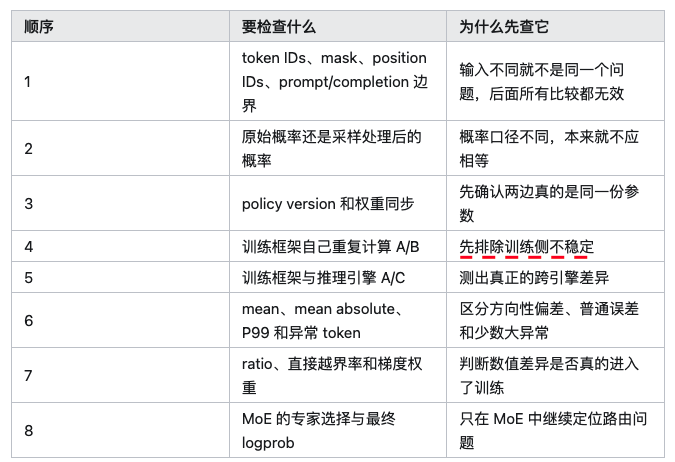

In [58]:
Image(filename='./Image/order.png')

几种常见结果也可以这样解释：

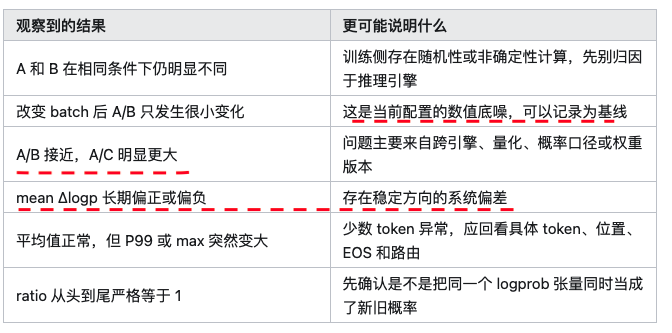

In [59]:
Image(filename='./Image/explain.png')

## <font color='red'>面试里我会怎样判断候选人是否真的理解</font>
我不会满足于“vLLM 和训练框架有数值误差”这一句话，因为知道这个现象并不等于会排查。

我通常会继续问：

- 两边比较的是同一串 token、同一种概率吗？
- old logprob 到底来自推理引擎，还是训练框架重算？
- 模型没更新但 ratio 不等于 1，你会先做哪组对照？
- 为什么不能把 mean |Δlogp| 直接乘以回答长度？
- 平均误差很小，为什么训练仍可能受影响？
- MoE 里专家选择不同，怎样证明它真的影响了最终概率？
- routing replay 保存并重放的究竟是哪一次路由？它又会带来什么代价？

好的回答不一定要背出某个固定阈值，但应该能把输入、权重、概率口径、计算底噪和训练影响一层层拆开，而不是一看到差异就笼统归因于“浮点误差”。

## 总结
一次 GRPO 训练中，**推理引擎负责生成**，$\log \pi_{\text{train}}$**训练框架负责学习**，所以同一个 token 会被两套系统分别计算概率。训练算法本来想用这两个概率的比值衡量“模型更新了多少”，但跨引擎差异也可能混进这个比值。

排查时先确认三件事：
- 两边是不是同一串 token、同一种概率、同一个权重版本。排除这些硬错误后，
- 再用 A/B/C 对照测出训练侧底噪和跨引擎差异，并分别观察方向性偏差、普通误差和少数极端 token。

回答长度不会自动把标准 GRPO 中的单个 token ratio 乘大。<font color='red'>真正危险的是少数位置差得很大、误差长期朝同一方向偏，或者误差和特定样本、位置及 advantage 相关</font>

对于 MoE，还要区分“专家路线不同”和“最终 token 概率真的差很多”。routing replay 只是把之前的专家选择记录下来并重放，只有当路由差异确实传导成训练问题时，才值得承担它的实现成本和约束。



# KL 估计量怎么选，放 loss 还是 reward

这篇讨论两个经常被混在一起的问题：

1. k1、k2、k3 <font color='red'>哪个更适合用来估计或优化 KL？</font>
2. <font color='blue'>KL 应该作为 reward 的一部分，还是直接放进 loss？</font>

后面再补一个训练中很常见的误区：<font color='red'>明明开了 grad clip，为什么梯度尖刺仍然可能污染 Adam？</font>

这几个问题难懂，不是因为公式特别复杂，而是<font color='red'>大家经常把“看板上的数值”“反向传播的梯度”和“训练噪声”当成同一件事。</font>下面先把它们拆开。

## 先明确：我们到底在估计哪个 KL



In [1]:
from IPython.display import Image

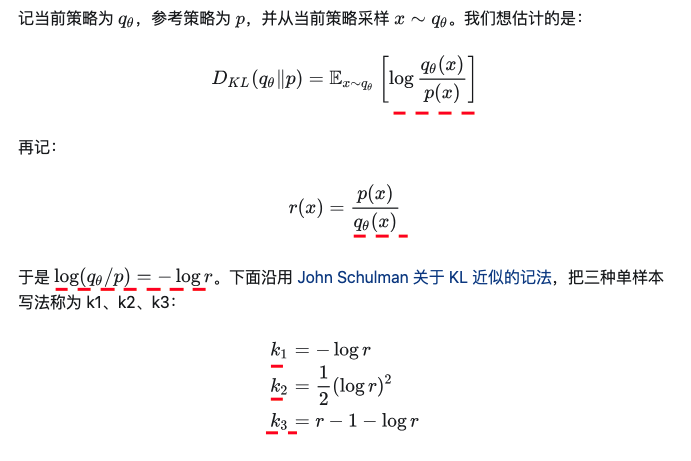

In [19]:
Image(filename='./Image/kl(123).png')

### 先只看“读数”
暂时不要对它们求梯度，只把它们当作 Monte Carlo 估计量：


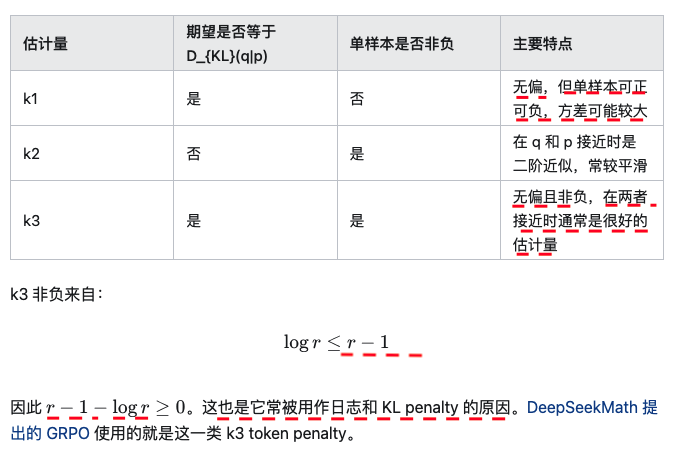

In [21]:
Image(filename='./Image/carlo.png')

但“在策略接近时方差低”不能简写成“永远不会出问题”。
- 当 $q_\theta(x)$很小、而参考策略 p(x)仍给这个 token 较大概率时，$r = p/q_\theta$会很大，
  - k3 中的 r项也会快速增长。
  - k2 没有这个线性的 r 项，只按 log-ratio 的平方增长，因此在某些大偏移场景里更温和；但它仍然没有上界，也不能说成“永远不会爆”。<font color='red'>同时，它对真实 KL 是有偏的，策略离参考模型越远，二阶近似越需要重新验证。</font>

#### k1、k2、k3 三种 KL 估计量在 期望值、期望梯度和主要风险上的对照:

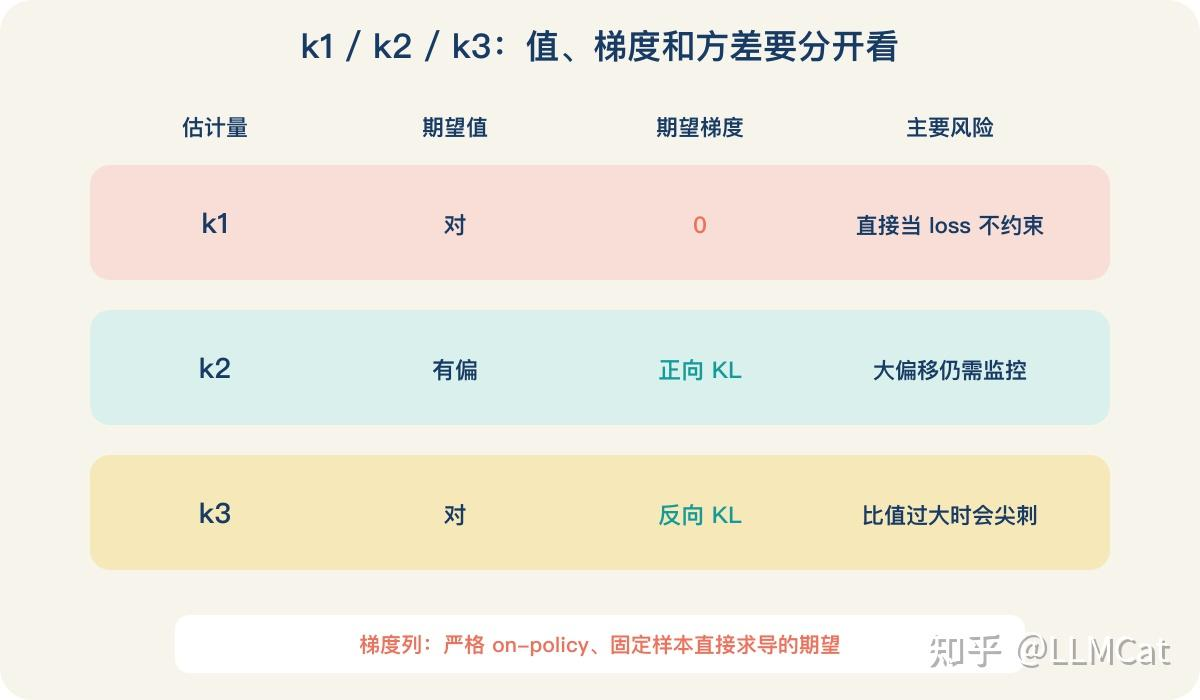

In [5]:
Image(filename='./Image/com_kl.jpg')

### 再看“把它直接放进 loss 后的梯度”

这里多了一个容易忽略的条件：训练代码通常把已经采到的 token 当作固定样本，只对估计量本身做自动求导。自动求导不会替你补上<font color='red'>“采样分布 $q_\theta 也随参数变化”</font>这一项。

在严格 on-policy、$x \~ q_\theta$ 的条件下，三者直接作为 loss 时的期望梯度是：

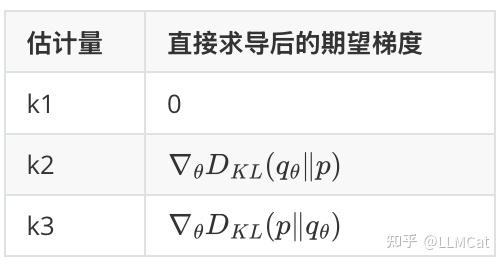

In [9]:
Image(filename='./Image/kl_nabla.jpg')

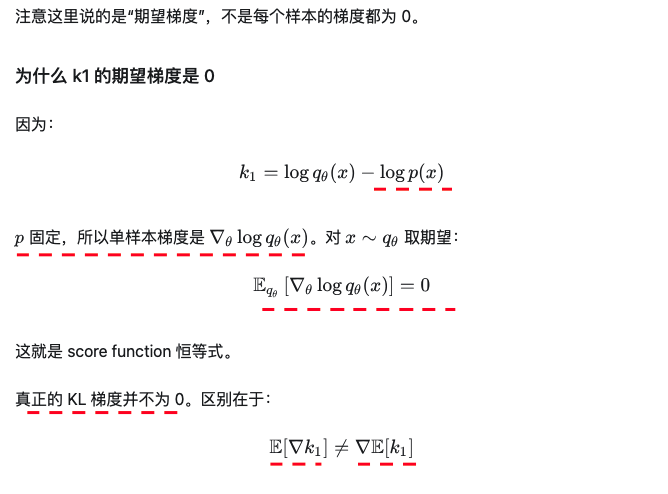

In [22]:
Image(filename='./Image/kl_nabla_1.png')

<font color='red'>右边还包含采样分布随 $\theta $变化带来的项，而“固定采样结果再自动求导”没有这条路径。因此 k1 可以是一个无偏的 KL 读数，却不是一个可以直接拿来优化同一 KL 的 loss。</font>

如果样本来自旧策略、temperature 处理后的分布或 top-p 截断分布，上面的零期望结论也不再成立。此时梯度会依赖实际行为分布，不能继续套用 on-policy 表格。

#### <font color='red'>为什么 k2 对应前向 KL 的梯度</font>

对 k2 求导：

$\nabla_\theta k_2 = \log \frac{q_\theta(x)}{p(x)} \nabla_\theta \log q_\theta(x)$

取 $q_\theta$下的期望，正好得到 $D_{KL}(q_\theta || p)$的梯度。这里“读数有偏”和“期望梯度对”可以同时成立，因为它们本来就是两个问题。

#### <font color='red'>为什么 k3 对应另一方向的 KL</font>



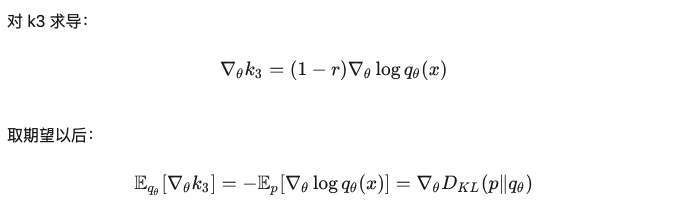

In [11]:
Image(filename='./Image/kl_3.png')

<font color='blue'>它优化的是 $D_{KL}( p || q_\theta )$，而不是前面的 $D_{KL}(q_\theta || p)$。</font>

<font color='red'>这不一定是坏事</font>。$D_{KL}( p || q_\theta )$会强烈惩罚“参考策略仍有概率、当前策略却已经压得很低”的区域，因此在防止遗漏参考策略覆盖的模式时可能更有力。但不能把它写成普遍更好的抗坍塌正则：softmax 下概率通常不会真的变成 0，而且效果还取决于参数化、采样覆盖和 KL 系数。

### 一张表该怎么读
k1、k2、k3 没有脱离用途的统一排名：

- 只想监控 $D_{KL}(q || p)$的平均值：k1、k3 都是无偏估计，k3 单样本非负；
- <font color='blue'>想把样本估计量直接放进 loss：</font><font color='red'>必须看它实际产生哪个期望梯度；</font>
- 策略已经离参考模型很远：<font color='blue'>要额外看高分位数和非有限值</font>，不能只比较均值、方差；
- 数据来自旧策略或经过采样变换：上述 on-policy 梯度结论需要重新推导。

## <font color='blue'>KL 放在 reward 里，和放在 loss 里有什么区别</font>

先把两条路径画清楚。

### 核心背景：为什么要引入 KL 散度？
在基于人类反馈的强化学习（RLHF）或 PPO 微调大模型时，我们有两个核心目标：
  - 目标一：让模型“变好”。利用奖励模型（Reward Model）给模型打分，让模型生成符合人类偏好的内容。
  - 目标二：防止模型“跑偏”。为了防止模型为了盲目追求高分而生成乱码、复读机模式（奖励黑客行为，Reward Hacking），或者遗忘原本的语言逻辑，我们需要约束它。
  
<font color='red'>KL 散度（ $L_KL$）就是用来实现“目标二”的。</font> 它衡量的是“当前正在训练的策略模型（ π ）”与“初始的监督微调模型（SFT，作为参考策略 $π_ref$）”之间的差异。差异越大，惩罚越重。

###  loss-KL：token 在哪里偏，就在哪里产生梯度
常见写法是在 policy objective 旁边直接加：

$L = L_{policy} + \beta L_{KL}$

  - $L_policy$（策略损失）：这是强化学习的主任务，指导模型如何根据奖励信号去优化策略（让生成的回答得分更高）。
  - $L_KL$（KL 损失）：这是一个正则化项（惩罚项）。它时刻提醒模型：“在追求高分的同时，不要偏离你原本的 SFT 参考策略太远”。
  - β （控制系数）：这是一个超参数，用来权衡两者的比例。 β 越大，对模型的约束越强，模型越保守； β 越小，模型探索新策略的自由度越大。


KL 项可以按 token 计算并直接反向传播。<font color='blue'>它的效果取决于采用哪种估计量、是否 stop-gradient，以及最后按 token 还是 sequence 归约。</font>

好处是信用分配比较直接：<font color='red'>哪个 token 偏离参考策略，哪个位置就产生相应梯度</font>。
  - 代价是实现细节会决定实际优化的是哪个方向的 KL，前一节的梯度表不能跳过。
  - 精细化惩罚：这种实现方式不是等到整句话或整段文本生成完后才计算一个总的 KL 惩罚，而是在生成过程中的每一步（每一个 Token）都计算当前的概率分布与参考模型概率分布的 KL 散度。
  - 反向传播（Backpropagation）：计算出的 KL 损失会通过反向传播，将梯度精确地传导回当前生成这个 Token 时的网络权重。
  
#### 为什么这样做？（好处：直接的信用分配）

在强化学习中，有一个经典难题叫“信用分配（Credit Assignment）”，即当最终得到一个奖励或惩罚时，<font color='red'>很难确定到底应该归咎于（或归功于）前面生成的哪一个 Token。</font>
  - 通过逐 Token 计算 KL 并反向传播，优化目标变得非常直接：
    - 如果某个 Token 的输出概率严重偏离了参考模型，那么网络在生成这个 Token 时的参数就会立刻受到惩罚（梯度调整），从而被拉回到安全、合理的分布范围内。 这极大地保证了生成文本的流畅性和合理性。
  
  
#### 实现细节与代价
图片提到，KL 项的具体效果取决于以下几个工程上的选择：
  - 估计量与 stop-gradient（截断梯度）：
    - 在计算 KL 散度 $log \frac{\pi(y)}{\pi_ref(y)}$ ，通常会将参考模型($π_ref$即 SFT 模型）冻结（不更新）。在代码实现中，往往会使用 stop-gradient（截断梯度）操作在参考模型的 log 概率上，确保反向传播的梯度只用来更新当前策略模型，而不去更新参考模型。
  - 归约方式（Reduction）：
    - 计算完每个 Token 的 KL 后，<font color='red'>是按整个序列（sequence）求平均，还是保留每个 Token 的独立梯度？</font> <font color='blue'>通常会在序列维度上求平均（mean），但梯度是作用在具体生成位置上的。</font>
  - 代价（不能跳过的梯度表）：
    - 虽然逐 Token 产生梯度的好处是直接，但它也有代价。<font color='red'>因为每个 Token 都在参与反向传播，这会导致训练时的中间变量（如每个时间步的 log 概率）都需要保存在显存中</font>。如果序列很长，这会显著增加显存占用和计算量。此外，这也意味着在代码实现时，必须精心设计前向传播和反向传播的梯度流（即前文中提到的梯度表不能跳过），否则无法正确实现这种精细化的约束。
    
#### 在 PyTorch 中，实现 stop-gradient 有两种最常见的标准写法：
##### 写法 1：使用 .detach() 方法（最常用、最推荐）
.detach() 会创建一个新的张量，其数值与原张量相同，<font color='red'>但完全切断了与原张量的计算图（Computation Graph）的联系</font>。    

In [ ]:
import torch
import torch.nn.functional as F

# 假设我们有一个batch的log_probs(对数概率)，形状[batch_size,seq_len,vocab_size]

# 1.当前策略模型输出的log_probs(需要更新)
log_pi = current_actor_model(input_ids).logits # 假设logits已经过log_softmax
# 提取当前token的log_prob
token_idx = torch.arange(batch_size)
current_log_prob = log_pi[token_idx,:,y_t]

# 2.参考模型输出的log_probs(不需要更新，即stop-gradient)
ref_log_pi = ref_sft_model(input_ids).logits
ref_token_log_prob = ref_log_pi[token_idx,:,y_t]

# --- 核心操作：对参考模型的概率进行stop-gradient ---
# ref_token_log_prob.detach()会创建一个与他数值相同，但没有梯度的张量
ref_log_prob_detached = ref_token_log_prob.detach()

# 3.计算逐token的KL损失
kl_loss = current_log_prob - ref_log_prob_detached

# 4.反向传播
# 此时，梯度只会通过current_log_prob 传回current_actor_model
# 而ref_sft_model的参数永远不会被更新
kl_loss.backward()


#### 写法 2：使用 torch.no_grad() 上下文管理器
如果你需要在一段代码块内完全停止梯度计算（比如在生成采样或计算参考模型时），可以使用此上下文管理器。


In [ ]:
import torch

# 使用 torch.no_grad() 包裹参考模型的前向传播和计算
with torch.no_grad():
    # 参考模型的前向传播不会建立计算图
    ref_outputs = ref_sft_model(input_ids)
    ref_log_prob = ref_outputs.logits[token_idx, :, y_t]
    # 此时 ref_log_prob.requires_grad 为 False

# 当前模型的计算
current_log_prob = current_actor_model(input_ids).logits[token_idx, :, y_t]

# 计算 KL
kl_loss = current_log_prob - ref_log_prob

# 反向传播时，梯度同样无法流回 ref_sft_model
kl_loss.backward()

###  reward-KL：先改序列分数，<font color='blue'>再经 advantage 回到 token</font>（将 KL 惩罚直接融入到奖励信号（Reward）中）
另一条路径是先构造：

$ R'_i = R_i - \beta K_i $
  - $R_i$（原始奖励）：通常由 Reward Model 给出的分数（比如模型回答了正确的问题，给一个正分）。
  - $K_i$（序列级 KL 惩罚）：<font color='blue'>第 i 条回答（Sequence）经过聚合计算后得到的整体 KL 散度值。</font>
  - $R_i′$（修正后的净奖励）：这是真正进入后续 RL 计算流程的奖励。
  - β （惩罚系数）：控制 KL 惩罚的严厉程度。

通俗理解：
假设模型生成了第 i 句话，Reward Model 给了 8 分（ $R_i$=8 ）。但是这句话偏离 SFT 参考模型太多了，算下来 KL 惩罚是 3 分（ $βK_i$=3 ）。那么，真正用来训练这条句子的奖励就变成了 8−3=5 分（ $R_i′$=5 ）

 
其中 $K_i$是第 i 条回答聚合后的 KL penalty。按照通常的 reward 路径，$ R'_i $在进入 advantage 前会被视为不参与自动求导的标量。然后用它计算组内 advantage，再把同一个 outcome advantage 分配给该回答的 token。

这条路径更像普通 RL 信号，但它会经过：

  - token KL 如何聚合成序列分数；
  - 组内减均值；
  - 是否除以组内标准差；
  - PPO ratio 和 clip；
  - token/sequence loss denominator。
  
因此“KL 在 reward 里”不是一个完整实现描述。只要上述任一步不同，KL 的有效强度和方差都会不同。


#### 信号是如何传递的？（Advantage 回传）
<font color='red'>计算出 $R_i′$之后，整个流程就走上了“普通 RL（强化学习）信号处理”的轨道。</font>

在 PPO 等 Actor-Critic 算法中，单个 Token（词）是没有直接奖励的。<font color='red'>奖励是针对整段话（序列）的</font>。那么，**怎么把整段话的净奖励 $R_i′$传导回每一个 Token 呢？**

<font color='red'>这里用到了 Advantage（优势函数）：</font>
  - 序列级计算：<font color='red'>利用修正后的奖励 $R_i′$，计算出整段话的组内优势值（Intra-group Advantage）。</font>
  - Outcome Advantage（结果优势分配）：计算出整段话的优势后，将这个单一的优势值（Outcome） 平等地分配（Broadcast）给生成这段话语的每一个 Token。

##### 总结这条路径：
Token 聚合 KL -> 算出序列级惩罚 -> 扣减奖励得到 R' -> 计算序列级 Advantage -> <font color='red'>把 Advantage 复制给序列里的每个 Token</font> -> 用带 Advantage 的 Loss 去优化模型。

#### 为什么说这条路径极其复杂？（工程细节的黑箱）
图片中列举了一长串的“中间步骤”，这是理解 reward-KL 最困难、也是实际工程中最容易踩坑的地方。

<font color='red'>因为 $R_i′$被当作一个“普通奖励”送入了 RL 框架，它就会像普通的奖励信号一样，被迫经历一系列标准化的 RL 预处理和后处理步骤。</font>
  - 这导致 KL 惩罚的有效强度变得极其不可控。

具体经过的步骤包括：
1. Token KL 如何聚合成序列分数：
   - 是把每个 Token 的 KL <font color='red'>直接相加（sum），还是取平均（mean）？</font>这直接影响$K_i$的量级。
2. 组内减均值（Baseline 减法）：
   - 为了减少方差，PPO 通常会减去该组内的奖励均值。<font color='red'>这会导致 $R_i′$的绝对大小被改变。</font>
3. <font color='red'>是否除以组内标准差：</font>
   - 有些框架会对优势值做标准化（除以标准差）。这会将原本固定的 β 惩罚系数的实际效果放大或缩小。
4. PPO ratio 和 clip：
   - PPO 算法在更新策略时会计算新旧概率的比值（ratio），并进行裁剪（clip）。如果 KL 惩罚太大，导致 ratio 超出裁剪范围，KL 惩罚带来的梯度可能会直接被 Clip 掉，导致失效。
5. Token/sequence loss denominator：
   - 计算最终的 Policy Loss 时，分母是 token 数量还是 sequence 数量，也会改变最终梯度的大小。

In [24]:
import  numpy as np
import torch

def demo_reward_kl_process():
    """
    演示reward-kl路径：先守正奖励R`，再计算组内Advantage并回传
    """
    # ==========================================
    # 1. 模拟构造：R'_i = R_i - βK_i
    # ==========================================
    # 假设我们有 4 条样本（一个完整的 batch/group）
    
    R_raw = np.array([10.0, 2.0, 8.0, 1.0]) # reward model给出的原始奖励
    K_seq = np.array([2.0, 5.0, 1.0, 10.0])  # 每条序列聚合后的 KL 惩罚（由 token KL 聚合而来）
    beta = 0.1 # KL惩罚系数
    
    # 核心公式：先修改序列分数
    R_prime = R_raw - beta * K_seq
    print("--- 1. 奖励修正阶段 (Reward Modification) ---")
    print(f"原始奖励 (R):          {R_raw}")
    print(f"KL 惩罚 (beta * K):    {beta * K_seq}")
    print(f"修正后的奖励 (R'):     {R_prime}")
    print("说明: R' 此时是一个标量 (Scalar)，不参与自动求导，被视为 RL 的 ground truth。")
    print("-" * 50 + "\n")
    
    # ==========================================
    # 2. 组内计算 Advantage (含减均值、除以标准差)
    # ==========================================
    # 为了降低方差，通常会对组内的 R' 进行标准化处理
    
    advantage = R_prime.copy()
    
    mean_val =  np.mean(advantage)
    std_val = np.std(advantage)
    
    # 组内减去 均值
    advantage = advantage - mean_val
    
    # 是否除以组内标准差（这一步会极大地放大或缩小 β 的实际作用）
    is_normalize = True
    if is_normalize:
        # 防止除以 0
        if std_val > 1e-8: 
            advantage = advantage / std_val
    
    print("--- 2. 组内标准化阶段 (Normalization) ---")
    print(f"组内均值 (Mean):       {mean_val:.4f}")
    print(f"组内标准差 (Std):      {std_val:.4f}")
    print(f"标准化后的 Advantage:  {advantage}")
    print("说明: 经过标准化，原始 KL 惩罚的绝对尺度已经被打乱，受组内其他样本表现影响。")
    print("-" * 50 + "\n")

    # ==========================================
    # 3. Outcome Advantage 分配给 Token
    # ==========================================
    # 在 RLHF 中，同一个 Prompt 生成的 Response 可能包含多个 Token，
    # 我们把这个 Outcome Advantage 直接分配给该样本的所有 token。
    token_ids = [1024, 2048, 3072] # 假设这 4 条样本对应的 token ID
    adv_for_tokens = {}
    for i, tid in enumerate(token_ids):
        adv_for_tokens[tid] = advantage[i]
        
    print("--- 3. Advantage 回传给 Token ---")
    print(f"Token {token_ids[0]} 分配到的 Advantage: {adv_for_tokens[token_ids[0]]:.4f}")
    print(f"Token {token_ids[1]} 分配到的 Advantage: {adv_for_tokens[token_ids[1]]:.4f}")
    print(f"Token {token_ids[2]} 分配到的 Advantage: {adv_for_tokens[token_ids[2]]:.4f}")
    print(f"Token {token_ids[3]} 分配到的 Advantage: {adv_for_tokens[token_ids[3]]:.4f}")
    print("说明: 同一个 advantage 会作为权重（类似 loss 的 weight）作用到该序列的每个 token 上。")
    print("-" * 50 + "\n")

    # ==========================================
    # 4. PPO Ratio 与 Clip 的影响
    # ==========================================
    # 当这个 Advantage 参与最终的 PPO Loss 计算时，会与 ratio 结合
    # Loss = -min(ratio * advantage, clip(ratio, 1-eps, 1+eps) * advantage)
    # 如果因为 KL 过大导致 ratio 超出 clip 范围，KL 带来的梯度会被完全切断！
    
    print("--- 4. PPO Clip 截断风险 (Clip Mechanism) ---")
    ratio = 1.5  # 假设由于模型激进，新旧概率比值为 1.5
    clip_range = 0.2  # epsilon
    clipped_ratio = torch.clamp(torch.tensor(ratio), 1 - clip_range, 1 + clip_range)
    
    # 假设样本 3 的 advantage 是负的（惩罚）
    sample_advantage = torch.tensor(advantage[3]) 
    
    loss_original = -ratio * sample_advantage
    loss_clipped = -clipped_ratio * sample_advantage
    
    print(f"Token ID 1024 的优势值 (Advantage): {adv_for_tokens[1024]:.4f}")
    print(f"假设 ratio = {ratio}, clip 范围 = [1.2, 1.8]")
    print(f"未 clip 的 loss 分量: {loss_original:.4f}")
    print(f"被 clip 后的 loss 分量: {loss_clipped:.4f}")
    print("结论: 如果 KL 惩罚过大导致 ratio 被 clip，模型将感知不到这个惩罚，优化失效。")


# if __name__ == "__main__":
demo_reward_kl_process()

--- 1. 奖励修正阶段 (Reward Modification) ---
原始奖励 (R):          [10.  2.  8.  1.]
KL 惩罚 (beta * K):    [0.2 0.5 0.1 1. ]
修正后的奖励 (R'):     [9.8 1.5 7.9 0. ]
说明: R' 此时是一个标量 (Scalar)，不参与自动求导，被视为 RL 的 ground truth。
--------------------------------------------------

--- 2. 组内标准化阶段 (Normalization) ---
组内均值 (Mean):       4.8000
组内标准差 (Std):      4.1394
标准化后的 Advantage:  [ 1.20789157 -0.79720844  0.74889277 -1.15957591]
说明: 经过标准化，原始 KL 惩罚的绝对尺度已经被打乱，受组内其他样本表现影响。
--------------------------------------------------

--- 3. Advantage 回传给 Token ---
Token 1024 分配到的 Advantage: 1.2079
Token 2048 分配到的 Advantage: -0.7972
Token 3072 分配到的 Advantage: 0.7489


IndexError: list index out of range

###  组均值会不会把 KL 吃掉
一个常见担心是：<font color='red'>如果整组回答都有相似 KL，减去 group mean 后，KL 约束是不是就消失了？</font>

在一个简化条件下不会。设同一 prompt 下的 
 条回答独立同分布，advantage 只减组均值、不除标准差，也暂时忽略 PPO clip：
 
$ A_i = R_i - \frac{1}{G} \sum_{j=1}^{G} R_j$

因为其他样本$ R_j$ 与第 i 条回答的 score function 独立(回答之间是独立的)，而 score function 的期望为 0，可以得到：

$\mathbb{E}[A_i \nabla \log \pi(y_i)] = \left( 1 - \frac{1}{G} \right) \mathbb{E}[R_i \nabla \log \pi(y_i)]$

损失的是包含自身 reward 的 sample-mean baseline 带来的 1/G 系数，而不是“共享 KL 被全部消掉”。如果使用 leave-one-out baseline，在这些简化条件下可以去掉这项偏差。

但这不是所有 GRPO 实现的通用公式。<font color='red'>加入标准差归一化、相关采样、off-policy 数据、ratio clip 或其他权重以后，不能继续声称恒定只损失 1/G 。</font>

在强化学习常用的“组内标准化”中，对奖励做“减去组内均值（Group Mean）”的操作，会不会彻底抵消掉我们辛辛苦苦加上的 KL 惩罚？

  - 答案是：在理想化条件下，不会抵消，只会产生极其微小的损耗；<font color='red'>但在真实复杂的工程条件下，KL 惩罚的实际效果会被稀释。</font>
  
#### 结论解读：

减去组均值后，KL 惩罚的梯度并没有消失，而是被乘上了一个 (1−1/G) 的系数。
  - 如果你的一个组里有 16 条回答 ( G=16 )，KL 惩罚的实际效果就变成了原来的 15/16=93.75% 。
  - 图片提到：如果你使用“留一法基线（leave-one-out baseline）”，即第 i 条回答减去“除它自己之外的平均值”，这个 1/G 的损耗都可以彻底消除。

### 两条路径真正不同在哪里
更稳妥的比较有四项：

1. 信用分配。
  - loss-KL 可以在 token 位置直接产生梯度；sequence reward-KL 会把整条回答压成标量，再通过 outcome advantage 作用于所有 token。
  
  - 这是两种路径在梯度传播方式上的根本差异。
  - loss-KL（精准打击）：
    - 机制：KL 惩罚是在 Token 级别计算并直接反向传播的。
    - 效果：<font color='red'>只有那些偏离了参考模型的具体 Token 才会受到惩罚。</font>
    - 比喻：就像老师批改作文，用红笔圈出了哪几个字写错了，只针对这几个字扣分。
  - reward-KL（大锅饭）：
    - 机制：KL 惩罚被聚合成了一个序列级的标量（比如扣了 2 分），然后通过 Outcome Advantage 把这个 2 分的惩罚均匀分配给该序列里的每一个 Token。
    - 效果：<font color='red'>哪怕序列中只有几个词偏离了 SFT 风格，所有词（包括写得很好的词）都会一起受到惩罚。</font>
    - 比喻：老师觉得这篇作文整体风格不对，直接在总分里扣了 2 分，导致整篇作文的所有句子都要一起背锅。
  - 区别总结：
    - loss-KL 对模型的<font color='red'>控制更细腻</font>
    - reward-KL 的<font color='blue'>优化目标相对粗糙</font>
  
2. 方差。
  - 后者通常更依赖序列级采样，可能有更高方差；但方差如何随长度变化取决于 token 相关性、聚合方式和 denominator，不能无条件写成固定的 $\sqrt{T}$ 或“40 倍”。
  
  - 强化学习的一个核心难题是方差（Variance），即模型训练时的不稳定。
  - loss-KL：<font color='red'>因为是逐 Token 计算的，受整条序列的极端值影响较小，通常方差较低，训练更稳定。</font>
  - reward-KL：
    - 机制：极度依赖“序列级采样”。<font color='red'>一条回答的好坏（以及 KL 惩罚的大小）会被放大到整个序列上。</font>
    - 效果：通常具有更高的方差。图片特别提到，方差随长度变化的规律极其复杂。它并不是简单的“序列越长方差越大”，而是取决于 Token 之间的相关性、KL 的聚合方式（sum 还是 mean）以及分母的计算方式。
    - 陷阱：你不能想当然地认为它的方差是 T 倍或固定的 40 倍，这在工程调试中是个黑箱。
    
3. 缩放。
  - reward-KL 可能经过组内标准差归一化，使同一个 $\beta$在不同 prompt 上得到不同的有效强度。
  - 在公式 L_KL或 R_i − βK_i中， β 是控制惩罚力度的系数。
  - loss-KL：梯度直接回传， β 的大小基本等同于实际惩罚的力度。
  - reward-KL：
    - 机制：<font color='red'>KL 惩罚信号会经过完整的 RL 流程，包括减均值、除以标准差（Normalization）。</font>
    - 效果：<font color='red'>这是最致命的一点。当除以标准差后，同一个 β 值在不同 Prompt 上产生的实际有效强度是完全不同的。</font>
    - 举例：
      - 在 Prompt A 下，模型生成的回答方差小，标准差为 0.5，KL 惩罚被放大了 2 倍；
      - 在 Prompt B 下，方差大，标准差为 5，KL 惩罚被缩小了 10 倍。这导致 β 失去了全局统一的控制力。
    
4. 实际目标。
  - estimator、detach 位置和 on/off-policy 状态不同，两条路径未必在优化完全相同的数学目标。

<font color='red'>所以选择时不要只问“放 reward 还是 loss”，而要把完整数据流写出来。</font>



### <font color='red'>刷新参考策略改变了约束对象</font>

把固定参考策略想成钉在起点的橡皮筋。当前模型走得越远，KL 拉回去的力量通常越大。

<font color='blue'>定期把参考策略刷新成当前策略，相当于把橡皮筋的固定点不断往前搬</font>。
  - <font color='red'>它限制的是每一段更新不要离最近的参考点太远，却不再直接限制模型离最初模型的累计距离。</font>

这可以缓解固定 KL 长期阻碍学习的问题，但不能称为“防止长期漂移”。在可验证任务里可能值得尝试；在对齐和安全场景中，则要先确认你是否仍需要相对初始模型的约束。

## grad clip 为什么不是“梯度清洗器”

KL 或 ratio 出现尖刺时，很多人会说：“没关系，我开了 grad clip。”这句话只对了一半。

设反向传播得到<font color='red'>全局梯度 g </font>，最大 norm 为  M 。最常见的 global norm clip 是：

$ \tilde{g} = c g, \qquad c = \min\left( 1, \frac{M}{\| g \| + \varepsilon_c} \right) $

<font color='red'>当 g 有限时，它把整条梯度向量等比例缩短，但不改变方向。</font>方向如果本来就错，clip 不会把它纠正。

grad clip 只限制梯度幅度，<font color='red'>异常方向仍可能进入 Adam 的一阶与二阶动量，NaN 和 Inf 需要提前拦截:</font>

### 什么是病态梯度（Pathological Gradient）？

在神经网络训练中，我们期望得到的梯度（ g ）能够指向一个让 Loss 变小的合理方向。但有时候，由于数值计算错误（如 Log(0)）、Reward 模型给出极端分数、或者 KL 惩罚过大，计算出的梯度可能会在某个维度上出现极其夸张的值（比如 $10^6$ 甚至 $10^9$）。

这种因为数值异常导致方向完全错乱的梯度，就叫“病态梯度”。

### 致命盲区：病态梯度是如何“污染” Adam 的？
在 PyTorch 等框架中，我们最常用的优化器是 Adam。Adam 内部维护着两个核心的动量（Momentum）变量：一阶动量 m 和 二阶动量 v 。
- 一阶动量 m （类似平均梯度）：
  - <font color='red'>它记录了过去所有梯度的移动平均值</font>。如果病态梯度被裁剪后流入了 Adam，它会像一滴墨水滴入清水一样，**把 Adam 的移动方向整体带偏**。即使后续梯度正常了，动量 m 也需要花很多步才能把这个错误的惯性纠正回来。
- 二阶动量 v （梯度的方差）：
  - <font color='red'>它记录了过去所有梯度平方的移动平均</font>。即使梯度被裁剪到了 1.0 以下，如果它依然异常偏大，平方后（比如 $0.9^2$=0.81 ）依然会是一个不小的数值，进入 v 之后会极大地改变后续梯度的自适应学习率，导致模型在某些维度上“卡死”或震荡。

总结图中的数据流：病态梯度 →→ 被 Global Clip 缩短 →→ 错误方向进入一阶/二阶动量 →→ 优化器轨迹被长期带偏。

这张图的核心警告是：千万不要把 Grad Clip 当成万能的“护身符”。它只是一个保险丝，能防止电压过高把机器烧坏，但它无法识别“接错的电线”。

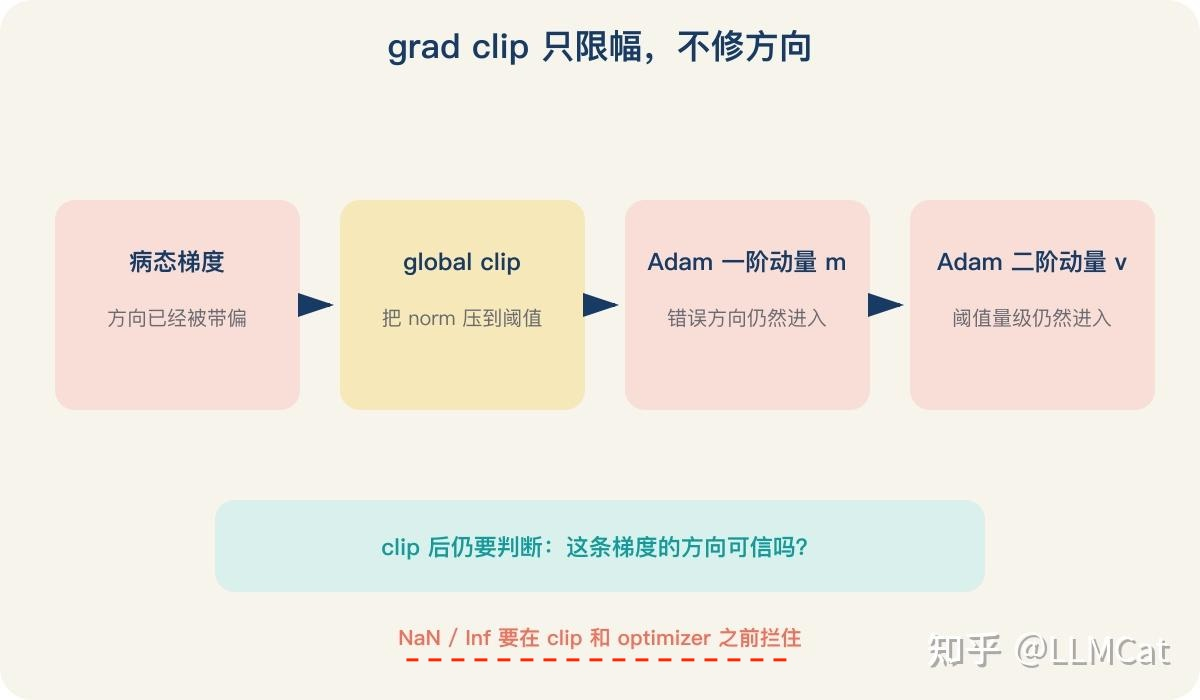

In [25]:
Image(filename='./Image/grad_clip.jpg')

### 正确的防御策略：必须建立前置“拦截器”
既然 Grad Clip 只是个“限幅器”，那我们应该怎么做？图片给出了终极解法：<font color='red'>在 Clip 和优化器之前，加入拦截器。</font>

在真实的 RLHF 或大模型训练代码中，你不能只依赖 torch.nn.utils.clip_grad_norm_。<font color='red'>你必须在反向传播（loss.backward()）和优化步（optimizer.step()）之间，加入一层极其严格的“数值健康检查”：</font>
####  拦截 NaN / Inf 和异常大值

In [ ]:
import torch.nn.utils as nn_utils

# ... 正常的前向和反向传播 ...
loss.backward()

# 在调用 clip_grad_norm_ 之前，先做拦截！
# 计算当前所有参数的梯度范数
total_norm = nn_utils.clip_grad_norm_(model.parameters(), float('inf'))

# 拦截器：如果梯度范数爆炸，或者含有 NaN/Inf，直接丢弃这一整条数据的梯度！
if torch.isnan(total_norm) or torch.isinf(total_norm) or total_norm > 10.0: 
    model.zero_grad() # 将当前所有参数的梯度清零
    continue          # 跳过该样本，不进行优化
else:
    # 梯度正常，再进行常规的限幅
    nn_utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

### Adam 通常看到的是裁剪后的梯度

在常见训练流程里，顺序是：

- backward -> unsacale -> finite check -> grad clip -> optimizer step

在强化学习（RLHF）等高稳定性要求的场景中，理解这个“数据流顺序”至关重要。因为优化器（如 Adam）内部维护的一阶和二阶动量（状态），直接决定了模型的未来走向。如果流入优化器的数据是“被污染”或“被篡改”的，模型就会崩溃。

1. Backward (反向传播)：
  - 计算原始梯度。在混合精度（FP16/BF16）训练中，为了防止小梯度溢出为 0，原始梯度通常会先被一个**放大因子**（Scale Factor, S ）放大，得到 g×S 。
2. Unscale (梯度反缩放)：
  - <font color='red'>将梯度除以放大因子，还原成 FP32 的原始梯度 g 。</font>
3. Finite Check (有限值检查)：
  - 检查梯度中是否存在 NaN (Not a Number) 或 Inf (Infinity)。<font color='red'>如果存在，说明计算崩溃，这一批的梯度必须被丢弃。</font>
4. Grad Clip (梯度裁剪)：
  - 如果梯度范数（Norm）超过预设的最大阈值（max_norm），就把梯度向量的长度截断。设截断后的梯度为 $\tilde{g}$。
5. Optimizer Step (优化器更新)：
  - <font color='red'>Adam 优化器拿到梯度，更新模型参数。</font>

核心结论：当流程走到第 5 步时，Adam 优化器“看到”并进行计算的梯度，永远是经过第 4 步“裁剪”后的$\tilde{g}$ ，而不是反向传播产生的原始 g

因此 Adam 更新一阶、二阶状态时，**读到的通常是 $\tilde{g}$，不是原始 g** 。

分布式优化器、optimizer-in-backward 或融合实现可能把几步放进同一个 kernel，但仍不能靠框架名字猜。需要确认实际代码路径中：
  - norm 在哪里计算、何时 unscale、非有限值在哪里拦截，以及 optimizer state 用的是哪一个张量。
  
####   Adam 的困境：动量（Momentum）被悄悄修改

Adam 优化器的数学公式中，一阶动量 m 和二阶动量 v 的更新公式通常写作：
- $m_t=β_1 m_{t−1} + (1−β_1)g_t$

- $v_t=β_2 v_{t−1} + (1−β_2)g^2_t$

但在实际代码中，由于 Grad Clip 的存在，公式实际上变成了：
$mt=β_1 m_{t−1} +(1−β_1)\tilde{g}t$

 
##### 这意味着什么？

<font color='red'>Adam 动量记录的历史轨迹，反映的不是模型真实的物理地形（原始梯度 g ），而是被人工强行“修剪”过的地形（ $\tilde{g}$）。</font>

如果模型在某些维度上真实地需要很大的步长来走出损失盆地，但被 Clip 强行限制成了 1.0，Adam 的动量就会误以为“这个地方坡度很缓”，从而长期保持低速前进，导致模型在某些方向上“卡死”或收敛极慢。


####  底层工程的隐藏陷阱：不要相信框架的“黑箱”
图片的后半段提出了一个极度硬核的工程警告：分布式训练和底层算子融合会打破上述的理想流水线。
在实际的大模型训练中，为了提高效率，工程师们通常会采用以下手段：
1. Distributed Optimizer（分布式优化器）：将不同参数的优化状态分散到不同的 GPU 上。
2. Optimizer-in-backward / Fused Kernels：为了减少 GPU 显存读写和通信开销，可能会把 Grad Clip 和 Optimizer Step 合并到一个 CUDA Kernel（算子）里执行。

##### 陷阱所在：
当这些步骤被压缩进一个黑箱（Kernel）时，Norm（范数）是在哪里计算的？Unscale 发生在什么时候？梯度到底是以什么名义进入优化器状态（optimizer state）的？
  - 可能 Norm 是在 FP16 下计算的，导致 Norm 被严重低估，本该裁剪的梯度没被裁剪。
  - 可能 Unscale 发生在 Clip 之后，导致传入优化器的依然是放大后的梯度。
  - 可能 Norm 的计算只包含了部分参数，而不是全局梯度。
  
##### 总结与终极建议：
图片最后的警告至关重要：“不能靠框架名字猜。需要确认实际代码路径中...以及 optimizer state 用的是哪个张量。”

在 RLHF 这样对数值极其敏感的训练中，绝对不能闭着眼睛调包。当你使用 DeepSpeed、Megatron 或 TRL 等框架时，必须深入到它们的最底层源码，画出真实的梯度数据流图，明确知道传入 Adam 的 $\tilde{g}$究竟长什么样、是在什么精度下被处理的。只有这样，你才能真正掌控模型的收敛行为。

### 有界梯度仍然可能污染动量方向
Adam 的简化更新是：

$
\begin{aligned}
m_t &= \beta_1 m_{t-1} + (1 - \beta_1) \tilde{g}_t \\
v_t &= \beta_2 v_{t-1} + (1 - \beta_2) \tilde{g}_t^2
\end{aligned}
$

clip 只保证 $|| \tilde{g} ≤ M ||$，不保证：

- 这条梯度方向与正常数据一致；
- 每个参数上的分量都处在平时的范围；
- M 相对日常 grad norm 足够小；
- 阈值以下的尖刺会被处理。

例如平时总 norm 是 0.2，一个异常 step 被裁到 1.0。在梯度形状和方向近似不变的玩具条件下，平方 norm 是平时的 25 倍；但真实 Adam 的 v 是逐参数累计的，具体污染程度取决于异常集中在哪些参数上，不能从全局 norm 直接推出每个参数都放大 25 倍。

因此应该同时记录裁剪前 norm、裁剪后 norm、命中比例和分层梯度摘要。clip 频繁触发说明训练长期依赖保险丝，应回查 advantage、loss denominator、学习率和异常 batch。

### NaN/Inf 要在 clip 之前拦住
如果总 norm 已经是 NaN，裁剪系数也可能变成 NaN；再把它乘到所有参数上，会把原本正常的梯度一起污染。

如果总 norm 是 Inf，系数可能变成 0。有限梯度会被清零，而原本的 Inf 位置执行 
 后仍可能得到 NaN。

具体行为取决于实现是否在计算系数前报错或跳步，所以最安全的要求是：optimizer 和 grad clip 之前先做 finite check。遇到非有限梯度时跳过 optimizer step，并保留 batch、rollout、reward、ratio 和 checkpoint 用于重放。

对“很大但仍有限”的梯度，可以设置异常阈值用于报警或临时隔离，但不要长期静默跳过所有困难 batch，否则训练数据会被系统性重新加权。

### Adam 的 eps 不是清除尖刺状态的旋钮
Adam 的分母近似是： $\sqrt{v_t} + \epsilon$


当尖刺已经把 $v_t$推得很大时，$\sqrt{v_t} 》\epsilon$ ，此时把 eps 从  10^{-8}改到 10^{-6}通常不会清掉已有的二阶状态。

eps 真正明显起作用的是 $v_t$很小的参数：它给分母提供数值下限。调大 eps 会减小这些参数的更新，可能提高稳定性，也可能把本来就很小的 RL 梯度进一步压弱；调小则相反。

所以结论不是“eps 应该调小”，而是：不要把 eps 当作修复大 v污染的首选旋钮。 默认值是否合适，应通过 $v_t$、实际更新量和数值精度判断。


###  “global clip 只影响 Adam 约 10%”只是一个玩具特例
如果 Adam 已在恒定梯度上达到稳态，某一步把所有梯度统一缩到接近 0，并取 $\beta_1 = 0.9$ $\beta_2 = 0.999$，忽略 bias correction 后，该步更新相对稳态的极限约为：

$\frac{\beta_1}{\sqrt{\beta_2}}  ≈ 0.9005$

这解释了为什么某些玩具实验里，把单步梯度缩小很多，Adam 更新却只少约 10%：历史动量仍占主要部分。

但它依赖“已经稳态、历史梯度恒定、当前梯度只做统一缩放、没有方向变化”等强条件。训练早期、梯度非平稳、尖刺集中在局部参数，或方向突然改变时，影响可以完全不同。

这个实验可以帮助理解 Adam 的记忆性，不能推出“global clip 在真实训练里最多只影响 10%”。真正应该监控的是裁剪前后梯度、m/v 状态和参数 delta。

## 把选择和排查压缩成一张表

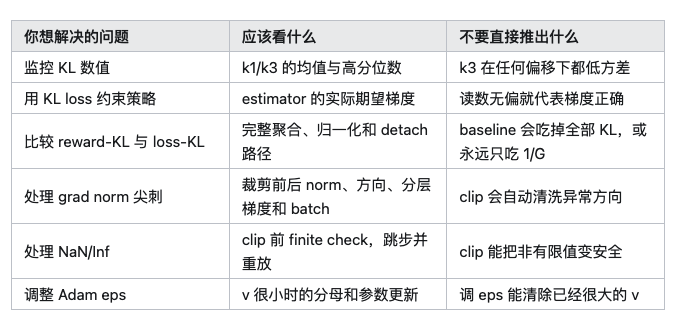

In [14]:
Image(filename='./Image/kl_list.png')

## 面试里我会怎么追问
如果候选人说“k3 最好”，我会追问：你是在讨论 KL 读数，还是把它直接当 loss 后的梯度？

如果他说“reward 里的 KL 会被减均值消掉”，我会让他写出 group baseline，看看能不能区分共享常数、sample-mean baseline 的 
 偏差和标准差归一化。

如果他说“开了 grad clip 就不会污染 Adam”，我会继续问：clip 改了梯度的长度还是方向？finite check 在 clip 前还是后？异常 batch 是报警、跳过，还是会被长期静默丢弃？

这些追问的目的不是考公式，而是判断他能不能沿着真实计算图说明每个量到底在哪里被改变。

## 总结
k1、k2、k3 要分两层看：作为 KL 读数时，关注偏差、非负性和方差；直接作为 loss 时，还要看固定采样结果求导后究竟得到哪个期望梯度。

KL 放进 reward 不会因为减 group mean 就必然失效，但它会经过序列聚合、组归一化、ratio 和 clip。KL 放进 loss 的信用分配更直接，却更依赖 estimator 与 autograd 路径是否写对。

grad clip 是限幅器，不是梯度清洗器。它通常让 Adam 读到有限、受限的梯度，却不会纠正错误方向，也不能替代非有限值检查。Adam 的 eps 主要影响小 
 区域，不是清除历史尖刺的按钮。

下一篇是系列最后一篇：怎么证明 reward 真的提供了信息，以及什么时候继续扫 RL 超参已经不划算。

# (终章)：怎么判断 reward 有效，以及何时停止调 RL

本系列文章分享 GRPO 训练排查的工程经验，以及在 post-training 岗位面试中，评估候选人底层系统排查与工程决策能力的标准。

本文为序列最后一篇，前序文章主要讨论训练异常时的底层排查链路，本文聚焦两个更上层的工程决策：

  - 指标上涨时，如何验证 reward 确实提供了有效的监督信号？
  - 指标停滞时，如何判断应当继续调整 RL 超参，还是退回补充数据、优化 SFT 或更换 base model？
  
单凭一条训练 reward 曲线无法回答上述问题。reward 上升，可能是模型能力实质提升，也可能是模型利用了判分器（verifier）的漏洞；reward 停滞，可能是优化超参配置不当，也可能是当前采样分布下根本无法命中正确轨迹。

以下先建立验证 reward 有效性的证据链，再定义终止 RL 调优的工程判据。

## “reward 有效”的四层验证标准
判定一个 reward 机制有效，需要依次满足四个层级的标准：

  - 实现正确：代码输出的数值与奖励设计规范严格一致；
  - 评价可靠：高 reward 确实对应高质量的模型输出；
  - 提供因果信息：评测指标的提升源于 reward 与输出质量之间的映射关系，而非优化器偏置、clip 机制或模型先验分布的自发漂移；
  - 能够泛化：性能提升能够迁移至未见过的测试集以及非同源的独立判分器上。
  
缺失任何一层，实验结论的置信度都会下降。

### 第一层：验证 reward 代码实现与边界条件
不应直接依赖训练阶段的总 reward 曲线来验证代码逻辑。在启动训练前，需固定一批覆盖各类边界条件（corner cases）的测试样本，逐项核验：

  - 回答正确、回答错误、格式异常以及发生长度截断（truncation）的样本分别获得多少分值；
  - 判分器超时（verifier timeout）、解析失败、进程异常退出和空输出等异常状态的计分规则；
  - 多个 reward 分项在加权求和前，各自的量纲与数值范围是否符合预期；
  - 单一分项出现 NaN 或 Inf 时的异常捕获与兜底逻辑；
  - 奖励计算作用于截断前、截断后还是正则清洗后的文本。
  
工程上建议构建一个轻量级的 reward 单元测试集。每次修改解析器（parser）、prompt 模板或判分器逻辑后自动执行回归测试，避免将计分逻辑缺陷带入训练过程。

### 第二层：验证高 reward 与高质量输出的一致性
评估输出质量需同时结合三类证据：

  - 第一，监控 reward 分项指标。 总分上升时，必须拆解具体是准确性（correctness）、格式（format）还是长度（length）分项在提供正向增量。训练早期格式分快速收敛属于正常现象；但如果准确性分项长期停滞甚至倒退，则总 reward 的上升不能代表核心能力的提升。

  - 第二，引入独立评测。 留出集（held-out set）不仅需要保证样本与训练集无交集，其判分逻辑也应尽量与训练阶段解耦。若训练 verifier 与评测 verifier 存在同源解析漏洞，held-out 评测分数同样会失真。

  - 第三，定期进行人工抽样复核。 在每个评测节点固定抽取一批基准样本，同时定向抽查当前 reward 最高、涨幅最快以及各分项分歧最大的样本。人工复核的目的并非替代统计指标，而是捕获现有监控尚未覆盖的异常模式。

上述三项检查可以确认“模型输出质量是否实质提升”，但尚不足以证明“提升是由 reward 信号直接驱动的”。

### 第三层：通过无信息对照组确立因果关系
在特定模型先验、数据分布与 GRPO 配置下，即便提供的 reward 与答案正确性完全无关，评测集准确率仍可能出现显著上升。《Spurious Rewards》 在 Qwen2.5-Math-7B 上的实验表明：使用随机 reward 进行训练，MATH-500 准确率提升了 21.4 个百分点（使用真实 ground-truth reward 的提升为 29.1 个百分点）。该研究将部分增益归因于 GRPO 的 clipping 机制放大了模型原有的高概率分布模式，且指出该现象具有显著的模型依赖性。

这一现象表明：仅对比训练前后的评测集准确率，不足以建立“reward 信号有效性”的因果闭环。

严谨的验证方案是在实验中引入匹配的对照组（baselines）：

  - 无更新对照（no-update）：冻结模型权重，仅重复执行推理与评测，用于量化采样与评测链路本身的方差；
  - 常数/无信号对照（constant/no-signal）：为所有采样轨迹赋予相同分值，用于排查 KL 散度约束、辅助损失（auxiliary loss）或底层代码实现是否在无 advantage 信号时仍会改变模型分布；
  - 奖励置换对照（shuffled reward）：保持 reward 的边际分布不变，但随机打乱分值与具体输出轨迹之间的对应关系；
  - 真实奖励实验组（true reward）：与上述对照组保持完全一致的模型底座、训练数据、采样预算、更新步数及评测协议。
  
对于采用组内相对优势（group-relative advantage）的算法，奖励置换必须在同一个 prompt 的采样组（group）内部执行。这样可以严格保持组内分值分布与非零 advantage 的幅度不变，仅破坏“特定轨迹与特定分值”的因果关联。若跨 prompt 进行全局打乱，则会将题目本身的难度差异混入对照实验中。

唯有当真实奖励组的性能稳定且显著地超越上述无信息对照组时，才能确认：reward 与输出质量之间的匹配关系提供了有效的训练信号。

此外，对照实验必须覆盖多个随机种子（seeds）。若实验组与对照组的指标差异处于多 seed 波动的同一量级，则工程结论应判定为“统计置信度不足”，而非挑选表现最好的一条曲线作为有效证据。

### 第四层：验证能力对训练判分器的泛化性
完整的实验评估报告应同步包含以下维度的指标：

  - 训练集平均 reward；
  - 同分布留出集（in-domain held-out）表现；
  - 跨分布或采用异构判分方式的基准测试集（out-of-domain / alternative verifier）表现；
  - 人工盲测或高置信度标准答案（gold label）的抽样复核结果；
  - 输出序列长度、格式合规率、拒答率以及生成多样性等监控指标。
  
若观察到训练 reward 持续上升，而独立评测指标停滞甚至劣化，应优先排查奖励过度优化（reward over-optimization）、判分器漏洞利用或分布外退化，而非盲目调整 KL 系数或学习率。

## 分离排查 Reward Hacking 与判分器缺陷
奖励机制失效通常表现为两个不同的方向：假阳性（false positive）与假阴性（false negative）。

### 假阳性（False Positive）：错误输出获得高分
即便使用基于规则或可执行环境的可验证奖励（verifiable reward），模型仍可能触发 reward hacking。例如在代码生成任务中，模型可能通过修改测试脚本、直接篡改进程退出码（exit code）、越权读取文件系统或利用沙箱环境缺陷来通过测试；在数学推理任务中，模型可能生成特定的退化格式以触发正则解析器的误判。

因此，“通过单元测试”并非验证的终点。工程上必须严格隔离代码执行沙箱的权限，并定期对高分样本进行人工代码审计，确认模型确实完成了目标计算逻辑，而非仅使验证器返回成功状态码。

### 假阴性（False Negative）：正确输出被误判为错误
假阴性在工程实践中往往更为普遍且隐蔽。例如标准答案为 
，模型输出 0.5；两者在数学语义上完全等价，但简单的字符串匹配或脆弱的解析规则会将其判定为错误。

在二值化（0/1）reward 设定下，假阴性会直接导致该条正确轨迹的 advantage 符号反转——原本应当被强化的正确推理路径反而受到梯度惩罚。其外在表征通常不是指标异常飙升，而是“无论如何调整优化器超参，准确率均无法提升”，极易误导工程师去排查优化器或模型底座问题。

标准化的排查手段是构建混淆矩阵，定期对四个象限的样本进行分层抽样：

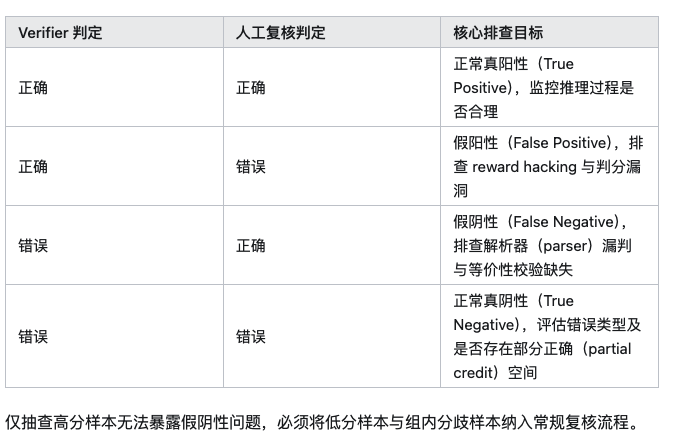

In [15]:
Image(filename='./Image/sampler.png')

## 指标停滞时，优先评估训练采样的信号覆盖率
在策略梯度（policy gradient）框架下，如果一条正确的推理轨迹在采样阶段从未被命中，模型就无法获得针对该轨迹的直接正向梯度更新。虽然参数共享机制可能使模型从其他样本的更新中获得一定的泛化迁移能力，但在有限的采样预算（rollout budget）内，不能指望 GRPO 稳定地推高一条在当前分布下从未出现过的路径。

从概率分布角度看，正确轨迹在 softmax 输出层下的理论生成概率通常大于 0，但在工程实践中，若其概率极低，在有限次数的采样中表现为有效正信号覆盖不足。

### 统计组内（Group-level）奖励分布与有效方差
在启动离线能力探针之前，首先需要对在线训练的采样日志进行统计：

  - 组内所有轨迹得分完全一致（zero-variance group）的比例；
  - 每个 prompt 对应的组内 reward 极差（range）与标准差（std）；
  - 每组样本中命中正确答案的轨迹数量分布；
  - 正确样本在不同题型与输出长度区间的分布情况；
  - 剔除格式错误、超长截断及判分超时后，实际参与梯度计算的有效样本留存率。
  
如果绝大多数采样组呈现出“全对”或“全错”的极化状态，组内归一化后的 advantage 将趋近于 0，模型无法获得有效的区分性梯度信号。此时微调 clip 阈值或学习率无法解决根本问题，应优先调整训练数据的难度分布、增加组内采样数（group size）、引入课程学习（curriculum learning）或重构数据配比。

### 采用“少题多采”量化当前预算下的命中概率上界
针对训练过程中长期“全错”的困难样本，可按题型分层抽取 10 到 20 道代表性 prompt，在严格保持训练阶段的解码配置（temperature、top-p 及最大生成长度）的前提下，对每道题独立执行大规模重复采样。

固定训练解码配置的原因在于：探针实验的目的是评估在线训练实际使用的采样分布能否覆盖正确轨迹。提高采样温度（temperature）可以作为评估模型潜在知识储备的第二阶段探索实验，但不能替代训练分布下的基线测试。

若针对同一道题目独立采样 
 次仍未出现任何一次正确回答，在近似独立同分布（i.i.d.）假设及 95% 置信水平下，可根据统计学的“三倍法则”（Rule of Three）估算该题单次采样成功率的统计上界：

$p \lesssim \frac{3}{n}$

例如，连续采样 512 次均失败，仅能证明当前配置下该题的单次命中概率上界约为 3/512 ≈ 0.6%，并不能在数学上证明模型绝对不具备解决该问题的能力。同时，该统计推论的有效性依赖于采样过程的独立性以及判分器（verifier）不存在假阴性漏判。

在实验设计上，“少题多采”（减少题目数量、增加单题采样次数）旨在提高单题命中率估计的统计分辨率；“多题少采”则侧重于评估跨题型的覆盖广度。排查信号缺失问题时，应先按任务类型分层，再对少量代表性样本执行高倍率采样。

### 基于探针结果的分流决策

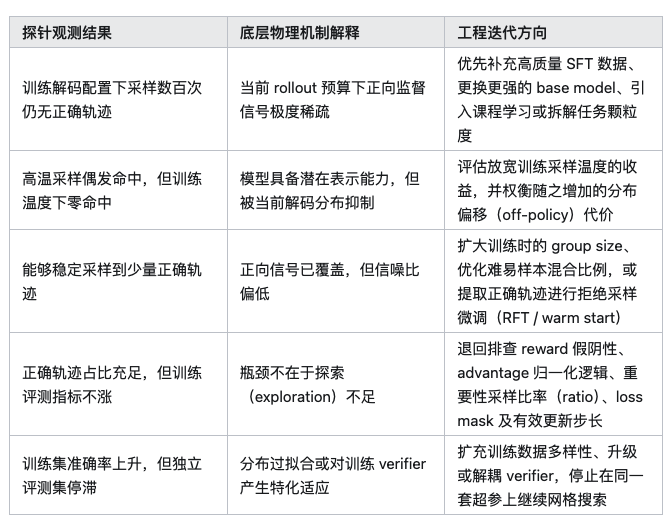

In [16]:
Image(filename='./Image/desine.png')

“数百次采样零命中”并非绝对的终止红线。是否继续投入算力强行采样，取决于目标任务的商业价值、可用算力规模，以及是否具备通过 SFT 或蒙特卡洛树搜索（MCTS）降低探索难度的替代方案。但该探针结果明确指示：在当前模型底座与采样预算下，仅靠维持现有 RL 配置难以通过自发探索获得有效梯度。

## 终止当前 RL 调优配方的工程判据
在工程管理中，“停止调 RL”并不意味着放弃当前业务目标，而是基于投入产出比（ROI）做出判断：下一单位的算力与工程时间，不应再消耗在同一种 RL 超参组合或同一套数据配方上。

做出终止决策前，需确保以下四个前置层级已依次通过验证：

  - 工程实现层已闭环：新旧策略的 logprob 对齐、padding/prompt mask、梯度累积缩放系数以及混合精度数值链路均已通过单元测试；
  - 奖励评估层已闭环：判分器的假阳性与假阴性率控制在可接受范围内，且真实 reward 组显著优于无信息对照组；
  - 采样信号层已闭环：在线训练的采样组内存在充足的非零 advantage 样本与正确推理轨迹；
  - 实验对比层已执行：在固定其他变量的条件下，完成了核心超参的单变量消融与多 seed 验证，仍未观测到超越随机波动的稳定增益。
  
若前三个层级存在未修复的缺陷，任何超参搜索的结果都缺乏可解释性；若前三个层级均已确认无误，而第四层级的单变量实验连续失效，则表明当前 RL 配方的边际收益已耗尽，应立即切换技术路线。

### 预先定义量化停止条件（Stopping Criteria）
为避免陷入无休止的试错，应在启动大规模训练前将停止条件明确写入实验方案：

  - 单次实验允许消耗的最大算力预算（GPU hours）或物理时间（wall-clock time）；
  - 核心目标评测集，以及绝对不允许退化的基线护栏指标（如安全性、代码编译通过率、基础指令遵循率）；
  - 相对于无更新基线（no-update）、随机 reward 对照组或上一代最优模型，判定实验有效的最小指标提升幅度（Minimum Detectable Effect）；
  - 确立结论所需的最小随机种子（seeds）数量；
  - 评测指标连续多少个检查点（checkpoints）无正向增益即触发早停（early stopping）；
  - 触发退回修改 SFT、清洗数据或重构 verifier 的具体异常表征（如格式坍缩、长度失控）。
上述阈值因具体业务场景而异，但必须在观测到实验结果之前预先锁定，防止在指标停滞时通过事后调整评估标准来延续无效实验。

### 状态诊断与工程分流表

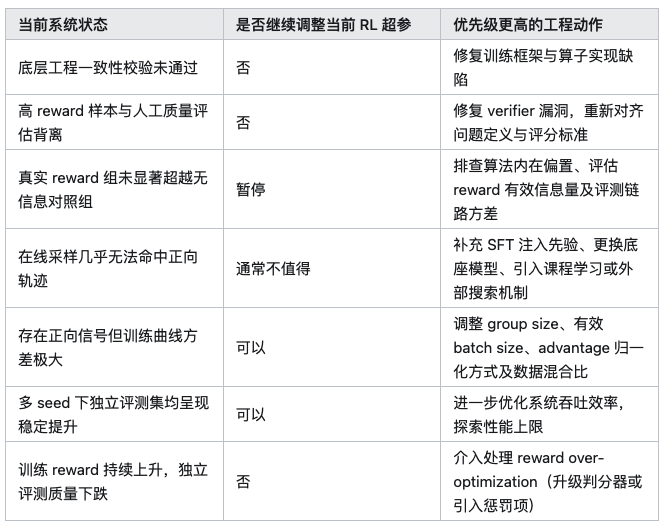

In [17]:
Image(filename='./Image/status.png')

## GRPO 系统调优的工程优先级

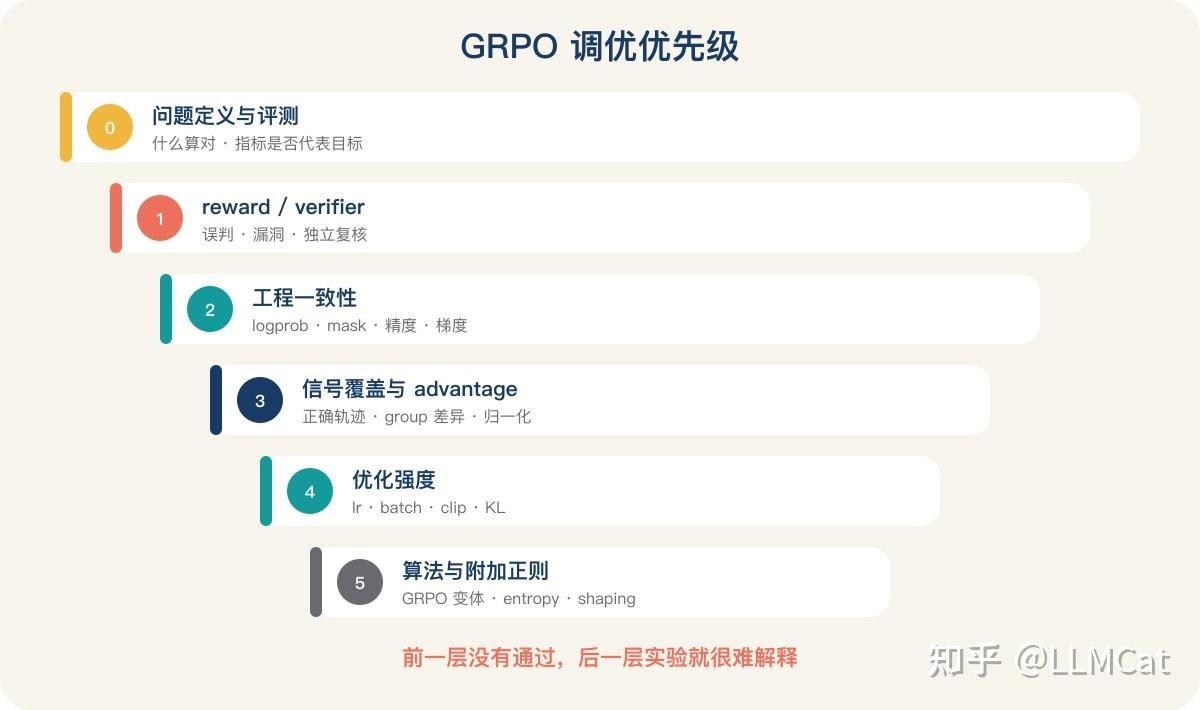

In [18]:
Image(filename='./Image/steps.jpg')

在排查与优化 GRPO 训练任务时，建议严格按照以下优先级分配工程精力：

1. 问题定义与评测基准：明确任务正确的标准、规范输出格式约束，确认核心评测指标能够真实反映业务目标；
2. Reward 与 Verifier 可靠性：消减假阳性与假阴性误判、封堵沙箱与解析漏洞、对齐各分项量纲，并建立独立复核机制；
3. 底层工程一致性：核验采样与训练两侧的 logprob 一致性、序列 mask 边界、跨卡梯度归约（all-reduce）尺度、数值精度以及推理引擎权重同步链路；
4. 信号覆盖率与 Advantage 构造：监控组内方差、评估正确轨迹采样命中率，审视组内归一化或样本过滤逻辑是否扭曲了样本权重；
5. 优化器与更新强度控制：调整学习率（learning rate）、全局 batch size、样本复用轮数（epochs per rollout）、PPO clip 阈值、KL 惩罚系数及梯度裁剪（grad clip）上限；
6. 算法变体与附加正则项：尝试不同的 GRPO 损失变体、引入熵正则（entropy bonus）或设计更复杂的密集奖励（reward shaping）。

设定这一优先级的逻辑在于：系统的底层依赖决定了上层实验的可解释性。当前置链路存在偏差时，在算法变体或超参搜索上投入算力无法得出可靠的因果结论。

以组内优势归一化（advantage normalization）为例，工程上不存在绝对普适的默认配置。将优势值除以组内标准差（std），会动态改变不同采样组的有效梯度权重，可能放大组内分差极小样本的噪声，或引入非预期的题目难度偏置；而不除以标准差，则会使原始 reward 的绝对尺度直接作用于梯度步长。两种方案各有代价，必须结合具体的组内 std 分布、题目难度跨度、实际梯度范数以及消融实验结果进行取舍。

同理，调整 clip 阈值、KL 系数或 entropy bonus 也必须以明确的监控证据为前提。观测到策略熵（entropy）下降，并不意味着必须立即叠加 entropy bonus；观测到截断比例（clip fraction）升高，也不直接等价于 clip 边界设置过窄。在调整超参前，应首先确认这些指标变化源于正常的策略分布收敛，而非训推两侧数值不一致、陈旧样本（stale data）堆积或异常的 advantage 尖峰。

## 本套诊断框架的适用边界
  - 第一，本文讨论的排查方法主要针对基于规则（rule-based）或可执行判分器（verifier）的场景。若系统采用神经网络奖励模型（Reward Model）或 LLM-as-a-Judge，还需额外监控评分模型在策略分布漂移后的分布外（OOD）泛化可靠性，并持续追踪代理奖励（proxy reward）与人工黄金标准（gold standard）之间的校准误差。

  - 第二，在多轮交互智能体（multi-turn agent）任务中，最终奖励往往延迟到整条长轨迹结束时才稀疏给出。本文基于单轮生成的组内统计方法，无法完全解决跨轮次的信用分配（credit assignment）、外部工具调用异常以及环境状态转换随机性等问题。

  - 第三，随机奖励对照、少题多采探针以及统计学“三倍法则”均为工程诊断工具，不能脱离上下文作为绝对判据。无信息对照组的表现受模型底座先验与优化算法偏置的显著影响；能力探针的命中率高度依赖于解码温度等超参设置；而概率上界估算则严格受制于样本独立性假设与 verifier 的准确率。

  - 第四，单次实验得出的具体数值仅对该次特定的模型、数据与超参组合有效。当切换模型底座、更新数据集版本、改变随机种子或调整评测协议后，必须重新执行基线测量，切忌将特定场景下的经验数值固化为跨任务的通用阈值。
  
## 面试评估视角：如何考察候选人的工程决策能力

在面试 post-training 方向的候选人时，针对“训练指标异常”的场景题可以有效区分其工程深度。

当给定“reward 长期不涨”的场景时，若候选人仅回答“调小学习率、增大 group size”，面试官通常会进一步追问：底层工程一致性校验通过了吗？当前采样组内是否存在非零 advantage？在训练温度下模型能否采样到正确轨迹？

当给定“reward 显著上涨”的场景时，核心追问方向则是：非同源的独立评测集是否同步上涨？假阳性和假阴性样本各自抽检了多少比例？是否设立了无信号（no-signal）或置换对照组？实验收益是否显著超越了多 seed 的随机波动？

具备扎实一线经验的工程师在面对复杂训练问题时，通常不会在缺乏上下文的情况下直接给出修改某项超参的断言，而是优先向系统索取各个层级的诊断证据。他们清楚何时应当继续在现有 RL 框架内深挖优化潜力，何时应当果断止损，将问题退回至数据清洗、SFT 注入、底座模型升级或判分器重构——避免将所有系统性瓶颈都归咎于强化学习算法本身。

## 总结
验证 reward 机制的有效性，需要依次确立代码实现正确、质量评价可靠、具备真实因果增益以及跨分布泛化四个层级的证据。拆解分项指标、设置独立留出集与定期人工复核是基础保障，而引入无信号或组内奖励置换对照组，则是剥离算法与模型先验偏置、证明 reward 自身有效性的关键手段。

当训练指标停滞时，应优先统计组内 reward 的有效方差，并在训练解码配置下执行“少题多采”探针。连续零次命中可用于估算当前采样预算下的成功概率上界，辅助判断瓶颈是否在于探索信号极度稀疏。

当底层工程链路、判分器可靠性以及采样信号覆盖率均已验证通过，而多 seed 下的单变量消融实验仍无法带来稳定的正向收益时，继续在同一套 RL 配方上进行超参搜索的边际价值已趋近于零。此时将工程重心转向 SFT 数据补充、底座模型迭代、外部搜索增强或重新对齐问题定义，是更高投入产出比的工程决策。

浓缩整个系列的排查方法论，最核心的工程原则只有一条：

先验证梯度计算链路的数值正确性，再验证 reward 引导方向的业务正确性；唯有这两项前提同时成立，后续的算法调优与超参搜索才具备工程意义。